# Homes on Dangerous Streets?
## Affordable Housing and Serious Traffic Crashes in New York City (2022–2025)

**Data Engineering and Visualization, Winter Semester 2026: Project Milestone 1**
German International University, Faculty of Informatics and Computer Science

| Role | Member | ID | Main sections |
|---|---|---|---|
| M1: Lead & Integration | *(name)* | *(ID)* | 1, 2, 8, 9, RQ1–RQ2 |
| M2: Housing data | *(name)* | *(ID)* | 3, 5, RQ3–RQ4 |
| M3: Transport data | *(name)* | *(ID)* | 4, 6, RQ5–RQ6 |
| M4: Website logic | *(name)* | *(ID)* | 11, website callbacks, RQ7–RQ8 |
| M5: Website visuals & deployment | *(name)* | *(ID)* | website layout & deployment, RQ9–RQ10 |
| M6: Story & documentation | *(name)* | *(ID)* | 7, 12, 13, 14, RQ11–RQ12 |

**Website:** `https://<your-service>.onrender.com` *(add after deployment)* · **Repository:** `https://github.com/<team>/<repo>` *(add)*

**Our question in one sentence:** *New York City builds thousands of affordable homes every year. Are these homes being built next to the city's most dangerous streets?*

### How to run this notebook
1. Open it in Google Colab (or Jupyter) and run all cells from top to bottom (**Runtime → Run all**).
2. The first run downloads both datasets from the NYC Open Data API. Every later run uses the saved copy in `data/raw/`, so all numbers in our text stay the same.
3. The last section saves the clean tables in `data/clean/`. The website reads these files.

### Table of contents
1. Project overview and dataset choice
2. Extract: loading the data from the API
3. EDA: Affordable Housing dataset
4. EDA: Serious crashes (SIRTA) dataset
5. Pre-integration cleaning: housing
6. Pre-integration cleaning: crashes
7. Checking that the cleaning worked
8. Integration
9. Post-integration cleaning
10. Research questions (12 questions, 12 charts)
11. Load: saving clean tables for the website
12. Story, limitations and "so what?" for NYC
13. Team contributions
14. Prompts log

---
# 1. Project overview and dataset choice *(M1)*

We follow the **ETL** process from Lecture 1, and the scraping pipeline from Lab 1 adapted to an API:

| Lab 1 pipeline (web scraping) | Our pipeline (NYC Open Data API) |
|---|---|
| Access a web page → `requests` | Call the API URL → `requests` |
| Parse the HTML → BeautifulSoup | Read the CSV response → `pandas` |
| Inspect what to scrape → DevTools | Read the column list and data dictionary on NYC Open Data |
| Data table → store & process → plot | DataFrame → clean & integrate → plot and website |

**Why not web scraping?** NYC Open Data gives an official API with clean, structured columns. Scraping is only needed when no API exists, and using the API is what the site's terms of use intend.

### The two datasets

| | Housing: **Affordable Housing Production by Building** | Transportation: **Serious Injury Response, Tracking & Analysis Program (SIRTA)** |
|---|---|---|
| Catalog ID | H2 | T4 |
| Agency | Department of Housing Preservation and Development (HPD) | Department of Transportation (DOT) |
| Link | https://data.cityofnewyork.us/d/hg8x-zxpr | https://data.cityofnewyork.us/d/xeqp-qz8h |
| One row is | one building in one affordable-housing project | one serious crash (at least one severe injury or death) |
| Size | 9,551 rows × 41 columns | 12,947 rows × 23 columns |
| Time | projects started 2014 to 2026 | crashes January 2022 to March 2026 |
| Geography | borough, ZIP code, community board, latitude/longitude | borough, police precinct, ZIP code, latitude/longitude |
| Known issues (found in EDA) | hidden missing values ("CONFIDENTIAL", "----"), mostly-empty unit columns, very skewed sizes, Excel-corrupted addresses | 444 broken records, ZIP missing for 84% of 2022 crashes, placeholder ZIP and time, no coordinates for fatal crashes after 2022 |

### Why we chose this pair
1. **Both are in the catalog**, so no feasibility check is needed.
2. **They share three integration fields**: ZIP code, borough and coordinates. They also share time (completion date and crash date).
3. **Both are small enough to use completely** (about 9,500 and 13,000 rows). We use the **whole population**, not a sample (Lecture 3), so there is no sampling bias.
4. **They have real data-quality problems** (hidden missing values, broken records, corrupted addresses, missing ZIP codes). This lets us show every cleaning method from Lab 2.
5. **The story matters for the city.** If new affordable homes are built next to dangerous streets, the people who moved in, often low-income families, face that danger every day. DOT can redesign those streets.

**Different granularities:** a building and a crash are different kinds of events, so their rows cannot be matched one to one. We **aggregate both to ZIP code × year** and also **measure distances** between buildings and crashes (Section 8 explains and justifies both).

**A limitation we state from the start:** SIRTA only contains *serious* crashes (severe injury or death). Our story is about **dangerous streets**, not about all traffic.

---
# 2. Extract: loading the data from the API *(M1)*

We download both datasets with `requests`, like Lab 1.
- The parameter `$limit=50000` is larger than both datasets, so we receive **every row**. Neither dataset is sampled.
- We save a raw copy (a *snapshot*) in `data/raw/`. The datasets are updated every few months, so a fixed snapshot means every member and the TAs get the same numbers as our text.
- To download fresh data, set `REFRESH_FROM_API = True`.

In [1]:
# --- Standard libraries ---
import io
import os
import re
import warnings

# --- Data and statistics ---
import numpy as np
import pandas as pd
import requests
from scipy import stats
from sklearn.neighbors import BallTree, KNeighborsClassifier

# --- Plotting (same libraries as Labs 1 and 2) ---
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
%matplotlib inline

In [2]:
# ---------------------------------------------------------------
# One visual style for every chart in the notebook.
# The same colors are used on the website, so a reader always
# sees the same color for the same meaning (Gestalt: similarity).
# The 3 accent colors were checked for colorblind safety.
# ---------------------------------------------------------------
BLUE = "#2a78d6"    # main color: housing / "near new affordable housing"
ORANGE = "#eb6834"  # second color: crashes / "double hotspot"
AQUA = "#1baf7a"    # third color (used rarely)
GRAY = "#b5b3ab"    # "everything else" (de-emphasis)
INK = "#0b0b0b"
INK_SOFT = "#52514e"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
RED = "#e34948"     # negative side of diverging scales
DIVERGING_MID = "#f0efec"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BOROUGH_ORDER = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
    "font.family": "sans-serif", "font.size": 10, "legend.frameon": False,
    "figure.dpi": 100,
})


def finish_chart(ax, title, xlabel=None, ylabel=None, source=True):
    """Apply the same title, axis labels and source note to every chart."""
    ax.set_title(title)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if source:
        ax.figure.text(0.01, -0.02, "Source: NYC Open Data (HPD Affordable Housing Production; DOT SIRTA)",
                       fontsize=8, color=INK_SOFT, ha="left")
    ax.figure.tight_layout()

In [3]:
# ---------------------------------------------------------------
# Extract step
# ---------------------------------------------------------------
API_BASE_URL = "https://data.cityofnewyork.us/resource/{dataset_id}.csv"
HOUSING_DATASET_ID = "hg8x-zxpr"   # Affordable Housing Production by Building
CRASH_DATASET_ID = "xeqp-qz8h"     # SIRTA serious crashes
RAW_DIR = "data/raw"
CLEAN_DIR = "data/clean"
REFRESH_FROM_API = False           # True = download a fresh copy from the API

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(CLEAN_DIR, exist_ok=True)


def fetch_from_api(dataset_id, row_limit=50_000):
    """Download one NYC Open Data dataset as CSV through the Socrata API.

    row_limit is larger than the dataset, so the full dataset is returned (no sampling).
    """
    url = API_BASE_URL.format(dataset_id=dataset_id)
    response = requests.get(url, params={"$limit": row_limit}, timeout=120)
    response.raise_for_status()                      # stop with a clear error if the API fails
    return pd.read_csv(io.StringIO(response.text), low_memory=False)


def load_raw_dataset(dataset_id, file_name):
    """Use the saved snapshot if it exists; otherwise download it and save it."""
    path = os.path.join(RAW_DIR, file_name)
    if os.path.exists(path) and not REFRESH_FROM_API:
        source = f"saved snapshot {path}"
    else:
        fetch_from_api(dataset_id).to_csv(path, index=False)
        source = f"NYC Open Data API ({dataset_id}), saved to {path}"
    df = pd.read_csv(path, low_memory=False)
    print(f"Loaded {len(df):,} rows x {df.shape[1]} columns from {source}")
    return df


housing_raw = load_raw_dataset(HOUSING_DATASET_ID, "housing_raw.csv")
crashes_raw = load_raw_dataset(CRASH_DATASET_ID, "sirta_raw.csv")

Loaded 9,551 rows x 41 columns from saved snapshot data/raw/housing_raw.csv
Loaded 12,947 rows x 23 columns from saved snapshot data/raw/sirta_raw.csv


**Note on column names:** the API uses short field names (for example `postcode`, `all_counted_units`). The "Export" button on the website gives longer display names ("Postcode", "All Counted Units"), so we always use the API.

**Note on data types:** a CSV file stores everything as text. pandas guesses the types, and it guesses wrong for some columns (dates stay text, ZIP codes become decimals like `11432.0`). We fix the types during cleaning (Sections 5 and 6), like the "change data type" step in Lab 3 (Power Query).

---
# 3. EDA: Affordable Housing dataset *(M2)*

We follow the EDA order from Lab 1: **structure → summary statistics → missing values → unique values → hidden missing values → duplicates → distributions → relationships**.

### 3.1 Structure

In [4]:
print("Shape (rows, columns):", housing_raw.shape)
housing_raw.head(3).T

Shape (rows, columns): (9551, 41)


,0,1,2
project_id,68872,72436,72449
project_name,177-06 WEXFORD TERRACE,ST. NICK'S. 819 GRAND STREET,BREMOND KING DAVIS.YR15.FY26
project_start_date,2026-06-30T00:00:00.000,2026-06-30T00:00:00.000,2026-06-30T00:00:00.000
project_completion_date,NaN,NaN,NaN
building_id,991637.0,1021347.0,21199.0
house_number,177-06,819,127
street_name,WEXFORD TERRACE,GRAND STREET,EDGECOMBE AVENUE
borough,Queens,Brooklyn,Manhattan
postcode,11432.0,11211.0,10030.0
bbl,4098350023.0,3029220001.0,1020480037.0


In [5]:
housing_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   project_id                     9551 non-null   int64  
 1   project_name                   9551 non-null   object 
 2   project_start_date             9551 non-null   object 
 3   project_completion_date        7732 non-null   object 
 4   building_id                    7602 non-null   float64
 5   house_number                   9551 non-null   object 
 6   street_name                    9551 non-null   object 
 7   borough                        9551 non-null   object 
 8   postcode                       7593 non-null   float64
 9   bbl                            7530 non-null   float64
 10  bin                            7530 non-null   float64
 11  community_board                9551 non-null   object 
 12  council_district               9551 non-null   i

**What we see:**
- 9,551 rows and 41 columns. Each row is **one building inside one project** (HPD's definition), so the same building can appear more than once if it joined several projects.
- Dates (`project_start_date`, `building_completion_date`) are stored as text, so they must be converted.
- `postcode` is a decimal number (`11432.0`). A ZIP code is a label, not a quantity, so it must become text.

### 3.2 Data types (Lecture 2)

| Column | Type of data | Why |
|---|---|---|
| `borough`, `postcode`, `community_board`, `reporting_construction_type` | Nominal | Names or labels with no order |
| Income bands (extremely low → middle income) | Ordinal | Ordered categories (from 0–30% to 121–165% of area median income) |
| `project_start_date`, `building_completion_date` | Interval | Dates: differences make sense, but "twice a date" does not |
| `total_units`, `all_counted_units`, bedroom counts | Ratio | Counts with a true zero ("200 units is twice 100 units") |

### 3.3 Summary statistics

In [6]:
HOUSING_UNIT_COLUMNS = ["total_units", "all_counted_units", "counted_rental_units", "counted_homeownership_units",
                        "extremely_low_income_units", "very_low_income_units", "low_income_units",
                        "moderate_income_units", "middle_income_units"]
housing_raw[HOUSING_UNIT_COLUMNS].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
total_units,9551.0,46.7,92.5,1.0,3.0,12.0,45.0,1320.0
all_counted_units,9522.0,33.7,65.8,1.0,2.0,8.0,30.0,917.0
counted_rental_units,6944.0,37.4,63.8,1.0,5.0,13.0,41.0,917.0
counted_homeownership_units,2730.0,22.3,68.3,1.0,1.0,1.0,2.0,489.0
extremely_low_income_units,2081.0,28.3,44.6,1.0,2.0,8.0,37.0,429.0
very_low_income_units,3400.0,25.5,49.3,1.0,3.0,7.0,21.0,453.0
low_income_units,5505.0,19.8,40.7,1.0,1.0,5.0,19.0,536.0
moderate_income_units,1694.0,11.6,30.3,1.0,1.0,3.0,8.0,454.0
middle_income_units,2691.0,16.9,34.5,1.0,3.0,6.0,15.0,448.0


In [7]:
housing_raw.select_dtypes(exclude="number").describe().T     # text columns (works in pandas 2 and 3)

,count,unique,top,freq
project_name,9551,3979,CONFIDENTIAL,1949
project_start_date,9551,2346,2021-06-30T00:00:00.000,141
project_completion_date,7732,2066,2019-06-20T00:00:00.000,103
house_number,9551,3154,----,1949
street_name,9551,1567,----,1949
borough,9551,5,Brooklyn,3649
community_board,9551,59,BK-05,576
neighborhood_tabulation_area,7593,168,BK82,358
building_completion_date,7885,2242,2019-06-20T00:00:00.000,103
reporting_construction_type,9551,2,Preservation,4785


**What we see:**
- Units per building are **strongly right-skewed**. The median building has 12 units, but the mean is 46.7 and the largest has 1,320. Most buildings are small homes, and a few are very large towers.
- Because of this skew, we describe "typical" buildings with the **median**, not the mean (Lecture 3).
- The top `project_name` value is **"CONFIDENTIAL"** (1,949 rows). This is a hidden missing value, checked in 3.5.

### 3.4 Missing values

In [8]:
def missing_value_table(df):
    """Count and percentage of empty cells per column, largest first."""
    table = pd.DataFrame({
        "missing": df.isna().sum(),
        "percent": (df.isna().mean() * 100).round(1),
    })
    return table[table["missing"] > 0].sort_values("missing", ascending=False)


housing_missing = missing_value_table(housing_raw)
housing_missing

,missing,percent
_6_br_units,9524,99.7
_5_br_units,9478,99.2
_4_br_units,8990,94.1
unknown_br_units,8862,92.8
other_income_units,8191,85.8
moderate_income_units,7857,82.3
extremely_low_income_units,7470,78.2
middle_income_units,6860,71.8
counted_homeownership_units,6821,71.4
studio_units,6353,66.5


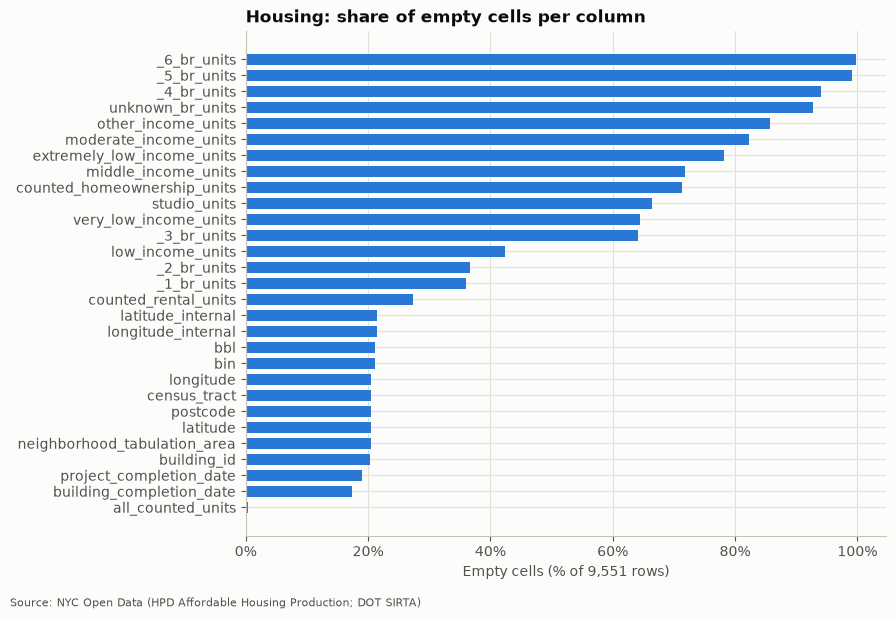

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(housing_missing.index, housing_missing["percent"], color=BLUE, height=0.7)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="x", visible=True)
finish_chart(ax, "Housing: share of empty cells per column", "Empty cells (% of 9,551 rows)")
plt.show()

**What we see:** the missing values fall into three groups, and each group needs a different decision (Section 5):
1. **Unit columns by income band and bedroom size (up to 99% empty).** Our hypothesis: empty means *zero units*, not *unknown*. Evidence: no unit column ever contains a 0 (the smallest value is 1), so HPD leaves the cell empty instead of writing 0. We test this in 3.6.
2. **Location columns (ZIP, coordinates, BBL; about 20% empty).** These are almost all the CONFIDENTIAL projects.
3. **Completion dates (17–19% empty).** These projects are **not finished yet**. The value is not lost; the event has not happened.

### 3.5 Hidden missing values (the "?" lesson from Lab 1)

In Lab 1, the Adult dataset used `"?"` for missing values, so `isna()` showed zero missing values. We look for the same problem here.

In [10]:
def count_disguised_missing(df, markers):
    """Count cells that hold a placeholder instead of a real value.

    markers: dict {column: list of placeholder values}.
    """
    rows = []
    for column, values in markers.items():
        rows.append({"column": column, "placeholder": ", ".join(map(str, values)),
                     "cells": int(df[column].isin(values).sum())})
    return pd.DataFrame(rows)


PLACEHOLDER_BINS = [1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000]  # borough digit + zeros
count_disguised_missing(housing_raw, {
    "project_name": ["CONFIDENTIAL"],
    "house_number": ["----"],
    "street_name": ["----"],
    "bin": PLACEHOLDER_BINS,
})

,column,placeholder,cells
0,project_name,CONFIDENTIAL,1949
1,house_number,----,1949
2,street_name,----,1949
3,bin,"1000000, 2000000, 3000000, 4000000, 5000000",482


In [11]:
is_confidential = housing_raw["project_name"].eq("CONFIDENTIAL")
print("Confidential rows:", is_confidential.sum())
print("  ... with a ZIP code:     ", housing_raw.loc[is_confidential, "postcode"].notna().sum())
print("  ... with coordinates:    ", housing_raw.loc[is_confidential, "latitude"].notna().sum())
print("  ... with a borough:      ", housing_raw.loc[is_confidential, "borough"].notna().sum())
print("  ... with a community board:", housing_raw.loc[is_confidential, "community_board"].notna().sum())
print("  ... affordable units in total:", int(housing_raw.loc[is_confidential, "all_counted_units"].sum()))
print("Non-confidential rows without a ZIP:", housing_raw.loc[~is_confidential, "postcode"].isna().sum())

Confidential rows: 1949
  ... with a ZIP code:      0
  ... with coordinates:     0
  ... with a borough:       1949
  ... with a community board: 1949
  ... affordable units in total: 2805
Non-confidential rows without a ZIP: 9


**What we see:**
- **1,949 CONFIDENTIAL rows** have no address, ZIP or coordinates, but they **do** have a borough and community board. HPD hides the exact address to protect the privacy of homeowners (most are 1-unit homes, only 2,805 units in total). We can still use them for **borough-level** charts.
- **482 building IDs (BIN) are placeholders** such as `3000000` (borough digit + zeros), meaning "unknown building".
- Almost all missing ZIP codes come from confidential rows (only 9 others).

One more hidden problem: some **house numbers were corrupted by Excel into dates**. Queens addresses use a hyphen (for example "10-44 Jackson Avenue"), and Excel turned "10-44" into "Oct-44".

In [12]:
MONTHS = "Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec"
excel_date_pattern = rf"^(?:(?:{MONTHS})-\d+|\d+-(?:{MONTHS}))$"
corrupted_house_numbers = housing_raw["house_number"].str.match(excel_date_pattern, na=False)
print("House numbers turned into dates by Excel:", corrupted_house_numbers.sum())
housing_raw.loc[corrupted_house_numbers, ["house_number", "street_name", "borough"]].head(6)

House numbers turned into dates by Excel: 31


,house_number,street_name,borough
8,20-Oct,BEACH 19 STREET,Queens
304,Feb-65,WATJEAN COURT,Queens
779,Oct-32,BAY 24 STREET,Queens
1001,Apr-34,26 AVENUE,Queens
1002,Apr-42,26 AVENUE,Queens
1003,11-Aug,26 AVENUE,Queens


### 3.6 Testing the "empty means zero" hypothesis for unit columns

If an empty unit cell really means 0, then after filling it with 0 the income bands must add up **exactly** to `all_counted_units` in every row. The same must be true for the bedroom sizes and for rental + homeownership.

In [13]:
INCOME_BAND_COLUMNS = ["extremely_low_income_units", "very_low_income_units", "low_income_units",
                       "moderate_income_units", "middle_income_units", "other_income_units"]
BEDROOM_COLUMNS = ["studio_units", "_1_br_units", "_2_br_units", "_3_br_units", "_4_br_units",
                   "_5_br_units", "_6_br_units", "unknown_br_units"]
TENURE_COLUMNS = ["counted_rental_units", "counted_homeownership_units"]

has_total = housing_raw["all_counted_units"].notna()
checks = {
    "Income bands add up to all_counted_units": housing_raw[INCOME_BAND_COLUMNS].fillna(0).sum(axis=1),
    "Bedroom sizes add up to all_counted_units": housing_raw[BEDROOM_COLUMNS].fillna(0).sum(axis=1),
    "Rental + homeownership add up to all_counted_units": housing_raw[TENURE_COLUMNS].fillna(0).sum(axis=1),
}
for name, row_sums in checks.items():
    match_rate = (row_sums[has_total] == housing_raw.loc[has_total, "all_counted_units"]).mean() * 100
    print(f"{name}: {match_rate:.1f}% of rows")
print("Zeros stored anywhere in these columns:",
      int((housing_raw[INCOME_BAND_COLUMNS + BEDROOM_COLUMNS + TENURE_COLUMNS] == 0).sum().sum()))
print("Rows where all_counted_units is empty:", (~has_total).sum(),
      "| their income bands add up to:", housing_raw.loc[~has_total, INCOME_BAND_COLUMNS].fillna(0).sum().sum())

Income bands add up to all_counted_units: 100.0% of rows
Bedroom sizes add up to all_counted_units: 100.0% of rows
Rental + homeownership add up to all_counted_units: 100.0% of rows
Zeros stored anywhere in these columns: 0
Rows where all_counted_units is empty: 29 | their income bands add up to: 0.0


**Result:** after filling empty cells with 0, the parts add up **exactly (100%)** to the total in every row, and no zero is stored anywhere. This proves that **empty = 0 units**. The 29 rows with an empty `all_counted_units` also have no units in any band, so they are zero too.

### 3.7 Duplicates (Lecture 1: "always remove duplicates?")

In [14]:
print("Fully duplicated rows:", housing_raw.duplicated().sum())
print("Repeated (project, building) pairs:", housing_raw.duplicated(["project_id", "building_id"]).sum())
print("Building IDs that appear in more than one project:", housing_raw["building_id"].dropna().duplicated().sum())

Fully duplicated rows: 0
Repeated (project, building) pairs: 0
Building IDs that appear in more than one project: 124


**What we see:** there are **no true duplicates**. 124 buildings appear in more than one project (for example, preserved in 2016 and again in 2023). These are **different events**, and HPD counts the units toward each project, so we **keep** them. This answers the Lecture 1 question: duplicates should not always be removed.

### 3.8 Distributions

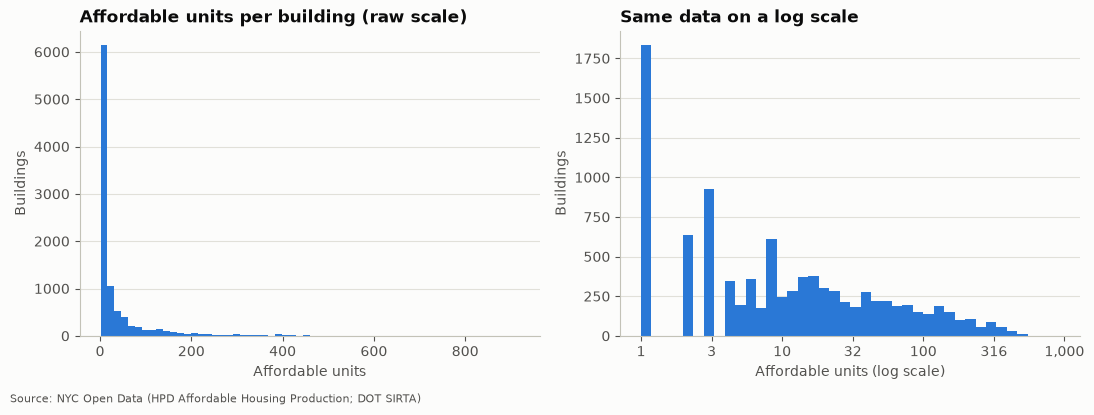

Skewness of all_counted_units: 3.68


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(housing_raw["all_counted_units"].dropna(), bins=60, color=BLUE)
finish_chart(axes[0], "Affordable units per building (raw scale)", "Affordable units", "Buildings", source=False)
axes[1].hist(np.log10(housing_raw["all_counted_units"].dropna()), bins=40, color=BLUE)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{10 ** v:,.0f}"))
finish_chart(axes[1], "Same data on a log scale", "Affordable units (log scale)", "Buildings")
plt.show()
print("Skewness of all_counted_units:", round(housing_raw["all_counted_units"].skew(), 2))

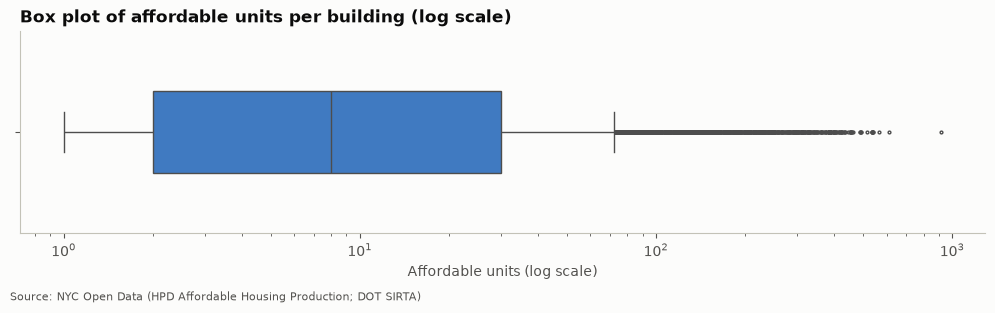

In [16]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=housing_raw["all_counted_units"], color=BLUE, fliersize=2, ax=ax, width=0.4)
ax.set_xscale("log")
finish_chart(ax, "Box plot of affordable units per building (log scale)", "Affordable units (log scale)")
plt.show()

**What we see:** a skewness of 3.7 means a long right tail. On the log scale the shape becomes readable: most buildings have between 1 and 100 affordable units. We show the histogram **and** the box plot, because a box plot alone can hide the shape of a distribution (Lecture 4).

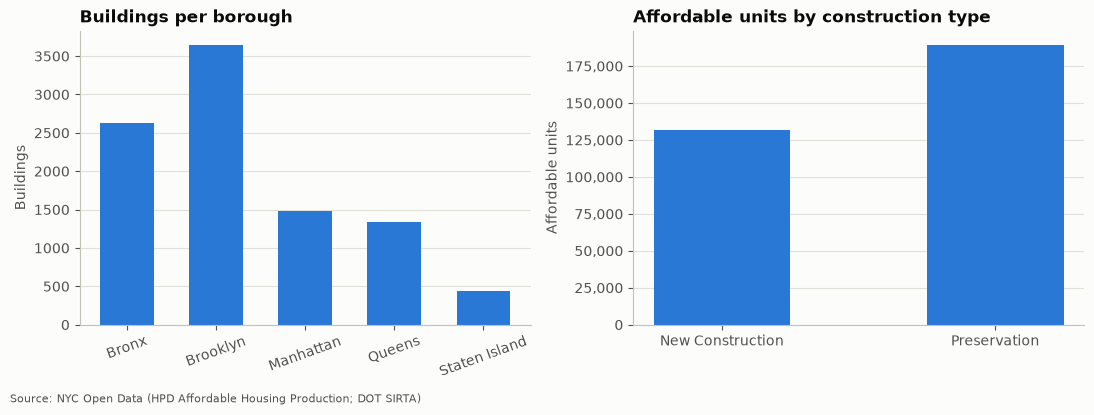

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
borough_counts = housing_raw["borough"].value_counts().reindex(BOROUGH_ORDER)
axes[0].bar(borough_counts.index, borough_counts.values, color=BLUE, width=0.6)
axes[0].tick_params(axis="x", rotation=20)
finish_chart(axes[0], "Buildings per borough", None, "Buildings", source=False)
type_units = housing_raw.groupby("reporting_construction_type")["all_counted_units"].sum()
axes[1].bar(type_units.index, type_units.values, color=BLUE, width=0.5)
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
finish_chart(axes[1], "Affordable units by construction type", None, "Affordable units")
plt.show()

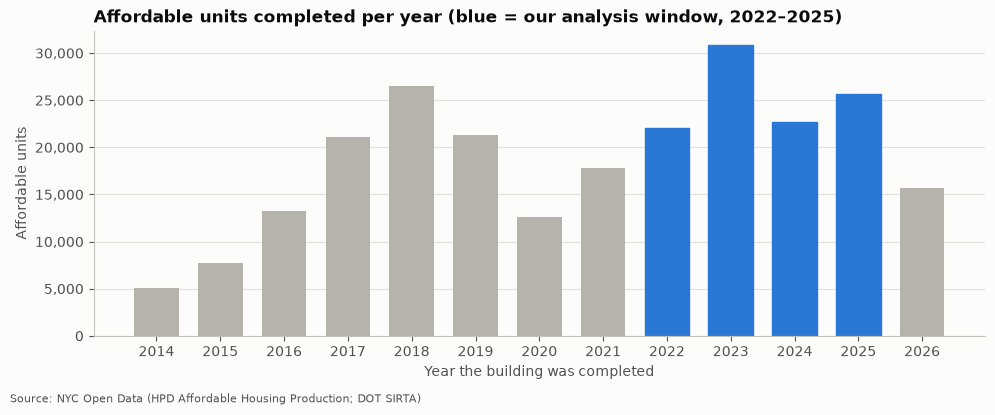

In [18]:
completion_year = pd.to_datetime(housing_raw["building_completion_date"]).dt.year
units_per_year = housing_raw.groupby(completion_year)["all_counted_units"].sum()
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(units_per_year.index.astype(int), units_per_year.values, color=GRAY, width=0.7)
for bar, year in zip(bars, units_per_year.index.astype(int)):
    if 2022 <= year <= 2025:
        bar.set_color(BLUE)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xticks(units_per_year.index.astype(int))
finish_chart(ax, "Affordable units completed per year (blue = our analysis window, 2022–2025)",
             "Year the building was completed", "Affordable units")
plt.show()

**What we see:** about 22,000–31,000 affordable units are completed every year from 2022 to 2025. 2026 is only partly recorded (the data ends mid-2026). 2020 dips, which matches COVID-19 construction stops.

### 3.9 Relationships between numeric columns (Lab 1: correlation heatmap)

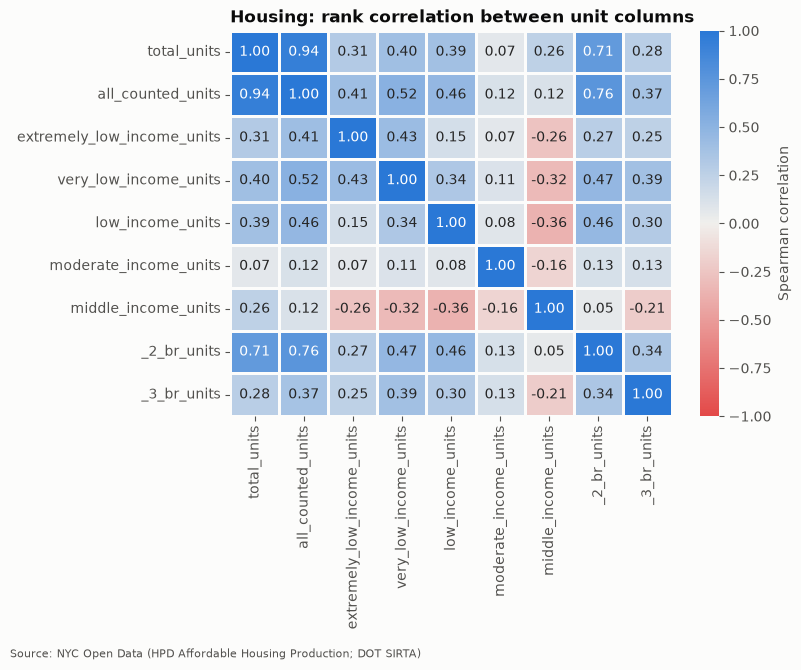

In [19]:
corr_columns = ["total_units", "all_counted_units", "extremely_low_income_units", "very_low_income_units",
                "low_income_units", "moderate_income_units", "middle_income_units", "_2_br_units", "_3_br_units"]
corr = housing_raw[corr_columns].fillna(0).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.blend_palette([RED, DIVERGING_MID, BLUE], as_cmap=True),
            vmin=-1, vmax=1, linewidths=1, linecolor=SURFACE, ax=ax, cbar_kws={"label": "Spearman correlation"})
ax.grid(False)
finish_chart(ax, "Housing: rank correlation between unit columns")
plt.show()

Blue means the two columns rise together, red means one rises when the other falls. Middle-income units are slightly negatively related to the low-income bands: buildings usually target either low-income or middle-income tenants, not both.

We use **Spearman** (rank) correlation instead of Pearson, because the unit counts are very skewed. Spearman only uses the order of the values, so a few huge buildings cannot dominate it.

### 3.10 Where are the buildings?

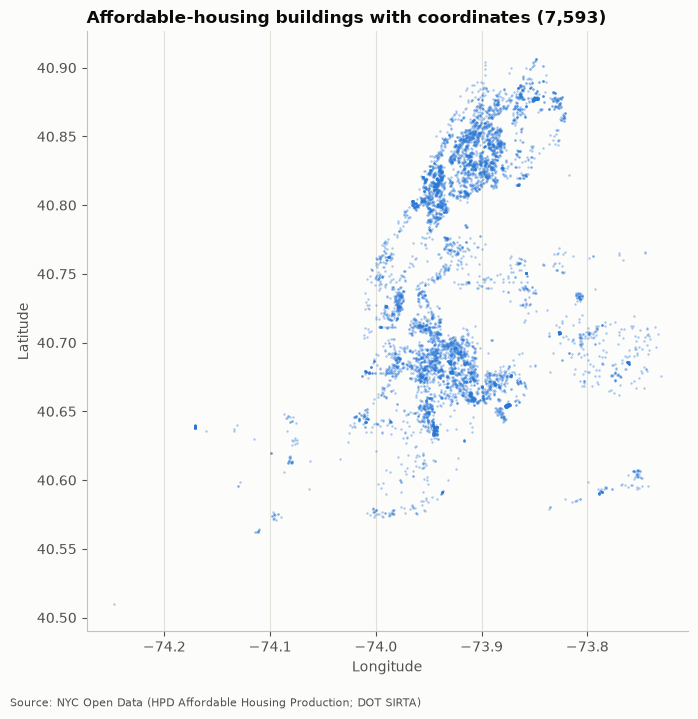

In [20]:
fig, ax = plt.subplots(figsize=(7, 7))
located = housing_raw.dropna(subset=["latitude", "longitude"])
ax.scatter(located["longitude"], located["latitude"], s=3, color=BLUE, alpha=0.4, linewidths=0)
ax.set_aspect(1.3)
ax.grid(axis="both")
finish_chart(ax, f"Affordable-housing buildings with coordinates ({len(located):,})", "Longitude", "Latitude")
plt.show()

### Insights from the housing EDA
1. **Units are very skewed.** We use medians, log scales and rank correlation.
2. **Three kinds of missing values need three different decisions:** empty unit cells mean 0 (proven in 3.6), empty locations are confidential homes, and empty completion dates mean "not finished yet".
3. **Hidden missing values exist:** "CONFIDENTIAL", "----", placeholder BINs, and Excel-corrupted house numbers.
4. **There are no true duplicates.** Repeated buildings are separate projects.
5. **The income-band columns break the tidy-data rule from Lecture 2** ("column headers are values, not variable names"). We reshape them into a long table in Section 5.

---
# 4. EDA: Serious crashes (SIRTA) dataset *(M3)*

### 4.1 Structure

In [21]:
print("Shape (rows, columns):", crashes_raw.shape)
crashes_raw.head(3).T

Shape (rows, columns): (12947, 23)


,0,1,2
open_data_crash_id,4492364.0,4491159.0,4491487.0
crash_date,2022-01-01T00:00:00.000,2022-01-01T00:00:00.000,2022-01-01T00:00:00.000
crash_time,01:28,04:33,05:55
crash_police_precinct,46.0,46.0,47.0
crash_borough,Bronx,Bronx,Bronx
total_non_severe_injuries,1.0,0.0,0.0
total_severe_injuries,1.0,1.0,1.0
total_fatalities,0.0,0.0,0.0
latitude,40.858707,NaN,40.87155
longitude,-73.9037,NaN,-73.86428


In [22]:
crashes_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12947 entries, 0 to 12946
Data columns (total 23 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   open_data_crash_id                      12503 non-null  float64
 1   crash_date                              12503 non-null  object 
 2   crash_time                              12503 non-null  object 
 3   crash_police_precinct                   12503 non-null  float64
 4   crash_borough                           12457 non-null  object 
 5   total_non_severe_injuries               12503 non-null  float64
 6   total_severe_injuries                   12503 non-null  float64
 7   total_fatalities                        12503 non-null  float64
 8   latitude                                10162 non-null  float64
 9   longitude                               10162 non-null  float64
 10  on_street                               10106 non-null  ob

**What we see:** 12,947 rows and 23 columns. As in the housing data, dates are text and ZIP codes are decimals. The police precinct is stored as a decimal (`46.0`).

**Data types (Lecture 2):** `crash_borough`, `zipcode`, `crash_police_precinct` and `on_street` are **nominal**. `crash_date` is **interval**. `total_severe_injuries`, `total_fatalities` and `total_non_severe_injuries` are **ratio** (counts).

### 4.2 Missing values

In [23]:
crash_missing = missing_value_table(crashes_raw)
crash_missing

,missing,percent
highway_reference_marker,11957,92.4
address,10564,81.6
bin,10337,79.8
bbl,10337,79.8
census_tract_2020_,9271,71.6
neighborhood_tabulation_area_nta_2020_,9271,71.6
council_district,9268,71.6
community_board,9268,71.6
zipcode,5465,42.2
cross_street,5318,41.1


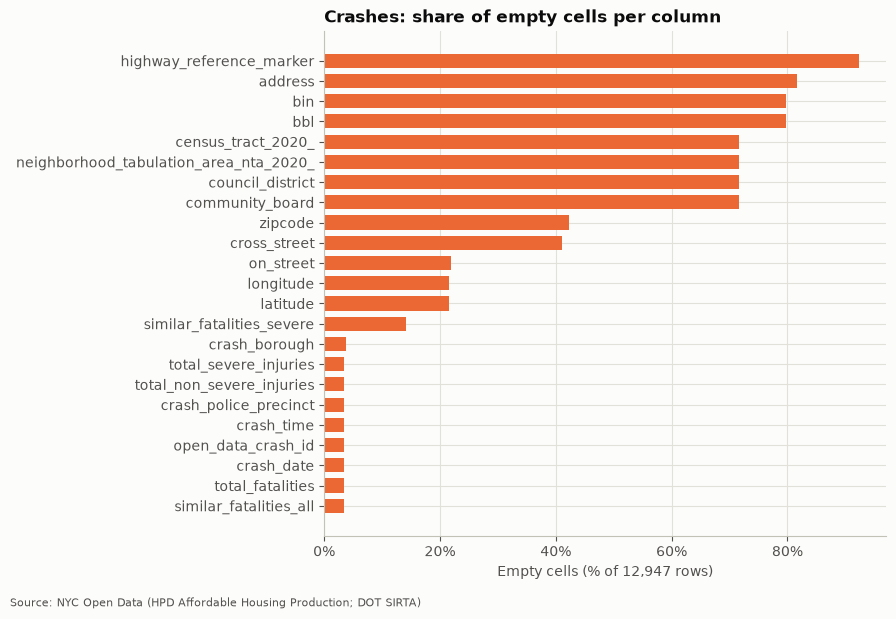

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(crash_missing.index, crash_missing["percent"], color=ORANGE, height=0.7)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="x", visible=True)
finish_chart(ax, "Crashes: share of empty cells per column", "Empty cells (% of 12,947 rows)")
plt.show()

**What we see:** exactly **444 rows** are missing the crash ID, date, time, precinct and injury counts together. That looks like a group of broken rows. We check them next.

### 4.3 Hidden problem 1: 444 broken records

In [25]:
broken_records = crashes_raw[crashes_raw["open_data_crash_id"].isna()]
print("Rows without a crash ID:", len(broken_records))
print("Fully empty rows found by isna().all():", crashes_raw.isna().all(axis=1).sum())
print("\nColumns that still have values in these rows:")
print(broken_records.notna().sum()[broken_records.notna().sum() > 0])

Rows without a crash ID: 444
Fully empty rows found by isna().all(): 0

Columns that still have values in these rows:
community_board                           444
council_district                          444
bin                                       433
bbl                                       433
census_tract_2020_                        444
neighborhood_tabulation_area_nta_2020_    444
dtype: int64


**What we see:** the standard check `isna().all()` finds **zero** empty rows, but the 444 rows still contain **no crash information at all**: no ID, date, time or injuries. Only location codes (community board, council district, census tract) are filled. These are probably location attributes that lost their crash during the agency's data processing. Without a date or an outcome they cannot be counted as crashes. We decide what to do in Section 6.

### 4.4 Hidden problem 2: placeholders in ZIP and time

In [26]:
crashes_valid = crashes_raw[crashes_raw["open_data_crash_id"].notna()]
print("ZIP code = 10000 (not a real NYC ZIP):", (crashes_valid["zipcode"] == 10000).sum())
print("\nMost common exact crash times:")
print(crashes_valid["crash_time"].value_counts().head(5))
print("\nTime written with one hour digit (e.g. '6:56'):", (crashes_valid["crash_time"].str.len() == 4).sum(),
      "| with two digits (e.g. '06:56'):", (crashes_valid["crash_time"].str.len() == 5).sum())

ZIP code = 10000 (not a real NYC ZIP): 37

Most common exact crash times:
crash_time
00:00    163
15:00     96
18:00     80
17:00     79
14:00     78
Name: count, dtype: int64

Time written with one hour digit (e.g. '6:56'): 656 | with two digits (e.g. '06:56'): 11847


**What we see:**
- **37 crashes have ZIP `10000`**, which is not a real NYC ZIP code (Manhattan starts at 10001). It is a placeholder.
- **Midnight is the most common time (163 + 41 = 204 crashes)**, twice as common as 15:00, the busiest real hour. Real traffic at midnight is much lighter, so "00:00" is very likely the **default value when the time is unknown**. This is the same kind of problem as the "?" in Lab 1.
- Times use two formats ("0:55" and "00:55"), which we standardize.

### 4.5 Duplicates

In [27]:
print("Fully duplicated rows (valid records):", crashes_valid.duplicated().sum())
duplicate_ids = crashes_valid[crashes_valid["open_data_crash_id"].duplicated(keep=False)]
duplicate_ids[["open_data_crash_id", "crash_date", "crash_time", "crash_borough", "on_street",
               "total_severe_injuries", "total_fatalities", "similar_fatalities_severe"]]

Fully duplicated rows (valid records): 0


,open_data_crash_id,crash_date,crash_time,crash_borough,on_street,total_severe_injuries,total_fatalities,similar_fatalities_severe
2157,4597666.0,2023-01-13T00:00:00.000,21:01,Bronx,WEST 170 STREET,1.0,0.0,1.0
10709,4597666.0,2026-01-13T00:00:00.000,21:01,Bronx,WEST 170 STREET,1.0,1.0,0.0


In [28]:
same_location = crashes_valid.duplicated(["latitude", "longitude"]) & crashes_valid["latitude"].notna()
print("Crashes that share exact coordinates with an earlier crash:", same_location.sum())

Crashes that share exact coordinates with an earlier crash: 1198


**What we see:**
- **One crash ID appears twice**, with the same time, street and precinct, but dates three years apart (13 Jan 2023 and 13 Jan 2026). An ID is supposed to be unique, so one of the two is a data-entry error.
- **3,538 crashes share coordinates with another crash.** These are **not duplicates**: they have different IDs and dates. Crashes are mapped to the nearest intersection, so dangerous intersections appear many times. This is exactly the "repeat location" pattern we study in RQ8.

### 4.6 Distributions of crash outcomes

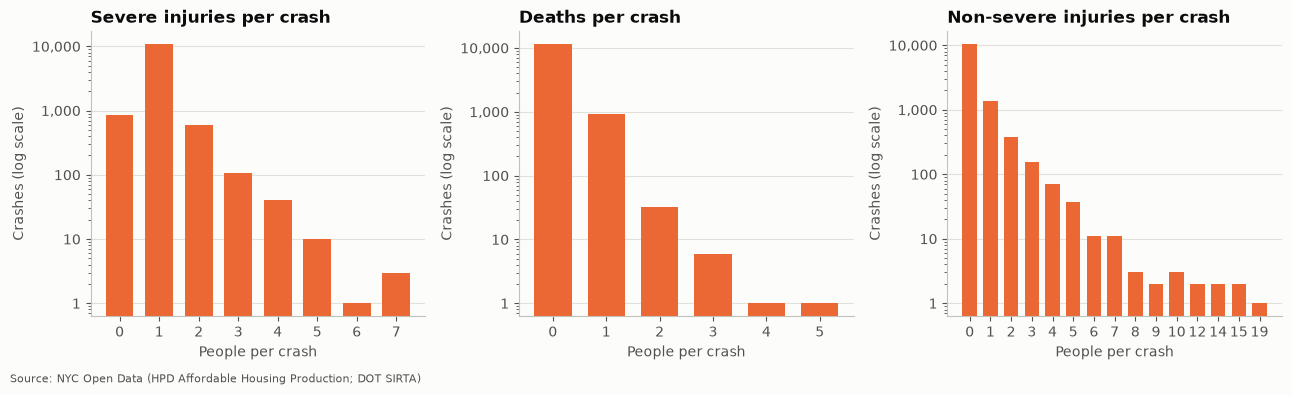

Severe injuries: Q1 = 1, Q3 = 1, so IQR = 0
Share of crashes with exactly 1 severe injury: 87%
Crashes with 0 severe injuries AND 0 deaths: 0


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, column, title in zip(axes, ["total_severe_injuries", "total_fatalities", "total_non_severe_injuries"],
                             ["Severe injuries per crash", "Deaths per crash", "Non-severe injuries per crash"]):
    counts = crashes_valid[column].value_counts().sort_index()
    ax.bar(counts.index.astype(int).astype(str), counts.values, color=ORANGE, width=0.7)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    finish_chart(ax, title, "People per crash", "Crashes (log scale)", source=(ax is axes[-1]))
plt.show()
q1, q3 = crashes_valid["total_severe_injuries"].quantile([0.25, 0.75])
print(f"Severe injuries: Q1 = {q1:.0f}, Q3 = {q3:.0f}, so IQR = {q3 - q1:.0f}")
print("Share of crashes with exactly 1 severe injury:",
      f"{(crashes_valid['total_severe_injuries'] == 1).mean():.0%}")
print("Crashes with 0 severe injuries AND 0 deaths:",
      ((crashes_valid["total_severe_injuries"] == 0) & (crashes_valid["total_fatalities"] == 0)).sum())

**What we see:**
- 87% of crashes have exactly one severe injury. Q1 = Q3 = 1, so **IQR = 0**. The IQR rule from Lab 2 would mark *every* crash with 0 or 2+ severe injuries as an outlier, which makes no sense. We need domain rules for this column (Section 6).
- **No crash has 0 severe injuries and 0 deaths.** This matches SIRTA's definition (every crash has a severe injury or a death), so the outcome columns are consistent.

### 4.7 Crashes over time and by borough

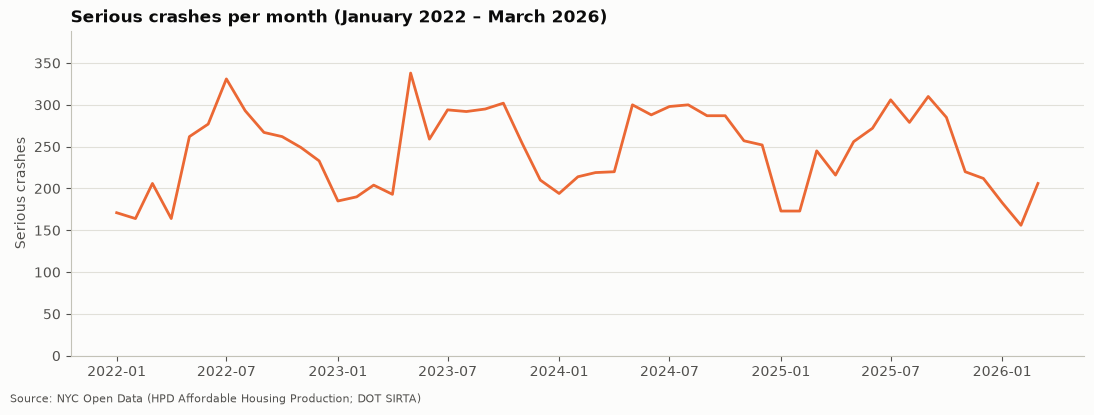

In [30]:
crash_month = pd.to_datetime(crashes_valid["crash_date"]).dt.to_period("M").dt.to_timestamp()
monthly = crash_month.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly.values, color=ORANGE, linewidth=2)
ax.set_ylim(0, monthly.max() * 1.15)
finish_chart(ax, "Serious crashes per month (January 2022 – March 2026)", None, "Serious crashes")
plt.show()

In [31]:
year_zip = crashes_valid.assign(year=pd.to_datetime(crashes_valid["crash_date"]).dt.year).groupby("year").agg(
    crashes=("open_data_crash_id", "size"),
    zip_reported=("zipcode", lambda z: z.notna().mean() * 100),
    coordinates=("latitude", lambda z: z.notna().mean() * 100),
).round(1)
year_zip

,crashes,zip_reported,coordinates
year,,,
2022,2879,16.3,89.0
2023,3016,68.1,81.5
2024,3116,70.0,66.2
2025,2947,80.3,88.1
2026,545,75.4,87.9


**What we see, and this is our most important EDA finding:**
- Serious crashes are fairly stable at about 230–290 per month, with summer peaks.
- **Only 16% of 2022 crashes have a ZIP code**, compared with 68–80% in later years. **If we dropped crashes without a ZIP, 2022 would look about 80% safer than it really was**, and every trend chart would show a fake rise in crashes. Dropping is therefore the wrong choice. Section 6 fills the ZIP from the coordinates instead.
- Coordinates are much more complete (66–89%), so they can be used to fill the ZIP.

**A second, hidden pattern: fatal crashes lose their exact location after 2022.**

In [32]:
location_by_severity = crashes_valid.assign(
    year=pd.to_datetime(crashes_valid["crash_date"]).dt.year,
    crash_type=np.where(crashes_valid["total_fatalities"] > 0, "fatal", "severe injury only"),
).groupby(["year", "crash_type"]).agg(
    crashes=("open_data_crash_id", "size"),
    coordinates=("latitude", lambda v: v.notna().mean() * 100),
    zip_reported=("zipcode", lambda v: v.notna().mean() * 100),
    street_name=("on_street", lambda v: v.notna().mean() * 100),
    precinct=("crash_police_precinct", lambda v: v.notna().mean() * 100),
).round(0)
location_by_severity

crashes  coordinates  zip_reported  street_name  precinct
year crash_type                                                                   
2022 fatal                   245         84.0          12.0         98.0     100.0
     severe injury only     2634         89.0          17.0         81.0     100.0
2023 fatal                   237          0.0          56.0         96.0     100.0
     severe injury only     2779         88.0          69.0         80.0     100.0
2024 fatal                   232          0.0          60.0         97.0     100.0
     severe injury only     2884         72.0          71.0         80.0     100.0
2025 fatal                   211          0.0          70.0         97.0     100.0
     severe injury only     2736         95.0          81.0         78.0     100.0
2026 fatal                    52          0.0          67.0         92.0     100.0
     severe injury only      493         97.0          76.0         77.0     100.0

**What we see:** from 2023 onward, **no fatal crash has coordinates (0%)**, while 84% of fatal crashes in 2022 and 72–95% of non-fatal crashes do. The precinct is always known, and the street name usually is. The agency seems to have stopped publishing the exact location of deadly crashes. This matters for us in two ways:
1. Fatal crashes after 2022 **cannot be placed on a map or measured by distance**. Our distance questions (RQ5, RQ6, RQ8, RQ9, RQ11) therefore describe mostly severe-injury crashes. We state this in each answer.
2. 30–44% of these fatal crashes also have no ZIP, and coordinates cannot fill it. If we ignored this, every death rate per ZIP would be too low. Section 6.9 fills these ZIPs from the **street name and precinct** instead.

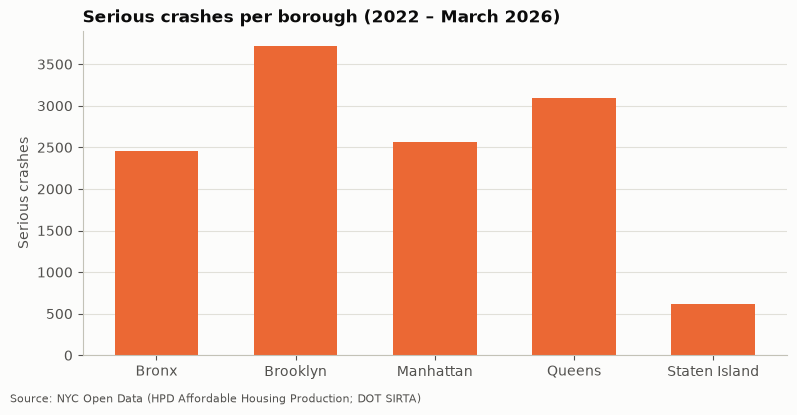

Crashes with no borough: 46 | their police precincts: {116.0: 46}


In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
borough_crashes = crashes_valid["crash_borough"].value_counts().reindex(BOROUGH_ORDER)
ax.bar(borough_crashes.index, borough_crashes.values, color=ORANGE, width=0.6)
finish_chart(ax, "Serious crashes per borough (2022 – March 2026)", None, "Serious crashes")
plt.show()
print("Crashes with no borough:", crashes_valid["crash_borough"].isna().sum(),
      "| their police precincts:", crashes_valid.loc[crashes_valid["crash_borough"].isna(),
                                                      "crash_police_precinct"].value_counts().to_dict())

**What we see:** Brooklyn has the most serious crashes. 46 crashes have no borough, and **all of them are in police precinct 116**, a new precinct in south-east Queens. No other crash in that precinct has a borough written, so the borough was probably never filled in for the new precinct. We fix this in Section 6.

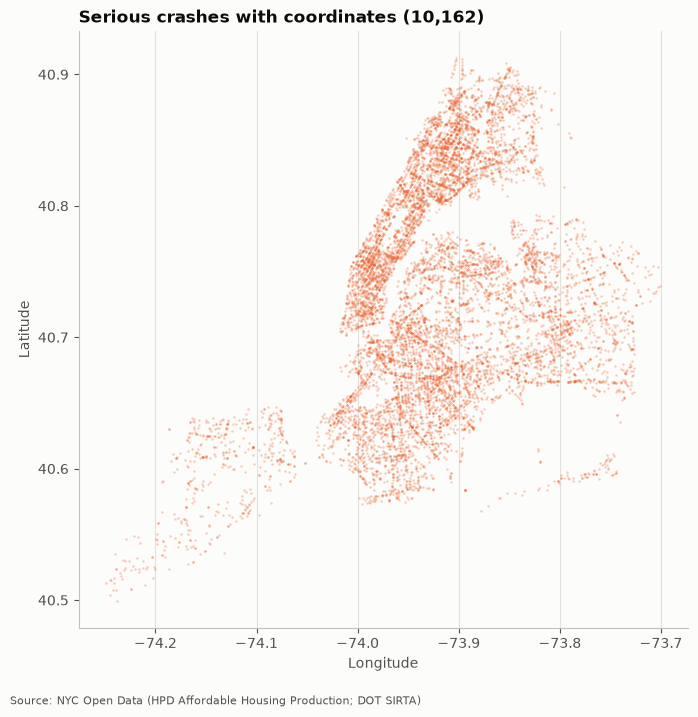

Latitude range: 40.499672 to 40.912468
Longitude range: -74.24857 to -73.7006


In [34]:
fig, ax = plt.subplots(figsize=(7, 7))
located_crashes = crashes_valid.dropna(subset=["latitude", "longitude"])
ax.scatter(located_crashes["longitude"], located_crashes["latitude"], s=3, color=ORANGE, alpha=0.35, linewidths=0)
ax.set_aspect(1.3)
ax.grid(axis="both")
finish_chart(ax, f"Serious crashes with coordinates ({len(located_crashes):,})", "Longitude", "Latitude")
plt.show()
print("Latitude range:", located_crashes["latitude"].min(), "to", located_crashes["latitude"].max())
print("Longitude range:", located_crashes["longitude"].min(), "to", located_crashes["longitude"].max())

All coordinates fall inside New York City (latitude 40.49–40.92, longitude −74.26 to −73.70), so there are **no impossible locations**. Highways show up clearly as lines of dots.

### 4.8 Street names

In [35]:
street_suffix = crashes_valid["on_street"].str.extract(r"\b(AVE|ST|BLVD|PKWY|EXPY|RD|PL)$")[0]
print("Street names ending in an abbreviation:", street_suffix.value_counts().to_dict())
print("Street names in lower or mixed case:",
      (crashes_valid["on_street"].dropna() != crashes_valid["on_street"].dropna().str.upper()).sum())
print("Addresses with repeated spaces:", crashes_valid["address"].dropna().str.contains("  ").sum())

Street names ending in an abbreviation: {'AVE': 1066, 'ST': 942, 'BLVD': 228, 'PKWY': 197, 'RD': 115, 'EXPY': 64, 'PL': 33}
Street names in lower or mixed case: 80
Addresses with repeated spaces: 2210


Street names mix full words and abbreviations ("3 AVENUE" and "3 AVE"), and there are case and spacing differences. The same street must have one spelling before we can count crashes per street.

### 4.9 Automated EDA (Lab 1 tools)

Lab 1 showed two automated EDA tools. We used **ydata-profiling** to create a full report for each raw dataset. The reports are saved in `reports/` (`housing_profile.html`, `crashes_profile.html`). They confirmed everything above: the skewed units, the empty unit columns, and the 444 rows with no crash ID.

The tools are slow and need extra installs, so they only run when the flag below is `True`.

In [36]:
RUN_AUTOMATED_PROFILING = False

if RUN_AUTOMATED_PROFILING:
    # !pip install ydata-profiling   (Colab: run this once)
    from ydata_profiling import ProfileReport
    os.makedirs("reports", exist_ok=True)
    ProfileReport(housing_raw, title="Affordable Housing - raw data", minimal=True).to_file("reports/housing_profile.html")
    ProfileReport(crashes_raw, title="SIRTA crashes - raw data", minimal=True).to_file("reports/crashes_profile.html")

### Insights from the crash EDA
1. **444 broken records** have no crash data, and `isna().all()` does not find them.
2. **Hidden missing values:** ZIP `10000` and midnight `00:00` as a default time.
3. **ZIP coverage depends on the year (16% in 2022 vs 80% in 2025).** Dropping rows without a ZIP would create a fake trend, so the ZIP must be imputed.
4. **Fatal crashes have no coordinates after 2022**, so distance-based results describe mostly severe-injury crashes, and fatal crashes need a second way to recover their ZIP.
5. **IQR fails on crash outcomes** (IQR = 0), so we use domain rules.
6. **One duplicated ID** with a three-year date difference. Repeated coordinates are dangerous intersections, not duplicates.
7. **46 crashes without a borough**, all in the new precinct 116 (Queens).

---
# 5. Pre-integration cleaning: housing *(M2)*

Every step below has the same structure:
**Problem** (what EDA showed) → **Decision** → **Why this choice, and why not the alternatives** → code → check.

We never change the raw table. Each step works on a copy, so `housing_raw` stays available for the before/after comparison in Section 7.

In [37]:
housing = housing_raw.copy()
cleaning_log_housing = []   # one line per step, shown as a summary table at the end


def log_step(log, step, rows_affected, decision):
    """Record one cleaning step so we can show a summary table later."""
    log.append({"step": step, "rows affected": int(rows_affected), "decision": decision})

### 5.1 Give columns clear names
**Problem:** some API names are unclear (`_1_br_units`, `all_counted_units`, `postcode`).
**Decision:** rename them so the code reads like plain English. Descriptive names are part of the clean-code grade.

In [38]:
housing = housing.rename(columns={
    "postcode": "zip_code",
    "reporting_construction_type": "construction_type",
    "extended_affordability_status": "extended_affordability_only",
    "all_counted_units": "affordable_units",
    "counted_rental_units": "rental_units",
    "counted_homeownership_units": "homeownership_units",
    "studio_units": "br0_units", "_1_br_units": "br1_units", "_2_br_units": "br2_units",
    "_3_br_units": "br3_units", "_4_br_units": "br4_units", "_5_br_units": "br5_units",
    "_6_br_units": "br6plus_units", "unknown_br_units": "br_unknown_units",
})
INCOME_BAND_COLUMNS = ["extremely_low_income_units", "very_low_income_units", "low_income_units",
                       "moderate_income_units", "middle_income_units", "other_income_units"]
BEDROOM_COLUMNS = ["br0_units", "br1_units", "br2_units", "br3_units", "br4_units", "br5_units",
                   "br6plus_units", "br_unknown_units"]
TENURE_COLUMNS = ["rental_units", "homeownership_units"]
UNIT_COLUMNS = INCOME_BAND_COLUMNS + BEDROOM_COLUMNS + TENURE_COLUMNS + ["affordable_units"]
log_step(cleaning_log_housing, "Rename columns", 0, "14 columns renamed to clear names")

### 5.2 Hidden missing values → real missing values (with a flag)
**Problem:** "CONFIDENTIAL", "----" and placeholder BINs (`3000000`) look like values, but they mean "unknown" (Section 3.5).
**Decision:**
1. First save the information in a new column `is_confidential`, so nothing is lost.
2. Then turn the placeholders into real missing values (`NaN`). This is the `na_values` idea from Lab 2: pandas only treats `NaN` as missing.

**Why:** if "----" stayed as text, `isna()` would report zero missing addresses, and any count of streets would include a fake street called "----".

In [39]:
housing["is_confidential"] = housing["project_name"].eq("CONFIDENTIAL")
housing.loc[housing["is_confidential"], "project_name"] = np.nan
for column in ["house_number", "street_name"]:
    housing[column] = housing[column].replace("----", np.nan)
placeholder_bin = housing["bin"].isin(PLACEHOLDER_BINS)
housing.loc[placeholder_bin, "bin"] = np.nan

log_step(cleaning_log_housing, "CONFIDENTIAL / ---- -> NaN + is_confidential flag",
         housing["is_confidential"].sum(), "kept rows; flag added; placeholders set to NaN")
log_step(cleaning_log_housing, "Placeholder BIN (x000000) -> NaN", placeholder_bin.sum(), "set to NaN")
print("Confidential buildings flagged:", housing["is_confidential"].sum())
print("Placeholder BINs removed:", placeholder_bin.sum())
print("Remaining '----' values:", (housing[["house_number", "street_name"]] == "----").sum().sum())

Confidential buildings flagged: 1949
Placeholder BINs removed: 482
Remaining '----' values: 0


### 5.3 Repair house numbers corrupted by Excel
**Problem:** 31 Queens house numbers were turned into dates ("10-44" became "Oct-44"; "20-10" became "20-Oct").
**Decision:** reverse Excel's change. A month name becomes its number again.
**Why:** the address is shown in the website's hover text, and "Oct-44 Jackson Ave" looks broken. Repairing is better than deleting, because the rest of the row is correct.

In [40]:
MONTH_NUMBER = {month: number for number, month in enumerate(MONTHS.split("|"), start=1)}


def repair_excel_date(house_number):
    """Undo Excel's date conversion of hyphenated Queens house numbers."""
    if not isinstance(house_number, str):
        return house_number
    month_first = re.match(rf"^({MONTHS})-(\d+)$", house_number)        # "Oct-44"  -> "10-44"
    if month_first:
        return f"{MONTH_NUMBER[month_first.group(1)]}-{month_first.group(2)}"
    day_first = re.match(rf"^(\d+)-({MONTHS})$", house_number)          # "20-Oct"  -> "20-10"
    if day_first:
        return f"{day_first.group(1)}-{MONTH_NUMBER[day_first.group(2)]:02d}"
    return house_number


corrupted = housing["house_number"].str.match(excel_date_pattern, na=False)
before_repair = housing.loc[corrupted, "house_number"].head(5).tolist()
housing["house_number"] = housing["house_number"].apply(repair_excel_date)
print("Before:", before_repair)
print("After: ", housing.loc[corrupted, "house_number"].head(5).tolist())
log_step(cleaning_log_housing, "Repair Excel-date house numbers", corrupted.sum(), "month name -> number")

Before: ['20-Oct', 'Feb-65', 'Oct-32', 'Apr-34', 'Apr-42']
After:  ['20-10', '2-65', '10-32', '4-34', '4-42']


### 5.4 Fix data types
**Problem:** dates are text, ZIP codes are decimals (`11432.0`), IDs are decimals.
**Decision:** dates → `datetime`. ZIP → 5-character text (`"11432"`), because a ZIP is a label (nominal), not a number to add. IDs and counts → whole numbers. We use pandas' `Int64` type, which allows missing values (normal `int` does not).
**Why it matters for integration:** if one dataset stores ZIP as `11432.0` and the other as `"11432"`, a join on ZIP finds **no matches**. This is a type mismatch, and we fix it before integrating.

In [41]:
def to_zip_text(zip_series):
    """11432.0 -> '11432'; missing stays missing."""
    return zip_series.astype("Int64").astype("string")


for column in ["project_start_date", "project_completion_date", "building_completion_date"]:
    housing[column] = pd.to_datetime(housing[column], errors="coerce")
housing["zip_code"] = to_zip_text(housing["zip_code"])
for column in ["building_id", "bin", "bbl", "council_district", "total_units"]:
    housing[column] = housing[column].astype("Int64")
print(housing[["project_start_date", "building_completion_date", "zip_code", "building_id", "total_units"]].dtypes)
log_step(cleaning_log_housing, "Fix data types", len(housing), "dates, ZIP as text, Int64 IDs")

project_start_date          datetime64[ns]
building_completion_date    datetime64[ns]
zip_code                    string[python]
building_id                          Int64
total_units                          Int64
dtype: object


### 5.5 Empty unit cells → 0
**Problem:** income-band, bedroom and tenure columns are up to 99% empty.
**Decision:** fill them with **0** (`fillna(0)`, Lab 2).
**Why:** Section 3.6 proved that after filling with 0, the parts add up **exactly** to the total in 100% of rows, and HPD never stores a 0. Empty therefore means "0 units".

**Alternatives we rejected:**
- *Mean or median imputation:* it would invent units that do not exist (for example 12 "middle income" units in a building that has none), and the parts would no longer add up to the total.
- *Dropping rows with empty cells:* almost every row has at least one empty band, so we would lose about 99% of the data (the Lab 2 lesson: `dropna()` is not a good option when there are many nulls).

In [42]:
empty_unit_cells = int(housing[UNIT_COLUMNS].isna().sum().sum())
empty_total = housing["affordable_units"].isna()
housing[UNIT_COLUMNS] = housing[UNIT_COLUMNS].fillna(0).astype("Int64")

band_sum_matches = (housing[INCOME_BAND_COLUMNS].sum(axis=1) == housing["affordable_units"]).mean()
print(f"Empty unit cells filled with 0: {empty_unit_cells:,}")
print(f"Rows where income bands add up to affordable_units after filling: {band_sum_matches:.1%}")
log_step(cleaning_log_housing, "Empty unit cells -> 0", empty_unit_cells, "fillna(0); proven by exact sums")
log_step(cleaning_log_housing, "Empty affordable_units -> 0", empty_total.sum(), "all bands are 0 too")

Empty unit cells filled with 0: 106,309
Rows where income bands add up to affordable_units after filling: 100.0%


### 5.6 Missing completion dates: keep them as missing
**Problem:** 1,666 buildings have no completion date.
**Decision:** keep `NaT` (missing date) and add `is_completed = False`.
**Why:** the date is missing because **the building is not finished yet**, not because it was lost. Any value we filled in would claim it is finished.
**Alternatives we rejected:**
- *Forward fill (`ffill`, Lab 2):* ffill only makes sense for ordered data such as a time series. Neighbouring rows here are unrelated projects, so ffill would copy another project's date.
- *Dropping the rows:* they are real buildings under construction. The website can still show them in "projects started".

In [43]:
housing["is_completed"] = housing["building_completion_date"].notna()
print("Buildings not yet completed:", (~housing["is_completed"]).sum())
log_step(cleaning_log_housing, "Missing completion date", (~housing["is_completed"]).sum(),
         "kept as NaT; is_completed flag")

Buildings not yet completed: 1666


### 5.7 Missing locations (confidential buildings): keep the rows
**Problem:** 1,958 buildings have no ZIP or coordinates (1,949 of them confidential).
**Decision:** keep the rows. Use them for **borough-level** results, and leave them out only of ZIP-level and distance analyses.
**Alternatives we rejected:**
- *Guessing the ZIP from the community board:* one community district contains several ZIP codes, so the guess would often be wrong, and HPD hid these addresses on purpose to protect privacy.
- *Dropping the rows:* we would lose 1,958 buildings from the borough totals.

### 5.8 Two sets of coordinates: keep one
**Problem:** the dataset has two coordinate pairs: `latitude/longitude` (estimated from the street address) and `latitude_internal/longitude_internal` (centre of the tax lot).

In [44]:
both_pairs = housing.dropna(subset=["latitude", "latitude_internal"])
pair_distance_m = np.hypot((both_pairs["latitude"] - both_pairs["latitude_internal"]) * 111_000,
                           (both_pairs["longitude"] - both_pairs["longitude_internal"]) * 84_000)
print(f"Median distance between the two coordinate pairs: {pair_distance_m.median():.0f} m")
print("Rows with only the street-address pair:", (housing["latitude"].notna() & housing["latitude_internal"].isna()).sum())
print("Rows with only the tax-lot pair:", (housing["latitude"].isna() & housing["latitude_internal"].notna()).sum())

Median distance between the two coordinate pairs: 31 m
Rows with only the street-address pair: 86
Rows with only the tax-lot pair: 0


**Decision:** keep `latitude/longitude` and drop the internal pair.
**Why:** the two points are only about 31 m apart (less than half a city block), so they carry the same information. The street-address pair is filled in 86 more rows. Keeping both would be **redundant**.

We also drop the 2010 census tract and 2010 neighbourhood codes. The crash data uses the **2020** versions of these codes, so they cannot be matched (for example `BK82` vs `BK0502`).

In [45]:
housing = housing.drop(columns=["latitude_internal", "longitude_internal", "census_tract",
                                "neighborhood_tabulation_area"])
log_step(cleaning_log_housing, "Drop redundant / incompatible columns", 0,
         "tax-lot coordinates, 2010 tract and NTA codes")

### 5.9 Consistency checks (multivariate outliers)
A **multivariate outlier** is a row whose values are each normal alone, but impossible **together** (Lab 2). We check four rules.

In [46]:
consistency_checks = pd.DataFrame({
    "rule": ["affordable units <= total units",
             "building completed on or after project start",
             "project completed on or after project start",
             "'extended affordability only' projects are preservation (data dictionary)",
             "coordinates inside New York City"],
    "rows breaking the rule": [
        int((housing["affordable_units"] > housing["total_units"]).sum()),
        int((housing["building_completion_date"] < housing["project_start_date"]).sum()),
        int((housing["project_completion_date"] < housing["project_start_date"]).sum()),
        int((housing["extended_affordability_only"].eq("Yes") & housing["construction_type"].eq("New Construction")).sum()),
        int((~housing["latitude"].between(40.47, 40.92) | ~housing["longitude"].between(-74.26, -73.69))
            [housing["latitude"].notna()].sum()),
    ],
})
consistency_checks

,rule,rows breaking the rule
0,affordable units <= total units,0
1,building completed on or after project start,20
2,project completed on or after project start,5
3,'extended affordability only' projects are pre...,2
4,coordinates inside New York City,0


**Decisions:**
- **20 buildings completed before the project "started".** This is **not an error**: HPD's data dictionary says the start date can be the date of the *notice to market* the affordable units, and that notice can come after construction. We keep the rows and flag them (`start_after_completion`). We never use these dates to compute a duration.
- **2 projects break the data-dictionary rule** (extended affordability, but labelled new construction). We cannot know which of the two fields is wrong, so we keep and flag them (`contradicts_dictionary`). Two rows out of 9,551 cannot change any result.
- All other rules pass.

In [47]:
housing["start_after_completion"] = housing["building_completion_date"] < housing["project_start_date"]
housing["contradicts_dictionary"] = (housing["extended_affordability_only"].eq("Yes")
                                     & housing["construction_type"].eq("New Construction"))
log_step(cleaning_log_housing, "Completion before start date", housing["start_after_completion"].sum(),
         "kept + flagged (start can be marketing date)")
log_step(cleaning_log_housing, "Contradicts data dictionary", housing["contradicts_dictionary"].sum(), "kept + flagged")

### 5.10 Outliers in building size: detect, explain, keep
**Method choice (Lab 2):** the Z-score method assumes a roughly normal distribution. Our unit counts are very skewed (skewness 3.7), so we use the **IQR method** for detection.

In [48]:
q1_units, q3_units = housing["affordable_units"].astype(float).quantile([0.25, 0.75])
iqr_units = q3_units - q1_units
upper_fence = q3_units + 1.5 * iqr_units
housing["is_large_building"] = housing["affordable_units"] > upper_fence
print(f"Q1 = {q1_units:.0f}, Q3 = {q3_units:.0f}, IQR = {iqr_units:.0f}, upper fence = Q3 + 1.5*IQR = {upper_fence:.0f} units")
print(f"Buildings above the fence: {housing['is_large_building'].sum():,} ({housing['is_large_building'].mean():.0%})")
housing.nlargest(5, "total_units")[["project_name", "borough", "total_units", "affordable_units"]]

Q1 = 2, Q3 = 30, IQR = 28, upper fence = Q3 + 1.5*IQR = 72 units
Buildings above the fence: 1,249 (13%)


,project_name,borough,total_units,affordable_units
1442,25 WATER STREET,Manhattan,1320,330
6902,605 WEST 42ND STREET PHASE II,Manhattan,1175,59
9157,605 WEST 42ND ST,Manhattan,1175,235
4533,5 POINTZ LIC,Queens,1122,337
3406,12 ROCKWELL PLACE,Brooklyn,1046,227


**Decision: keep every building and add an `is_large_building` flag.**
**Why:** the IQR rule flags 1,249 buildings (13%), and they are **real** large buildings, such as 25 Water Street (1,320 apartments, the conversion of a former office tower) and 5 Pointz in Long Island City. Lab 2 says an extreme point is not always an error ("true outlier observation"). Removing them would delete the most important housing projects in the city.
**How we handle the skew instead:** medians, log scales and rank (Spearman) correlation.
**Alternative rejected:** *capping* the values at the fence (winsorizing) would make the totals per ZIP wrong.

In [49]:
log_step(cleaning_log_housing, "Large buildings (IQR)", housing["is_large_building"].sum(),
         "real values: kept + flagged")

### 5.11 A shared community-district code
**Problem:** housing writes community boards as `"BK-05"`, and the crash data writes them as `305` (borough digit + district number). The same place has two spellings.
**Decision:** create `borough_code` and `community_district` in the crash-data format (`305`) for both datasets.

In [50]:
BOROUGH_CODE = {"Manhattan": 1, "Bronx": 2, "Brooklyn": 3, "Queens": 4, "Staten Island": 5}
housing["borough_code"] = housing["borough"].map(BOROUGH_CODE).astype("Int64")
housing["community_district"] = (housing["borough_code"] * 100
                                 + housing["community_board"].str[-2:].astype(int)).astype("Int64")
housing[["borough", "community_board", "community_district"]].drop_duplicates().head(4)

,borough,community_board,community_district
0,Queens,QN-08,408
1,Brooklyn,BK-01,301
2,Manhattan,MN-10,110
7,Bronx,BX-03,203


### 5.12 New columns for the analysis (feature engineering)
Like the `quote_length` column in Lab 1, we create columns that answer our questions directly:

| New column | Meaning |
|---|---|
| `completion_year` | year the building was completed (when residents can move in) |
| `deep_affordable_units` | extremely low + very low income units (households earning up to 50% of area median income) |
| `family_units` | apartments with 2 or more bedrooms |
| `family_share`, `deep_affordable_share` | the above as a share of the building's affordable units |
| `in_analysis_window` | completed in 2022–2025, the full years covered by both datasets |

In [51]:
housing["completion_year"] = housing["building_completion_date"].dt.year.astype("Int64")
housing["start_year"] = housing["project_start_date"].dt.year.astype("Int64")
housing["deep_affordable_units"] = housing["extremely_low_income_units"] + housing["very_low_income_units"]
housing["family_units"] = housing[["br2_units", "br3_units", "br4_units", "br5_units", "br6plus_units"]].sum(axis=1)
units_float = housing["affordable_units"].astype(float).replace(0, np.nan)          # avoid division by zero
housing["family_share"] = (housing["family_units"].astype(float) / units_float).round(3)
housing["deep_affordable_share"] = (housing["deep_affordable_units"].astype(float) / units_float).round(3)
housing["in_analysis_window"] = housing["completion_year"].between(2022, 2025).fillna(False).astype(bool)
print("Buildings completed in the 2022–2025 window:", housing["in_analysis_window"].sum())
print("Affordable units completed in the window:", f"{housing.loc[housing['in_analysis_window'], 'affordable_units'].sum():,}")

Buildings completed in the 2022–2025 window: 2957


Affordable units completed in the window: 101,249


### 5.13 Tidy data: income bands from wide to long (Lecture 2)
**Problem:** the six income-band columns break the tidy-data rule "column headers are values, not variable names". The band name ("very low income") is a **value** of a variable *income band*.
**Decision:** `melt` them into a long table with one row per building and income band. This makes "units by income band" a simple `groupby`, and the website uses it for its income-band filter.

In [52]:
INCOME_BAND_LABELS = {
    "extremely_low_income_units": "1. Extremely low (0–30% AMI)",
    "very_low_income_units": "2. Very low (31–50% AMI)",
    "low_income_units": "3. Low (51–80% AMI)",
    "moderate_income_units": "4. Moderate (81–120% AMI)",
    "middle_income_units": "5. Middle (121–165% AMI)",
    "other_income_units": "6. Other (superintendent units)",
}
housing_income_long = (
    housing.melt(id_vars=["project_id", "building_id", "borough", "zip_code", "completion_year", "in_analysis_window"],
                 value_vars=INCOME_BAND_COLUMNS, var_name="income_band", value_name="units")
    .assign(income_band=lambda d: d["income_band"].map(INCOME_BAND_LABELS))
    .query("units > 0")
    .reset_index(drop=True)
)
print("Long table:", housing_income_long.shape)
housing_income_long.head()

Long table: (16731, 8)


,project_id,building_id,borough,zip_code,completion_year,in_analysis_window,income_band,units
0,72436,1021347,Brooklyn,11211,<NA>,False,1. Extremely low (0–30% AMI),186
1,72449,21199,Manhattan,10030,<NA>,False,1. Extremely low (0–30% AMI),12
2,72449,28145,Manhattan,10030,<NA>,False,1. Extremely low (0–30% AMI),6
3,72449,40555,Manhattan,10030,<NA>,False,1. Extremely low (0–30% AMI),5
4,72449,40578,Manhattan,10030,<NA>,False,1. Extremely low (0–30% AMI),7


### Housing cleaning summary

In [53]:
pd.DataFrame(cleaning_log_housing)

,step,rows affected,decision
0,Rename columns,0,14 columns renamed to clear names
1,CONFIDENTIAL / ---- -> NaN + is_confidential flag,1949,kept rows; flag added; placeholders set to NaN
2,Placeholder BIN (x000000) -> NaN,482,set to NaN
3,Repair Excel-date house numbers,31,month name -> number
4,Fix data types,9551,"dates, ZIP as text, Int64 IDs"
5,Empty unit cells -> 0,106309,fillna(0); proven by exact sums
6,Empty affordable_units -> 0,29,all bands are 0 too
7,Missing completion date,1666,kept as NaT; is_completed flag
8,Drop redundant / incompatible columns,0,"tax-lot coordinates, 2010 tract and NTA codes"
9,Completion before start date,20,kept + flagged (start can be marketing date)


---
# 6. Pre-integration cleaning: crashes *(M3)*

In [54]:
crashes = crashes_raw.copy()
cleaning_log_crashes = []

crashes = crashes.rename(columns={
    "open_data_crash_id": "crash_id",
    "crash_borough": "borough",
    "crash_police_precinct": "precinct",
    "zipcode": "zip_code",
    "total_non_severe_injuries": "non_severe_injuries",
    "total_severe_injuries": "severe_injuries",
    "total_fatalities": "fatalities",
    "similar_fatalities_severe": "similar_severe_3y",
    "similar_fatalities_all": "similar_all_3y",
    "census_tract_2020_": "census_tract_2020",
    "neighborhood_tabulation_area_nta_2020_": "nta_2020",
})
log_step(cleaning_log_crashes, "Rename columns", 0, "11 columns renamed to clear names")

### 6.1 Remove the 444 broken records
**Problem:** 444 rows have no crash ID, date, time or injuries, only location codes (Section 4.3).
**Decision:** drop them. We detect them with the rule "no crash ID", because `isna().all()` misses them.
**Why:** a crash without a date or an outcome cannot be counted in any year, borough or severity group. There is nothing to impute from: no other column says when it happened or what happened. Lab 2's rule applies here: dropping is right when the row carries no usable information.

In [55]:
broken = crashes["crash_id"].isna()
crashes = crashes[~broken].copy()
print("Broken records removed:", broken.sum(), "| crashes left:", len(crashes))
log_step(cleaning_log_crashes, "Drop records with no crash data", broken.sum(), "dropped (nothing to impute)")

Broken records removed: 444 | crashes left: 12503


### 6.2 One crash ID used twice
**Problem:** crash `4597666` appears on 13 Jan 2023 **and** 13 Jan 2026, with the same time (21:01), street and precinct.
**Decision:** keep the **2023** record and drop the 2026 copy.
**Why:** a primary key must be unique, and everything except the year is identical, so this is one crash entered twice with a wrong year. We keep the earlier record because it is the original entry. The 2026 copy reports one death; it may be a later update, but we cannot verify that. Either choice changes 1 row out of 12,503 (0.008%).

In [56]:
duplicate_mask = crashes["crash_id"].duplicated(keep=False) & pd.to_datetime(crashes["crash_date"]).dt.year.eq(2026)
crashes = crashes[~duplicate_mask].copy()
print("Duplicate removed:", duplicate_mask.sum(), "| crash IDs now unique:", crashes["crash_id"].is_unique)
log_step(cleaning_log_crashes, "Duplicated crash ID", duplicate_mask.sum(), "kept original 2023 entry")

Duplicate removed: 1 | crash IDs now unique: True


### 6.3 Fix data types and standardize the time
**Decision:** dates → `datetime`; times → one format `HH:MM` ("6:56" → "06:56"); precinct, IDs and counts → whole numbers; ZIP → 5-character text (same format as housing).

In [57]:
crashes["crash_date"] = pd.to_datetime(crashes["crash_date"])
crashes["crash_time"] = pd.to_datetime(crashes["crash_time"], format="%H:%M").dt.strftime("%H:%M")
for column in ["crash_id", "precinct", "severe_injuries", "fatalities", "non_severe_injuries",
               "similar_severe_3y", "similar_all_3y", "community_board", "council_district", "bin", "bbl"]:
    crashes[column] = crashes[column].astype("Int64")
print("Time formats left:", crashes["crash_time"].str.len().value_counts().to_dict(), "(all 5 characters)")
log_step(cleaning_log_crashes, "Fix data types + time format", len(crashes), "HH:MM, Int64, datetime")

Time formats left: {5: 12502} (all 5 characters)


### 6.4 Placeholders: ZIP 10000 and the midnight default
**ZIP `10000`:** not a real ZIP code → set to missing. Section 6.7 fills it again from the coordinates.

**Midnight (`00:00`):** 204 crashes, twice the busiest real hour, so it is most likely the default for an unknown time.
**Decision:** keep these crashes (their date, place and injuries are real) but add a flag `time_unknown`. Only the time-of-day analysis (RQ5) leaves them out.
**Alternatives rejected:** *dropping* them would lose 204 real crashes from every other analysis. *Imputing a time* has no basis, because no other column tells us the hour.

In [58]:
fake_zip = crashes["zip_code"].eq(10000)
crashes.loc[fake_zip, "zip_code"] = np.nan
crashes["zip_code"] = to_zip_text(crashes["zip_code"])
crashes["time_unknown"] = crashes["crash_time"].eq("00:00")
print("ZIP 10000 set to missing:", fake_zip.sum(), "| midnight crashes flagged:", crashes["time_unknown"].sum())
log_step(cleaning_log_crashes, "ZIP 10000 -> NaN", fake_zip.sum(), "placeholder removed (refilled in 6.7)")
log_step(cleaning_log_crashes, "Time 00:00 -> time_unknown flag", crashes["time_unknown"].sum(),
         "kept; excluded only from hour analysis")

ZIP 10000 set to missing: 37 | midnight crashes flagged: 204


### 6.5 Missing borough: precinct 116 is in Queens
**Problem:** 46 crashes have no borough, and all are in police precinct 116.
**Decision:** fill in **Queens**, using two independent pieces of evidence:
1. NYPD numbers precincts by borough, and the 100s are Queens (precinct 116 opened recently in south-east Queens).
2. The coordinates of these crashes all lie in south-east Queens (checked below).

**Why not leave them missing:** the borough is a filter on our website. With an empty borough, these crashes would disappear from every borough view.

In [59]:
missing_borough = crashes["borough"].isna()
print("Precincts of crashes without a borough:", crashes.loc[missing_borough, "precinct"].value_counts().to_dict())
print(crashes.loc[missing_borough, ["latitude", "longitude"]].agg(["min", "max"]).round(3))
precinct_to_borough = crashes.dropna(subset=["borough"]).groupby("precinct")["borough"].agg(lambda b: b.mode()[0])
inconsistent = (crashes["precinct"].map(precinct_to_borough) != crashes["borough"]) & crashes["borough"].notna()
print("Crashes whose precinct and borough disagree:", int(inconsistent.sum()))
crashes.loc[missing_borough & crashes["precinct"].eq(116), "borough"] = "Queens"
log_step(cleaning_log_crashes, "Missing borough (precinct 116)", missing_borough.sum(), "filled with Queens")

Precincts of crashes without a borough: {np.int64(116): 46}
     latitude  longitude
min    40.636    -73.789
max    40.684    -73.728


Crashes whose precinct and borough disagree: 0


Latitude 40.64–40.68 and longitude −73.79 to −73.73 is exactly south-east Queens (Rosedale, Laurelton, Springfield Gardens). Every other crash's precinct agrees with its borough, so precinct is a reliable source.

### 6.6 Does the reported ZIP match the borough? (multivariate check)

In [60]:
zip_to_borough = housing.dropna(subset=["zip_code"]).groupby("zip_code")["borough"].agg(lambda b: b.mode()[0])
reported = crashes.dropna(subset=["zip_code"])
zip_borough = reported["zip_code"].map(zip_to_borough)
mismatch = reported[zip_borough.notna() & (zip_borough != reported["borough"])]
print("Crashes whose reported ZIP belongs to another borough:", len(mismatch))
mismatch[["crash_id", "zip_code", "borough", "on_street"]]

Crashes whose reported ZIP belongs to another borough: 4


,crash_id,zip_code,borough,on_street
2623,4606877,11237,Queens,IRVING AVENUE
3057,4590024,11385,Brooklyn,CYPRESS AVENUE
3660,4625492,11385,Brooklyn,SAINT NICHOLAS AVENUE
4082,4637665,11237,Queens,CYPRESS AVENUE


Only 4 mismatches, and all are ZIPs **11237** (Bushwick) and **11385** (Ridgewood). These two ZIP codes cross the Brooklyn–Queens border, so both boroughs are correct. **Decision:** keep them. This check also shows that the reported ZIPs are reliable.

### 6.7 Fill missing ZIP codes from the coordinates (Hot Deck imputation)
**Problem:** 42% of crashes have no ZIP, and the share depends on the year (84% missing in 2022, 20% in 2025). Dropping them would create the fake trend explained in Section 4.7.

**Decision: nearest-neighbour Hot Deck imputation.** Lab 2 names Hot Deck imputation: a missing value is copied from a similar *donor* row. For a crash without a ZIP but **with coordinates**, the most similar donor is the **nearest crash that has a known ZIP**, in the **same borough**.

**Alternatives we rejected:**
- *Mode (most common ZIP):* every missing crash in a borough would get the same ZIP. With about 40 ZIPs per borough, that is wrong almost every time.
- *Mean:* a ZIP is nominal, so the average of 10451 and 11201 means nothing.
- *Dropping:* creates the fake trend.

**Before using the method, we test it.** We hide the ZIP of 20% of the crashes whose ZIP we *do* know, predict it, and count how often we are right. We also try several numbers of neighbours *k*.

In [61]:
EARTH_RADIUS_M = 6_371_000


def to_radians(df):
    """Latitude/longitude in degrees -> radians, as the haversine distance needs."""
    return np.radians(df[["latitude", "longitude"]].to_numpy())


def zip_imputation_accuracy(donors, k, test_share=0.2, seed=42):
    """Hide the ZIP of test_share of donors, predict it from the k nearest crashes (same borough)."""
    rng = np.random.default_rng(seed)
    correct, tested = 0, 0
    for _, borough_rows in donors.groupby("borough"):
        order = rng.permutation(len(borough_rows))
        cut = int(len(borough_rows) * (1 - test_share))
        train, test = borough_rows.iloc[order[:cut]], borough_rows.iloc[order[cut:]]
        model = KNeighborsClassifier(n_neighbors=k, metric="haversine", algorithm="ball_tree", weights="distance")
        model.fit(to_radians(train), train["zip_code"])
        correct += (model.predict(to_radians(test)) == test["zip_code"].to_numpy()).sum()
        tested += len(test)
    return correct / tested


has_zip = crashes["zip_code"].notna()
has_coordinates = crashes["latitude"].notna()
zip_donors = crashes[has_zip & has_coordinates]
validation = pd.DataFrame({"k (neighbours)": [1, 3, 5, 9]})
validation["accuracy on hidden ZIPs"] = [zip_imputation_accuracy(zip_donors, k) for k in validation["k (neighbours)"]]
validation["accuracy on hidden ZIPs"] = validation["accuracy on hidden ZIPs"].map("{:.1%}".format)
validation

,k (neighbours),accuracy on hidden ZIPs
0,1,92.4%
1,3,92.0%
2,5,91.4%
3,9,91.9%


**Result:** with **k = 1** (copy the ZIP of the single nearest crash) the method finds the correct ZIP for about **92%** of the hidden crashes, slightly better than larger *k*. The remaining errors are mostly crashes on a ZIP border, where the neighbouring ZIP is still very close. We use k = 1. It is also the easiest version to explain: *"we copy the ZIP of the nearest crash."*

In [62]:
crashes["zip_source"] = np.where(has_zip, "reported", "missing")
needs_zip = ~has_zip & has_coordinates
for borough, donors_in_borough in zip_donors.groupby("borough"):
    targets = crashes[needs_zip & crashes["borough"].eq(borough)]
    if targets.empty:
        continue
    model = KNeighborsClassifier(n_neighbors=1, metric="haversine", algorithm="ball_tree")
    model.fit(to_radians(donors_in_borough), donors_in_borough["zip_code"])
    crashes.loc[targets.index, "zip_code"] = model.predict(to_radians(targets))
    crashes.loc[targets.index, "zip_source"] = "imputed (coordinates)"

crashes["year"] = crashes["crash_date"].dt.year
print("ZIP codes filled from coordinates:", needs_zip.sum(),
      "| still missing (no coordinates either):", (crashes["zip_source"] == "missing").sum())
pd.crosstab(crashes["year"], crashes["zip_source"], normalize="index").mul(100).round(1)

ZIP codes filled from coordinates: 3927 | still missing (no coordinates either): 1130


zip_source,imputed (coordinates),missing,reported
year,,,
2022,73.5,10.2,16.3
2023,21.7,10.2,68.0
2024,18.0,12.1,69.9
2025,16.4,4.3,79.3
2026,20.8,3.9,75.4


**After this first step, the ZIP is known for 88–96% of crashes in every year**, instead of 16–80%. The fake trend is gone. The column `zip_source` keeps the origin of every ZIP, so a reader can always tell real values from imputed ones.

1,130 crashes (9%) still have **neither a ZIP nor coordinates**, and 318 of them are **fatal** (Section 4.7). They get a second chance in Section 6.9, after the street names are cleaned.

In [63]:
log_step(cleaning_log_crashes, "Missing ZIP -> Hot Deck from coordinates", needs_zip.sum(),
         "copied from nearest crash in same borough (92% accurate in test)")

### 6.8 Standardize street names (the "match entire cell contents" lesson from Lab 3)
**Problem:** the same street is written in different ways ("3 AVE" / "3 AVENUE", "E 149 ST" / "EAST 149 STREET", lower and upper case).
**Decision:** upper case, single spaces, and abbreviations replaced **only as whole words**.

**Why whole words matter:** in Lab 3 we used *Match entire cell contents* when replacing "F" with "Female", because otherwise every "F" inside other words would change too. The same trap exists here:

In [64]:
print("Naive replace:    ", "3 AVENUE".replace("AVE", "AVENUE"), "  <- broken")
print("Whole-word regex: ", re.sub(r"\bAVE\b", "AVENUE", "3 AVENUE"), "  <- correct")

Naive replace:     3 AVENUENUE   <- broken
Whole-word regex:  3 AVENUE   <- correct


In [65]:
STREET_WORDS = [
    (r"^ST\b", "SAINT"),            # "ST NICHOLAS AVE" -> "SAINT NICHOLAS ..."  (ST at the start = Saint)
    (r"\bST$", "STREET"),           # "EAST 149 ST"     -> "... STREET"          (ST at the end = Street)
    (r"^E\b", "EAST"), (r"^W\b", "WEST"), (r"^N\b", "NORTH"), (r"^S\b", "SOUTH"),
    (r"\bAVE?\b", "AVENUE"), (r"\bBLVD\b", "BOULEVARD"), (r"\bPKWY\b", "PARKWAY"),
    (r"\bEXPY\b", "EXPRESSWAY"), (r"\bRD\b", "ROAD"), (r"\bPL\b", "PLACE"), (r"\bDR\b", "DRIVE"),
]


def standardize_street(name):
    """Upper case, single spaces, and whole-word abbreviation replacement."""
    if not isinstance(name, str):
        return name
    name = re.sub(r"\s+", " ", name.upper().strip())
    for pattern, full_word in STREET_WORDS:
        name = re.sub(pattern, full_word, name)
    return name


streets_before = crashes["on_street"].nunique()
for column in ["on_street", "cross_street", "address"]:
    crashes[column] = crashes[column].apply(standardize_street)
print(f"Different street names: {streets_before:,} before -> {crashes['on_street'].nunique():,} after")
log_step(cleaning_log_crashes, "Standardize street names", crashes["on_street"].notna().sum(),
         "upper case, whole-word abbreviations")

Different street names: 2,819 before -> 2,009 after


The number of different street names dropped from 2,819 to 2,009. About 800 "different" streets were the same street written in different ways, which would have split their crash counts.

### 6.9 Second Hot Deck step: ZIP from the street name and precinct
**Problem:** 1,130 crashes have no ZIP and no coordinates, and 318 of them are fatal. Fatal crashes after 2022 never have coordinates (Section 4.7), so leaving these ZIPs empty would remove about a third of all deaths from every ZIP-level result, and every death rate per ZIP would be too low.

**Decision:** a second Hot Deck step with a different donor rule. Every crash has a **police precinct**, and most have a **street name**. A donor is a crash with a known ZIP on the **same street, in the same precinct** (and at the same cross street when we know it). We copy the most common ZIP among those donors.

We test it the same way as before: hide 20% of the **reported** ZIPs and predict them.

In [66]:
def street_lookup_tables(donors):
    """Most common ZIP per (precinct, street, cross street) and per (precinct, street)."""
    by_crossing = (donors.dropna(subset=["cross_street"])
                   .groupby(["precinct", "on_street", "cross_street"])["zip_code"].agg(lambda z: z.mode()[0]))
    by_street = donors.groupby(["precinct", "on_street"])["zip_code"].agg(lambda z: z.mode()[0])
    return by_crossing, by_street


def predict_zip_from_street(rows, by_crossing, by_street):
    """Use the exact crossing when possible, otherwise the street inside the precinct."""
    crossing_keys = pd.MultiIndex.from_frame(rows[["precinct", "on_street", "cross_street"]])
    street_keys = pd.MultiIndex.from_frame(rows[["precinct", "on_street"]])
    from_crossing = pd.Series(by_crossing.reindex(crossing_keys).to_numpy(), index=rows.index)
    from_street = pd.Series(by_street.reindex(street_keys).to_numpy(), index=rows.index)
    return from_crossing.fillna(from_street)


street_donors = crashes[crashes["zip_code"].notna() & crashes["on_street"].notna()]
reported_donors = street_donors[street_donors["zip_source"] == "reported"]
test_rows = reported_donors.sample(frac=0.2, random_state=42)
train_rows = street_donors.drop(test_rows.index)
predicted = predict_zip_from_street(test_rows, *street_lookup_tables(train_rows))
found = predicted.notna()
print(f"Test: a donor was found for {found.mean():.0%} of hidden ZIPs; "
      f"the copied ZIP was correct for {(predicted[found] == test_rows.loc[found, 'zip_code']).mean():.0%} of them")

Test: a donor was found for 81% of hidden ZIPs; the copied ZIP was correct for 73% of them


In [67]:
still_missing = crashes["zip_code"].isna() & crashes["on_street"].notna()
street_prediction = predict_zip_from_street(crashes[still_missing], *street_lookup_tables(street_donors)).dropna()
crashes.loc[street_prediction.index, "zip_code"] = street_prediction
crashes.loc[street_prediction.index, "zip_source"] = "imputed (street)"
print("ZIP codes filled from street + precinct:", len(street_prediction),
      "| of them fatal:", int(crashes.loc[street_prediction.index, "fatalities"].gt(0).sum()),
      "| still missing:", (crashes["zip_source"] == "missing").sum())

crashes["is_fatal_crash"] = crashes["fatalities"] > 0
zip_known = (crashes.assign(zip_known=crashes["zip_code"].notna())
             .pivot_table(index="year", columns="is_fatal_crash", values="zip_known", aggfunc="mean")
             .mul(100).round(1).rename(columns={False: "severe-injury crashes: ZIP known (%)",
                                                True: "fatal crashes: ZIP known (%)"}))
crashes = crashes.drop(columns="is_fatal_crash")
zip_known

ZIP codes filled from street + precinct: 741 | of them fatal: 256 | still missing: 389


is_fatal_crash,severe-injury crashes: ZIP known (%),fatal crashes: ZIP known (%)
year,,
2022,95.7,95.9
2023,96.8,92.4
2024,97.2,93.5
2025,98.4,92.4
2026,99.2,94.1


**Result:** a donor is found for 81% of hidden ZIPs, and the copied ZIP is right **73%** of the time. Errors usually land in the neighbouring ZIP on the same street. This is less accurate than the coordinate method (92%), so:
- We use it **only** for crashes that have no coordinates, as a second step.
- It gets its own label, `zip_source = "imputed (street)"`, so any analysis can leave these ZIPs out.
- In RQ10, the question about deaths, we show the result **with and without** street-imputed ZIPs.

**Why accept 73% accuracy:** the alternative is not "no error", it is a **systematic** error. Without this step, a third of the fatal crashes from 2023–2025 would be missing from every ZIP. With it, more than 92% of fatal crashes have a ZIP in every year. A 73%-accurate guess along the same street is a smaller and more honest error than silently dropping a third of the deaths. RQ10 shows how much this matters: without this step, the death rate in ZIPs without new housing looks almost half as high as it really is.

In [68]:
log_step(cleaning_log_crashes, "Missing ZIP (no coordinates) -> Hot Deck from street + precinct",
         len(street_prediction), "copied from crashes on the same street in the same precinct (73% accurate)")

### 6.10 Crash outcomes: domain rules instead of IQR
**Problem:** IQR = 0 for severe injuries (Section 4.6), so the IQR rule from Lab 2 would mark every crash with 0 or 2+ severe injuries as an outlier.
**Decision:** use rules that come from what the data **means**:

In [69]:
outcome_rules = pd.DataFrame({
    "rule": ["no negative counts",
             "every crash has a severe injury or a death (SIRTA definition)",
             "crashes with 5+ people seriously hurt (checked by hand, real multi-victim crashes)"],
    "rows": [int((crashes[["severe_injuries", "fatalities", "non_severe_injuries"]] < 0).any(axis=1).sum()),
             int(((crashes["severe_injuries"] + crashes["fatalities"]) == 0).sum()),
             int(((crashes["severe_injuries"] + crashes["fatalities"]) >= 5).sum())],
})
outcome_rules

,rule,rows
0,no negative counts,0
1,every crash has a severe injury or a death (SI...,0
2,crashes with 5+ people seriously hurt (checked...,16


No row breaks the first two rules. The 16 crashes with 5 or more people seriously hurt are rare but **real** (for example a vehicle hitting a crowd or a bus crash). **Decision:** keep them all.

### 6.11 "Similar crashes in the last 3 years": unknown is not zero
**Problem:** `similar_severe_3y` (how many similar serious crashes happened at the same place in the 3 previous years) is missing for 1,393 crashes.
**Decision:** keep it **missing**. RQ8 uses only crashes where the value is known.
**Why not `fillna(0)`:** 0 is a real answer ("no similar crash here before"). Filling unknown values with 0 would claim 1,393 locations had no earlier crashes, and RQ8 would underestimate repeat-danger locations.

### 6.12 New columns for the analysis

In [70]:
crashes["month"] = crashes["crash_date"].dt.to_period("M").dt.to_timestamp()
crashes["weekday"] = crashes["crash_date"].dt.day_name()
crashes["hour"] = crashes["crash_time"].str[:2].astype(int)
crashes["people_seriously_hurt"] = crashes["severe_injuries"] + crashes["fatalities"]
crashes["is_fatal"] = crashes["fatalities"] > 0
crashes["on_highway"] = crashes["highway_reference_marker"].notna()      # DOT gives highway crashes a reference marker
crashes["at_repeat_location"] = (crashes["similar_severe_3y"] > 0).astype("boolean")  # stays <NA> when unknown
crashes["in_analysis_window"] = crashes["year"].between(2022, 2025)        # 2026 is only January–March
crashes["community_district"] = crashes["community_board"]
print("Crashes in the 2022–2025 window:", crashes["in_analysis_window"].sum())
print("Fatal crashes:", crashes["is_fatal"].sum(), "| on highways:", crashes["on_highway"].sum())

Crashes in the 2022–2025 window: 11958
Fatal crashes: 976 | on highways: 990


### 6.13 Drop columns we do not need
**Decision:** drop `bin`, `bbl`, `census_tract_2020`, `nta_2020` and `council_district`.
**Why:** they are 72–80% empty, and the 2020 census and neighbourhood codes cannot be matched with the 2010 codes in the housing data. After imputation, ZIP is known for 97% of crashes, so ZIP is the better shared geography. We keep `community_district` (74% empty) only for reference.

In [71]:
crashes = crashes.drop(columns=["bin", "bbl", "census_tract_2020", "nta_2020", "council_district", "community_board"])
log_step(cleaning_log_crashes, "Drop mostly-empty / incompatible columns", 0,
         "5 columns dropped; community board kept as community_district")
pd.DataFrame(cleaning_log_crashes)

,step,rows affected,decision
0,Rename columns,0,11 columns renamed to clear names
1,Drop records with no crash data,444,dropped (nothing to impute)
2,Duplicated crash ID,1,kept original 2023 entry
3,Fix data types + time format,12502,"HH:MM, Int64, datetime"
4,ZIP 10000 -> NaN,37,placeholder removed (refilled in 6.7)
5,Time 00:00 -> time_unknown flag,204,kept; excluded only from hour analysis
6,Missing borough (precinct 116),46,filled with Queens
7,Missing ZIP -> Hot Deck from coordinates,3927,copied from nearest crash in same borough (92%...
8,Standardize street names,10105,"upper case, whole-word abbreviations"
9,Missing ZIP (no coordinates) -> Hot Deck from ...,741,copied from crashes on the same street in the ...


---
# 7. Checking that the cleaning worked *(M6)*

The project asks for **charts that prove the cleaning worked**. We show three before/after comparisons and then run automatic checks.

### 7.1 Missing values before and after

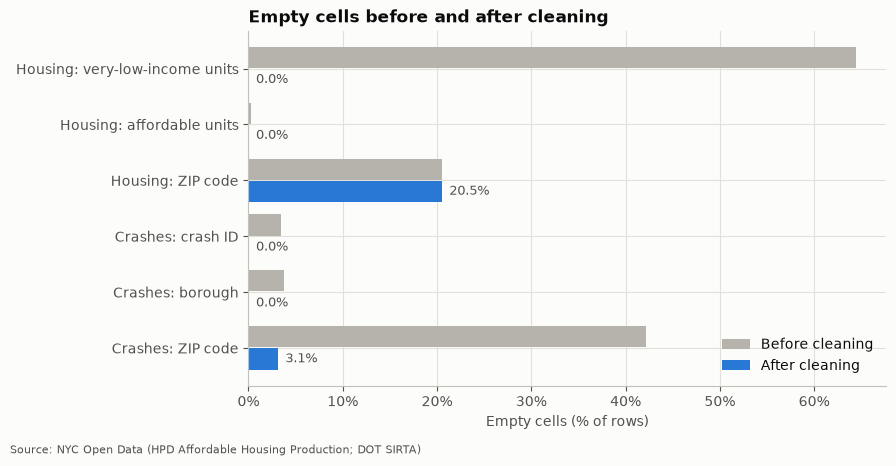

In [72]:
def missing_share(df, columns):
    return df[columns].isna().mean().mul(100)


housing_check = pd.DataFrame({
    "before": missing_share(housing_raw.rename(columns={"postcode": "zip_code", "all_counted_units": "affordable_units",
                                                        "very_low_income_units": "very_low_income_units"}),
                            ["very_low_income_units", "affordable_units", "zip_code"]),
    "after": missing_share(housing, ["very_low_income_units", "affordable_units", "zip_code"]),
}).rename(index={"very_low_income_units": "Housing: very-low-income units", "affordable_units": "Housing: affordable units",
                 "zip_code": "Housing: ZIP code"})
crash_check = pd.DataFrame({
    "before": missing_share(crashes_raw.rename(columns={"crash_borough": "borough", "zipcode": "zip_code",
                                                        "open_data_crash_id": "crash_id"}),
                            ["crash_id", "borough", "zip_code"]),
    "after": missing_share(crashes, ["crash_id", "borough", "zip_code"]),
}).rename(index={"crash_id": "Crashes: crash ID", "borough": "Crashes: borough", "zip_code": "Crashes: ZIP code"})
missing_before_after = pd.concat([housing_check, crash_check])

fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(missing_before_after))
ax.barh(positions - 0.2, missing_before_after["before"], height=0.38, color=GRAY, label="Before cleaning")
ax.barh(positions + 0.2, missing_before_after["after"], height=0.38, color=BLUE, label="After cleaning")
for y, value in zip(positions, missing_before_after["after"]):
    ax.text(value + 0.8, y + 0.2, f"{value:.1f}%", va="center", fontsize=9, color=INK_SOFT)
ax.set_yticks(positions, missing_before_after.index)
ax.invert_yaxis()
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(loc="lower right")
finish_chart(ax, "Empty cells before and after cleaning", "Empty cells (% of rows)")
plt.show()

**Reading the chart:** the very-low-income column goes from 64% empty to 0% (empty meant zero). Crash IDs and boroughs are now complete. Crash ZIPs drop from 42% to 3% empty. Housing ZIPs stay about 20% empty **on purpose**: they are the confidential homes, which we keep for borough-level results.

### 7.2 The key check: ZIP coverage per year

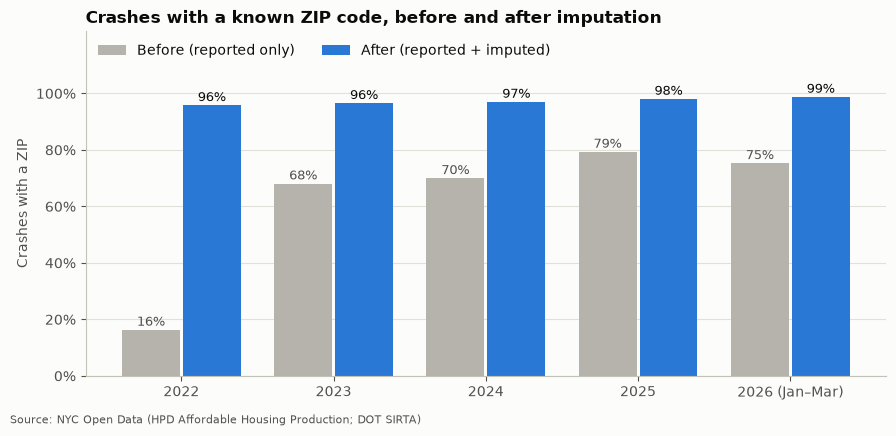

In [73]:
coverage_before = crashes_raw.assign(year=pd.to_datetime(crashes_raw["crash_date"]).dt.year).dropna(subset=["year"])
coverage_before = coverage_before.groupby("year")["zipcode"].apply(lambda z: (z.notna() & (z != 10000)).mean() * 100)
coverage_after = crashes.groupby("year")["zip_code"].apply(lambda z: z.notna().mean() * 100)
years = coverage_after.index.astype(int)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(years))
ax.bar(x - 0.2, coverage_before.reindex(coverage_after.index).values, width=0.38, color=GRAY, label="Before (reported only)")
ax.bar(x + 0.2, coverage_after.values, width=0.38, color=BLUE, label="After (reported + imputed)")
for xi, value in zip(x, coverage_before.reindex(coverage_after.index).values):
    ax.text(xi - 0.2, value + 1.5, f"{value:.0f}%", ha="center", fontsize=9, color=INK_SOFT)
for xi, value in zip(x, coverage_after.values):
    ax.text(xi + 0.2, value + 1.5, f"{value:.0f}%", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, [f"{y}" + (" (Jan–Mar)" if y == 2026 else "") for y in years])
ax.set_ylim(0, 122)
ax.set_yticks(range(0, 101, 20))
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(loc="upper left", ncol=2)
finish_chart(ax, "Crashes with a known ZIP code, before and after imputation", None, "Crashes with a ZIP")
plt.show()

**Reading the chart:** before cleaning, 2022 had a ZIP for only 16% of crashes, so a ZIP-level count would show 2022 as far safer than later years. After the two imputation steps every year is above 95%, so **years can now be compared fairly**.

### 7.3 The cleaning did not distort the data

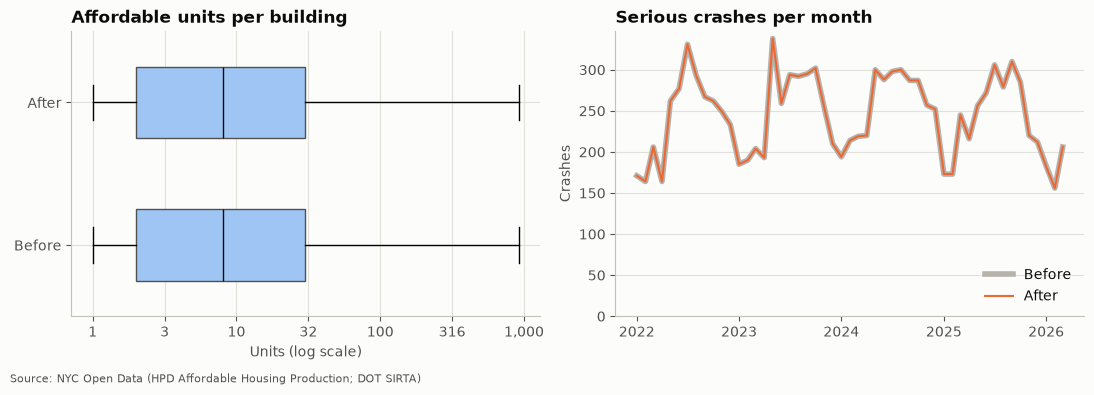

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
before_units = housing_raw["all_counted_units"].dropna()
after_units = housing["affordable_units"].astype(float)
axes[0].boxplot([np.log10(before_units), np.log10(after_units.replace(0, np.nan).dropna())], orientation="horizontal",
                tick_labels=["Before", "After"], widths=0.5, patch_artist=True,
                boxprops=dict(facecolor=BLUE_RAMP[1], edgecolor=INK_SOFT), medianprops=dict(color=INK))
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{10 ** v:,.0f}"))
axes[0].grid(axis="x", visible=True)
finish_chart(axes[0], "Affordable units per building", "Units (log scale)", source=False)
monthly_before = pd.to_datetime(crashes_raw["crash_date"]).dt.to_period("M").value_counts().sort_index()
monthly_after = crashes["crash_date"].dt.to_period("M").value_counts().sort_index()
axes[1].plot(monthly_before.index.to_timestamp(), monthly_before.values, color=GRAY, linewidth=4, label="Before")
axes[1].plot(monthly_after.index.to_timestamp(), monthly_after.values, color=ORANGE, linewidth=1.5, label="After")
axes[1].set_ylim(0, None)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].legend(loc="lower right")
finish_chart(axes[1], "Serious crashes per month", None, "Crashes")
plt.show()

Both lines overlap almost exactly: the cleaning removed only broken records and one duplicate, and **did not change** the shape of the data. Building sizes are identical before and after (zeros were only filled into the *part* columns, not the totals).

### 7.4 Automatic checks
These `assert` statements stop the notebook with an error if any cleaning rule is broken. They protect us when the data is downloaded again in the future.

In [75]:
assert crashes["crash_id"].is_unique, "duplicate crash IDs"
assert crashes["borough"].notna().all(), "crash without borough"
assert not crashes["zip_code"].eq("10000").any(), "placeholder ZIP left"
assert (crashes["crash_time"].str.len() == 5).all(), "time not in HH:MM"
assert not (housing[["house_number", "street_name"]] == "----").any().any(), "'----' left"
assert (housing[INCOME_BAND_COLUMNS].sum(axis=1) == housing["affordable_units"]).all(), "income bands do not add up"
assert housing["zip_code"].dropna().str.fullmatch(r"\d{5}").all(), "ZIP not 5 digits"
assert crashes["zip_code"].dropna().str.fullmatch(r"\d{5}").all(), "ZIP not 5 digits"
print("All cleaning checks passed.")
print(f"Housing: {len(housing_raw):,} -> {len(housing):,} rows | Crashes: {len(crashes_raw):,} -> {len(crashes):,} rows")

All cleaning checks passed.
Housing: 9,551 -> 9,551 rows | Crashes: 12,947 -> 12,502 rows


### 7.5 Automated before/after report (Lab 1: Sweetviz `compare`)
In Lab 1, Sweetviz compared a train and a test set. We use the same function to compare the crash data **before and after cleaning**. The report is saved as `reports/crashes_before_after.html`. Like the profiling reports, it only runs when the flag is `True`.

In [76]:
RUN_SWEETVIZ_COMPARE = False

if RUN_SWEETVIZ_COMPARE:
    # !pip install sweetviz   (Colab: run this once)
    import sweetviz as sv
    shared_columns = ["borough", "severe_injuries", "fatalities", "non_severe_injuries", "zip_code", "latitude"]
    before = crashes_raw.rename(columns={"crash_borough": "borough", "total_severe_injuries": "severe_injuries",
                                         "total_fatalities": "fatalities", "total_non_severe_injuries": "non_severe_injuries",
                                         "zipcode": "zip_code"})[shared_columns]
    after = crashes[shared_columns].astype({"zip_code": "float", "severe_injuries": "float", "fatalities": "float",
                                           "non_severe_injuries": "float"})
    sv.compare([before.astype({"zip_code": "float"}), "Before cleaning"], [after, "After cleaning"]).show_html(
        "reports/crashes_before_after.html", open_browser=False)

---
# 8. Integration *(M1)*

### 8.1 Why we do not join the raw rows
The two tables have **no shared ID**: a building and a crash are different things. A join on a shared column such as ZIP code would pair **every building with every crash** in the same ZIP. The project description warns against exactly this ("don't join rows just because a column matches"). Here is how big that wrong join would be:

In [77]:
buildings_per_zip = housing["zip_code"].value_counts()
crashes_per_zip = crashes["zip_code"].value_counts()
naive_join_rows = int((buildings_per_zip * crashes_per_zip).dropna().sum())
print(f"Buildings: {len(housing):,} | Crashes: {len(crashes):,}")
print(f"A raw row-by-row join on ZIP would create {naive_join_rows:,} rows.")
print("Each crash would be counted once for every building in its ZIP, so all totals would be wrong.")

Buildings: 9,551 | Crashes: 12,502
A raw row-by-row join on ZIP would create 745,752 rows.
Each crash would be counted once for every building in its ZIP, so all totals would be wrong.


More than **700,000** meaningless rows from 9,551 buildings and 12,502 crashes. Each crash would be repeated once for every building in its ZIP, so any sum of crashes would be multiplied many times. The correct method is to **aggregate both datasets to the same level first, then join** (Lab 4's *Merge Queries* on common columns, after aggregation).

### 8.2 Choosing the level (granularity)

| Possible level | In housing? | In crashes? | Verdict |
|---|---|---|---|
| Borough × year | 100% | 100% | Too coarse for analysis (only 5 places), but used for the website's borough views |
| Community district | 100% | 26% | Rejected: 74% of crashes have no community district |
| Census tract / neighbourhood (NTA) | 2010 codes | 2020 codes | Rejected: the code versions do not match |
| **ZIP code × year** | 80% (all non-confidential) | 97% after imputation | **Chosen (Level A)** |
| **Exact coordinates** | 80% | 81% | **Chosen (Level B)** for distance questions |

**Why ZIP × year fits our questions:**
- Our questions ask whether *areas* that receive new affordable homes are *areas* with dangerous streets. A ZIP code (about 200 in NYC) is small enough to show differences inside a borough and large enough to hold enough crashes for stable counts (see the median per ZIP in Section 9.4).
- **Year** fits both datasets: housing is counted by completion year, the year residents move in, and crashes by crash year.
- **Time window: 2022–2025**, the full years covered by both datasets. 2026 is left out of yearly comparisons because the crash data stops in March 2026.

**Why we also need coordinates (Level B):** a ZIP code is about 4 km² on average. "In the same ZIP" can still mean 2 km away. For questions about the streets *right next to* new homes, we measure real distances.

### 8.3 Level A: aggregate both datasets to ZIP × year

In [78]:
WINDOW_YEARS = [2022, 2023, 2024, 2025]

housing_window = housing[housing["in_analysis_window"]]
housing_zip_year = (
    housing_window.dropna(subset=["zip_code"])
    .groupby(["zip_code", "completion_year"])
    .agg(buildings_completed=("building_id", "size"),
         affordable_units=("affordable_units", "sum"),
         deep_affordable_units=("deep_affordable_units", "sum"),
         family_units=("family_units", "sum"),
         new_construction_units=("affordable_units",
                                 lambda u: u[housing_window.loc[u.index, "construction_type"].eq("New Construction")].sum()),
         borough=("borough", lambda b: b.mode()[0]))
    .reset_index()
    .rename(columns={"completion_year": "year"})
)

crashes_window = crashes[crashes["in_analysis_window"]]
crash_zip_year = (
    crashes_window.dropna(subset=["zip_code"])
    .groupby(["zip_code", "year"])
    .agg(serious_crashes=("crash_id", "size"),
         fatal_crashes=("is_fatal", "sum"),
         deaths=("fatalities", "sum"),
         severe_injuries=("severe_injuries", "sum"),
         highway_crashes=("on_highway", "sum"),
         borough=("borough", lambda b: b.mode()[0]))
    .reset_index()
)
print("Housing ZIP-year rows:", len(housing_zip_year), "| key types:", housing_zip_year[["zip_code", "year"]].dtypes.to_dict())
print("Crash ZIP-year rows:  ", len(crash_zip_year), "| key types:", crash_zip_year[["zip_code", "year"]].dtypes.to_dict())

Housing ZIP-year rows: 391 | key types: {'zip_code': string[python], 'year': Int64Dtype()}
Crash ZIP-year rows:   705 | key types: {'zip_code': string[python], 'year': dtype('int32')}


Before merging we check the **types of the join keys**. ZIP is already text in both tables (fixed in Sections 5.4 and 6.3). The **year** is `Int64` in housing (it came from a date column that has missing values) and `int32` in crashes. We convert both to the same type so the merge cannot fail silently. This is one of the type mismatches handled in Section 9.

In [79]:
housing_zip_year["year"] = housing_zip_year["year"].astype(int)
crash_zip_year["year"] = crash_zip_year["year"].astype(int)

zip_year_merged = housing_zip_year.merge(
    crash_zip_year, on=["zip_code", "year"], how="outer",
    suffixes=("_housing", "_crashes"), indicator=True, validate="one_to_one",
)
zip_year_merged["_merge"].value_counts()

_merge
both          390
right_only    315
left_only       1
Name: count, dtype: int64

We use an **outer** join so that no ZIP-year is lost:
- **both**: the ZIP had new affordable buildings *and* serious crashes that year.
- **right_only**: serious crashes but no new affordable building that year. These are very common and important: they are the "no new housing" comparison group.
- **left_only**: new buildings but no serious crash that year (rare).

`validate="one_to_one"` makes pandas check that each (ZIP, year) appears only once on each side, which proves the aggregation worked.

### 8.4 Level B: distances between buildings and crashes
For each crash we find the distance to the nearest affordable building completed in 2022–2025. For each building we count the serious crashes within a radius.

**Method:** a `BallTree` with the **haversine** distance (distance on the Earth's surface), the same structure we used for the ZIP imputation.

**Choosing the radius:** we tested several radii (below). At 500 m, 67% of all crashes in the city count as "near new housing", so "near" no longer separates anything. **250 m** (about 2–3 city blocks, a 3-minute walk) splits the crashes into two comparable groups (42% near, 58% elsewhere) and still describes "the streets around your home". Section 10 repeats the key results at 150 m and 500 m to show that the conclusions do not depend on this choice.

In [80]:
NEAR_RADIUS_M = 250

new_buildings = (housing_window.dropna(subset=["latitude", "longitude"])
                 .sort_values("building_completion_date")
                 .drop_duplicates("building_id", keep="last")          # 1 building completed twice in the window
                 .reset_index(drop=True))
located_crashes = crashes_window.dropna(subset=["latitude", "longitude"]).reset_index(drop=True)

building_tree = BallTree(to_radians(new_buildings), metric="haversine")
crash_tree = BallTree(to_radians(located_crashes), metric="haversine")

distance_rad, nearest_index = building_tree.query(to_radians(located_crashes), k=1)
located_crashes["distance_to_new_housing_m"] = (distance_rad[:, 0] * EARTH_RADIUS_M).round(0)
located_crashes["near_new_housing"] = located_crashes["distance_to_new_housing_m"] <= NEAR_RADIUS_M

radius_test = pd.DataFrame({"radius (m)": [100, 150, 200, 250, 300, 500]})
radius_test["share of crashes 'near'"] = [
    f"{(located_crashes['distance_to_new_housing_m'] <= r).mean():.0%}" for r in radius_test["radius (m)"]]
print(f"New affordable buildings with coordinates: {len(new_buildings):,}")
print(f"Serious crashes with coordinates (2022–2025): {len(located_crashes):,}")
radius_test

New affordable buildings with coordinates: 2,240
Serious crashes with coordinates (2022–2025): 9,683


,radius (m),share of crashes 'near'
0,100,14%
1,150,25%
2,200,34%
3,250,42%
4,300,49%
5,500,67%


In [81]:
new_buildings["crashes_within_250m"] = crash_tree.query_radius(
    to_radians(new_buildings), r=NEAR_RADIUS_M / EARTH_RADIUS_M, count_only=True)
print("Serious crashes within 250 m of a new building (2022–2025):")
new_buildings["crashes_within_250m"].describe().round(1)

Serious crashes within 250 m of a new building (2022–2025):


count    2240.0
mean        5.7
std         3.9
min         0.0
25%         3.0
50%         5.0
75%         8.0
max        25.0
Name: crashes_within_250m, dtype: float64

### 8.5 Level C: borough × year (for the website)
Every crash has a borough, and every building (including the confidential ones) has a borough, so this level uses **100%** of both datasets.

In [82]:
borough_year = (
    housing_window.groupby(["borough", "completion_year"])
    .agg(affordable_units=("affordable_units", "sum"), buildings_completed=("building_id", "size"))
    .reset_index().rename(columns={"completion_year": "year"})
    .astype({"year": int})
    .merge(crashes_window.groupby(["borough", "year"])
           .agg(serious_crashes=("crash_id", "size"), deaths=("fatalities", "sum")).reset_index(),
           on=["borough", "year"], how="outer", validate="one_to_one")
)
borough_year

,borough,year,affordable_units,buildings_completed,serious_crashes,deaths
0,Bronx,2022,12006,183,600,55
1,Bronx,2023,17422,280,600,46
2,Bronx,2024,9373,237,622,52
3,Bronx,2025,7043,261,543,33
4,Brooklyn,2022,3469,278,885,76
5,Brooklyn,2023,7046,312,874,66
6,Brooklyn,2024,4979,225,919,65
7,Brooklyn,2025,6023,241,879,76
8,Manhattan,2022,2696,60,570,40
9,Manhattan,2023,3702,72,653,39


---
# 9. Post-integration cleaning *(M1)*
The join itself creates new problems, which the project description asks us to fix: **nulls created by the join, redundant columns, and type mismatches**.

### 9.1 Nulls created by the join
**Problem:** in an outer join, a ZIP-year with crashes but no new building gets `NaN` in every housing column (and the other way round).

In [83]:
count_columns_housing = ["buildings_completed", "affordable_units", "deep_affordable_units", "family_units",
                         "new_construction_units"]
count_columns_crashes = ["serious_crashes", "fatal_crashes", "deaths", "severe_injuries", "highway_crashes"]
print("Missing values created by the join:")
zip_year_merged[count_columns_housing + count_columns_crashes].isna().sum()

Missing values created by the join:


buildings_completed       315
affordable_units          315
deep_affordable_units     315
family_units              315
new_construction_units    315
serious_crashes             1
fatal_crashes               1
deaths                      1
severe_injuries             1
highway_crashes             1
dtype: int64

**Decision:** fill these with **0**.
**Why:** here `NaN` does not mean "unknown". It means **"no record"**: no building was completed, or no serious crash was recorded, in that ZIP that year. For a count, no record means zero. (This is different from the crash ZIP problem in Section 6.7, where the crash existed but its ZIP was unknown.)

**A second, hidden gap:** a ZIP-year with *no building and no crash* does not appear at all. If ZIP 10280 had crashes in 2023 only, the table has no rows for its other years, and an average over years would use 1 year instead of 4. **Decision:** build the **complete grid** (every ZIP × every year) and fill the empty combinations with 0 too.

In [84]:
all_zips = sorted(set(zip_year_merged["zip_code"]))
complete_grid = pd.MultiIndex.from_product([all_zips, WINDOW_YEARS], names=["zip_code", "year"]).to_frame(index=False)
zip_year = complete_grid.merge(zip_year_merged, on=["zip_code", "year"], how="left")
print(f"Rows before completing the grid: {len(zip_year_merged)} | after: {len(zip_year)} "
      f"({len(all_zips)} ZIPs x {len(WINDOW_YEARS)} years)")
zip_year[count_columns_housing + count_columns_crashes] = zip_year[count_columns_housing + count_columns_crashes].fillna(0)

Rows before completing the grid: 706 | after: 740 (185 ZIPs x 4 years)


### 9.2 Redundant and conflicting columns
**Problem:** both tables had a `borough` column, so after the join there are two (`borough_housing`, `borough_crashes`), and many rows have only one of them. There is also the helper column `_merge`.
**Decision:** keep **one** borough per ZIP, the borough where most of the ZIP's buildings and crashes are, and turn `_merge` into two readable flags before dropping it.

In [85]:
borough_votes = pd.concat([
    housing.dropna(subset=["zip_code"])[["zip_code", "borough"]],
    crashes.dropna(subset=["zip_code"])[["zip_code", "borough"]],
])
zip_borough = borough_votes.groupby("zip_code")["borough"].agg(lambda b: b.mode()[0])
conflicts = zip_year.dropna(subset=["borough_housing", "borough_crashes"])
conflicts = conflicts[conflicts["borough_housing"] != conflicts["borough_crashes"]]
print("ZIP-years where the two borough columns disagree:", len(conflicts),
      "| ZIPs:", sorted(conflicts["zip_code"].unique()))

zip_year["borough"] = zip_year["zip_code"].map(zip_borough)
zip_year["had_new_housing"] = zip_year["affordable_units"] > 0
zip_year["had_serious_crash"] = zip_year["serious_crashes"] > 0
zip_year = zip_year.drop(columns=["borough_housing", "borough_crashes", "_merge"])
print("Columns now:", list(zip_year.columns))

ZIP-years where the two borough columns disagree: 0 | ZIPs: []
Columns now: ['zip_code', 'year', 'buildings_completed', 'affordable_units', 'deep_affordable_units', 'family_units', 'new_construction_units', 'serious_crashes', 'fatal_crashes', 'deaths', 'severe_injuries', 'highway_crashes', 'borough', 'had_new_housing', 'had_serious_crash']


Because both sides were aggregated with the most common borough per ZIP, the two columns never disagree. They are still **redundant** (the same information twice) and **half empty** (each one only exists for its own side of the join), so one clean `borough` column replaces them. Border ZIPs such as 11385 get one consistent borough everywhere.

### 9.3 Type mismatches after the join
We met three type mismatches during integration:
1. **ZIP code:** decimal (`11432.0`) in both raw files. Fixed before the join (Sections 5.4 and 6.3), otherwise no ZIP would match.
2. **Year:** `Int64` in housing and `int32` in crashes. Fixed just before the merge (Section 8.3).
3. **Counts after the join:** columns that contained missing values use pandas' special nullable type `Int64`, with a special `<NA>` value, while other counts are normal integers. Plotting and NumPy functions do not always accept `<NA>`, so mixing the two types causes errors later (for example on the website).

**Decision for 3:** after filling the nulls, convert every count to the standard integer type `int64`.

In [86]:
print("Before:", zip_year[["affordable_units", "serious_crashes", "deaths"]].dtypes.to_dict())
zip_year[count_columns_housing + count_columns_crashes] = zip_year[count_columns_housing + count_columns_crashes].astype(int)
print("After: ", zip_year[["affordable_units", "serious_crashes", "deaths"]].dtypes.to_dict())

Before: {'affordable_units': Int64Dtype(), 'serious_crashes': Int64Dtype(), 'deaths': Int64Dtype()}
After:  {'affordable_units': dtype('int64'), 'serious_crashes': dtype('int64'), 'deaths': dtype('int64')}


### 9.4 One summary row per ZIP, plus a map position
For most research questions we need the **4-year total per ZIP**. We also add:
- `affordable_units_since_2014`: all affordable units completed in the ZIP since 2014 (the total *stock* of new affordable housing, not only 2022–2025).
- A **map position** for each ZIP: the average coordinates of all buildings and crashes in that ZIP. This gives a good centre point without any extra map dataset.
- `community_district`: the most common community district of the ZIP's buildings, to name the area (for example "BX 05").

In [87]:
zip_summary = zip_year.groupby(["zip_code", "borough"], as_index=False)[count_columns_housing + count_columns_crashes].sum()
stock = housing[housing["completion_year"].between(2014, 2025)].groupby("zip_code")["affordable_units"].sum()
zip_summary["affordable_units_since_2014"] = zip_summary["zip_code"].map(stock).fillna(0).astype(int)

zip_points = pd.concat([housing[["zip_code", "latitude", "longitude"]],
                        crashes[["zip_code", "latitude", "longitude"]]]).dropna()
zip_summary = zip_summary.merge(zip_points.groupby("zip_code")[["latitude", "longitude"]].mean().round(5),
                                on="zip_code", how="left")
zip_cd = housing.dropna(subset=["zip_code"]).groupby("zip_code")["community_board"].agg(lambda c: c.mode()[0])
zip_summary["community_district"] = zip_summary["zip_code"].map(zip_cd).str.replace("-", " ")

zip_summary["deaths_per_100_crashes"] = (100 * zip_summary["deaths"] / zip_summary["serious_crashes"].replace(0, np.nan)).round(1)
zip_summary["highway_share"] = (zip_summary["highway_crashes"] / zip_summary["serious_crashes"].replace(0, np.nan)).round(3)
print("ZIPs:", len(zip_summary), "| with new affordable units 2022–2025:", (zip_summary["affordable_units"] > 0).sum())
print("Median serious crashes per ZIP (2022–2025):", int(zip_summary["serious_crashes"].median()))
zip_summary.sort_values("affordable_units", ascending=False).head()

ZIPs: 185 | with new affordable units 2022–2025: 133
Median serious crashes per ZIP (2022–2025): 58


,zip_code,borough,buildings_completed,affordable_units,deep_affordable_units,family_units,new_construction_units,serious_crashes,fatal_crashes,deaths,severe_injuries,highway_crashes,affordable_units_since_2014,latitude,longitude,community_district,deaths_per_100_crashes,highway_share
85,10475,Bronx,80,15507,11413,9964,0,56,5,5,65,13,15531,40.87428,-73.82729,BX 10,8.9,0.232
181,11691,Queens,20,3888,1458,1707,2629,54,6,6,58,0,5397,40.60027,-73.75907,QN 14,11.1,0.000
61,10451,Bronx,32,3865,1055,1772,1882,107,7,7,105,5,6631,40.82089,-73.92318,BX 01,6.5,0.047
62,10452,Bronx,55,3561,1881,1315,1857,140,13,13,140,27,6572,40.83912,-73.92174,BX 04,9.3,0.193
101,11208,Brooklyn,31,2929,1519,1352,2007,118,4,5,127,0,3368,40.67447,-73.87370,BK 05,4.2,0.000


### 9.5 Final checks on the integrated tables
The most important check is **conservation**: the integrated table must contain exactly the same number of crashes and units as the cleaned datasets. Nothing may be lost or counted twice by the join.

In [88]:
assert not zip_year.duplicated(["zip_code", "year"]).any(), "duplicate ZIP-year"
assert zip_year[count_columns_housing + count_columns_crashes].notna().all().all(), "nulls left after the join"
assert zip_year["borough"].notna().all(), "ZIP without borough"
assert zip_year["serious_crashes"].sum() == crashes_window["zip_code"].notna().sum(), "crashes lost or duplicated"
assert zip_year["affordable_units"].sum() == housing_window.dropna(subset=["zip_code"])["affordable_units"].sum(), "units lost"
assert borough_year["serious_crashes"].sum() == len(crashes_window), "borough table lost crashes"
print("Integration checks passed:")
print(f"  ZIP x year table: {len(zip_year)} rows, {zip_year['serious_crashes'].sum():,} crashes, "
      f"{zip_year['affordable_units'].sum():,} affordable units")
print(f"  Crashes without a ZIP (kept only in borough results): {crashes_window['zip_code'].isna().sum():,}")
print(f"  Confidential units without a ZIP (kept only in borough results): "
      f"{housing_window[housing_window['zip_code'].isna()]['affordable_units'].sum():,}")

Integration checks passed:
  ZIP x year table: 740 rows, 11,576 crashes, 100,057 affordable units
  Crashes without a ZIP (kept only in borough results): 382
  Confidential units without a ZIP (kept only in borough results): 1,192


---
# 10. Research questions

Each team member asks **two** questions, and each question has **one chart** that answers it.

| # | Owner | Question | Chart | Level |
|---|---|---|---|---|
| RQ1 | M1 | Do ZIP codes that gained more affordable units also record more serious crashes? | Scatter | A: ZIP |
| RQ2 | M1 | In each borough, did serious crashes rise or fall alongside housing completions from 2022 to 2025? | Line (small multiples) | C: borough × year |
| RQ3 | M2 | Are new-construction buildings in more dangerous ZIPs than preservation buildings? | Box plot | A: ZIP |
| RQ4 | M2 | Do the lowest-income tenants live in more dangerous ZIPs than higher-income tenants? | Bar (ordered bands) | A: ZIP |
| RQ5 | M3 | Do serious crashes near new affordable housing happen at different times than elsewhere? | Heatmap | B: distance |
| RQ6 | M3 | Are crashes near new affordable housing more often on local streets than on highways? | 100% stacked bar | B: distance |
| RQ7 | M4 | Which ZIPs are "double hotspots", in the top 25% for both new housing and serious crashes? | Map | A: ZIP |
| RQ8 | M4 | Are repeat-danger locations more common near new affordable buildings? | Grouped bar | B: distance |
| RQ9 | M5 | Do family-sized affordable buildings have fewer serious crashes around them? | Grouped bar | B: distance |
| RQ10 | M5 | Is a serious crash more likely to be deadly in ZIPs with more or less new affordable housing? | Dot plot | A: ZIP |
| RQ11 | M6 | Near buildings completed 2023–2025, did serious crashes change in the year after completion? | Dumbbell | B: distance + time |
| RQ12 | M6 | Which ZIP codes should be first in line for street-safety upgrades? | Ranked bar | A: ZIP |

**A rule for every answer below:** our data shows **associations, not causes**. We write "is associated with" or "goes together with", never "causes" or "leads to". Both datasets are shaped by things we do not measure, such as population density and traffic volume.

---
## RQ1 *(M1)*: Do ZIP codes that gained more affordable units in 2022–2025 also record more serious crashes?
**Why it matters:** this is the core link of our project. If the two go together, new residents are being placed where streets are most dangerous.
**Chart choice:** a scatter plot is the standard form for the **relationship between two numeric variables** (Lecture 4). Each dot is one ZIP. The x-axis is logarithmic because unit counts are very skewed, and ZIPs with no new units are placed at 0. The dark line connects the **median** number of crashes for five groups of ZIPs, from no new housing to the most new housing, so the trend is visible without a regression model.

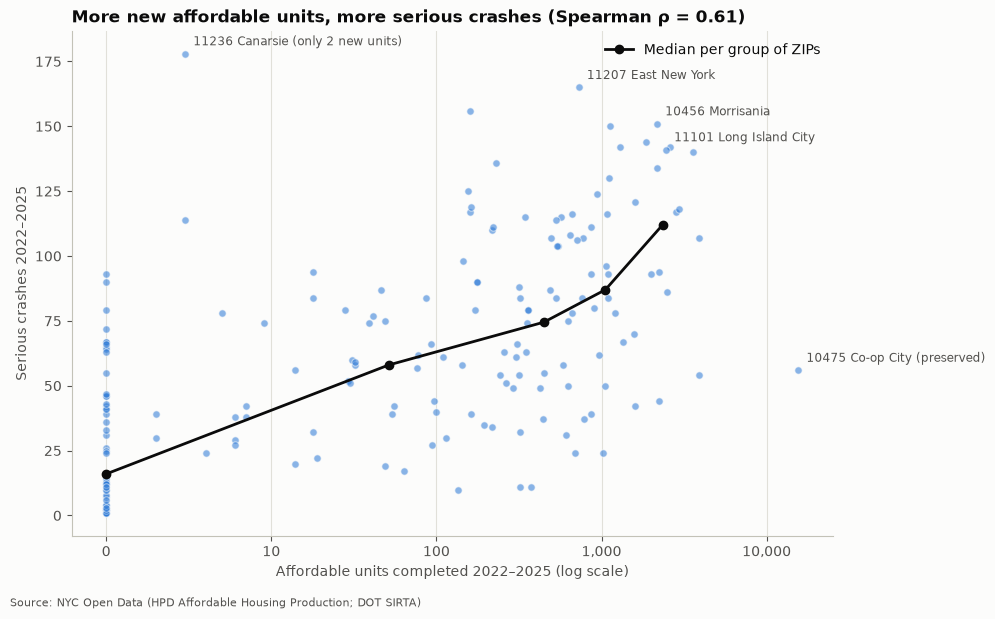

Spearman rho, all 185 ZIPs: 0.61 (p = 2.0e-20)
Spearman rho, only the 133 ZIPs with new units: 0.42 (p = 5.6e-07)


,x,y,zips
housing_group,,,
0,0.0,16.0,52
1–250,1.7,58.0,58
251–750,2.7,74.5,36
"751–1,500",3.0,87.0,21
"1,500+",3.4,112.0,18


In [89]:
rq1 = zip_summary.copy()
rq1["units_axis"] = np.log10(rq1["affordable_units"] + 1)
rq1["housing_group"] = pd.cut(rq1["affordable_units"], [-1, 0, 250, 750, 1500, np.inf],
                              labels=["0", "1–250", "251–750", "751–1,500", "1,500+"])
group_medians = rq1.groupby("housing_group", observed=True).agg(x=("units_axis", "median"), y=("serious_crashes", "median"),
                                                                zips=("zip_code", "size"))
rho_all = stats.spearmanr(rq1["affordable_units"], rq1["serious_crashes"])
with_housing = rq1[rq1["affordable_units"] > 0]
rho_housing = stats.spearmanr(with_housing["affordable_units"], with_housing["serious_crashes"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(rq1["units_axis"], rq1["serious_crashes"], s=28, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.8)
ax.plot(group_medians["x"], group_medians["y"], color=INK, linewidth=2, marker="o", markersize=6, label="Median per group of ZIPs")
for zip_code, label in [("10475", "10475 Co-op City (preserved)"), ("11207", "11207 East New York"),
                        ("10456", "10456 Morrisania"), ("11101", "11101 Long Island City"),
                        ("11236", "11236 Canarsie (only 2 new units)")]:
    row = rq1[rq1["zip_code"] == zip_code].iloc[0]
    ax.annotate(label, (row["units_axis"], row["serious_crashes"]), xytext=(6, 6), textcoords="offset points",
                fontsize=8.5, color=INK_SOFT)
ax.set_xticks([0, 1, 2, 3, 4], ["0", "10", "100", "1,000", "10,000"])
ax.grid(axis="both")
ax.legend(loc="upper right")
finish_chart(ax, f"More new affordable units, more serious crashes (Spearman ρ = {rho_all.statistic:.2f})",
             "Affordable units completed 2022–2025 (log scale)", "Serious crashes 2022–2025")
plt.show()
print(f"Spearman rho, all {len(rq1)} ZIPs: {rho_all.statistic:.2f} (p = {rho_all.pvalue:.1e})")
print(f"Spearman rho, only the {len(with_housing)} ZIPs with new units: {rho_housing.statistic:.2f} (p = {rho_housing.pvalue:.1e})")
group_medians.round(1)

**Answer: yes.** ZIP codes that received more new affordable units in 2022–2025 also recorded more serious crashes. The rank correlation is **ρ = 0.61** across all 185 ZIPs, and it stays clearly positive (**ρ = 0.42**) among only the 133 ZIPs that received new units, so the link is not just "housing vs no housing". The median ZIP with no new units had **16** serious crashes in four years; the median ZIP with more than 1,500 new units had **112**, 7 times more.

**Exceptions worth noticing:** 11236 (Canarsie, Brooklyn) had the most serious crashes in the city (178) but only 2 new affordable units. 10475 (Co-op City) has 15,507 units, all from preserving one existing complex, and only 56 crashes.

**Caution:** this is an association. Both affordable housing and serious crashes are concentrated in dense, busy neighbourhoods, so density and traffic volume probably explain part of the link. We cannot say that new housing causes crashes.

---
## RQ2 *(M1)*: In each borough, did serious crashes rise or fall alongside housing completions from 2022 to 2025?
**Why it matters:** RQ1 compares places. RQ2 compares **years**: if crashes rose where housing grew, that would be a warning sign for growing neighbourhoods.
**Chart choice:** a line chart is the form for **change over time**. The two measures have very different sizes (thousands of units, hundreds of crashes), and a chart with two y-axes would invent a relationship. So we **index both to 2022 = 100** on one shared axis, and draw one small panel per borough (small multiples) with only 2 lines each. Lecture 4 recommends at most 4–5 lines per chart.

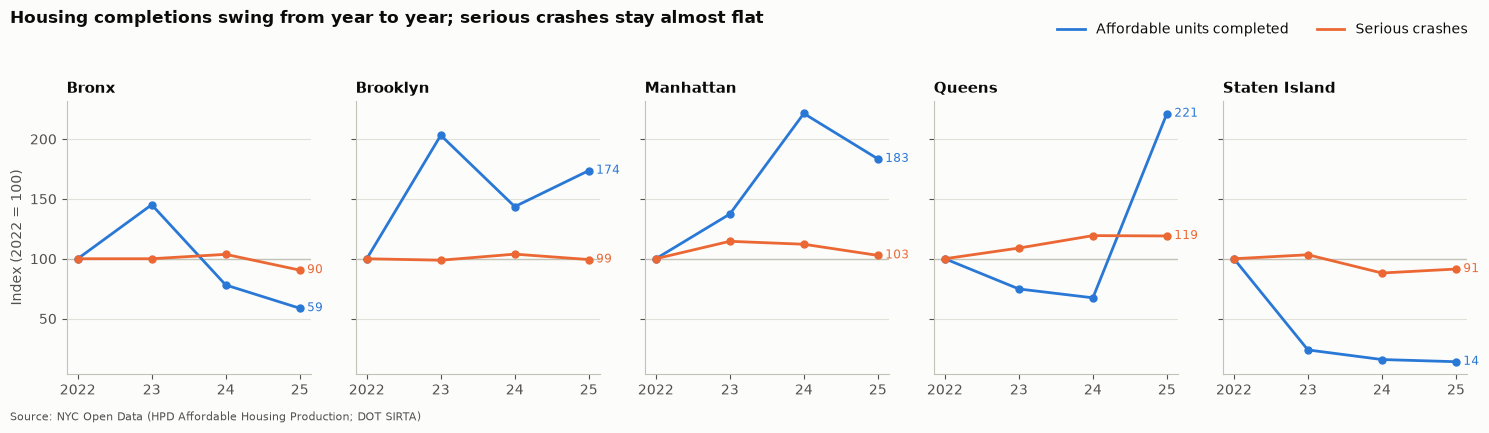

affordable_units                    serious_crashes               
year                      2022   2023  2024  2025            2022 2023 2024 2025
borough                                                                         
Bronx                    12006  17422  9373  7043             600  600  622  543
Brooklyn                  3469   7046  4979  6023             885  874  919  879
Manhattan                 2696   3702  5967  4945             570  653  639  586
Queens                    3450   2579  2324  7632             673  733  803  801
Staten Island              386     92    61    54             151  156  133  138

In [90]:
rq2 = borough_year.copy()
for measure in ["affordable_units", "serious_crashes"]:
    base_2022 = rq2[rq2["year"] == 2022].set_index("borough")[measure]
    rq2[f"{measure}_index"] = 100 * rq2[measure] / rq2["borough"].map(base_2022)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.8), sharey=True)
for ax, borough in zip(axes, BOROUGH_ORDER):
    data = rq2[rq2["borough"] == borough].sort_values("year")
    ax.axhline(100, color="#c3c2b7", linewidth=1)
    ax.plot(data["year"], data["affordable_units_index"], color=BLUE, linewidth=2, marker="o", markersize=5)
    ax.plot(data["year"], data["serious_crashes_index"], color=ORANGE, linewidth=2, marker="o", markersize=5)
    ax.set_xticks(WINDOW_YEARS, ["2022", "23", "24", "25"])
    ax.set_title(borough, fontsize=11)
    ax.text(2025.1, data["affordable_units_index"].iloc[-1], f"{data['affordable_units_index'].iloc[-1]:.0f}",
            color=BLUE, fontsize=8.5, va="center")
    ax.text(2025.1, data["serious_crashes_index"].iloc[-1], f"{data['serious_crashes_index'].iloc[-1]:.0f}",
            color=ORANGE, fontsize=8.5, va="center")
axes[0].set_ylabel("Index (2022 = 100)")
axes[0].plot([], [], color=BLUE, linewidth=2, label="Affordable units completed")
axes[0].plot([], [], color=ORANGE, linewidth=2, label="Serious crashes")
fig.legend(loc="upper right", ncol=2, frameon=False, bbox_to_anchor=(0.99, 1.06))
fig.suptitle("Housing completions swing from year to year; serious crashes stay almost flat",
             x=0.01, ha="left", fontweight="bold", y=1.06)
finish_chart(axes[-1], "Staten Island", None, None)
axes[-1].set_title("Staten Island", fontsize=11)
plt.show()
rq2.pivot(index="borough", columns="year", values=["affordable_units", "serious_crashes"])

**Answer: no clear year-to-year link.** Serious crashes stayed close to their 2022 level in every borough (index between 90 and 119). Housing completions jumped up and down (index from 14 to 221), because one large project finishing can double a borough's count in a single year. In no borough do the two lines move together. The only clear crash increase is in **Queens (+19% by 2025)**. Queens' housing completions jumped too, but only in 2025, after crashes had already risen in 2023–2024, so the timing does not suggest that new housing drove the increase.

**What it means:** the link found in RQ1 is about **places** (the same dense neighbourhoods get both), not about **years**.

**Caution:** four years is a short time series. Staten Island's housing numbers are very small (386 units in 2022, 54 in 2025), so its index swings strongly.

---
## RQ3 *(M2)*: Are new-construction buildings located in more dangerous ZIPs than preservation buildings?
**Why it matters:** in a **new-construction** building, every household is new to the area. In a **preservation** project the residents already live there; the city only keeps their rents affordable. If new construction goes to more dangerous ZIPs, the city is moving families *into* danger.
**Chart choice:** a box plot compares **distributions** between groups (Lecture 4). We add the individual buildings as faint dots, because a box alone can hide the shape (Lecture 4).

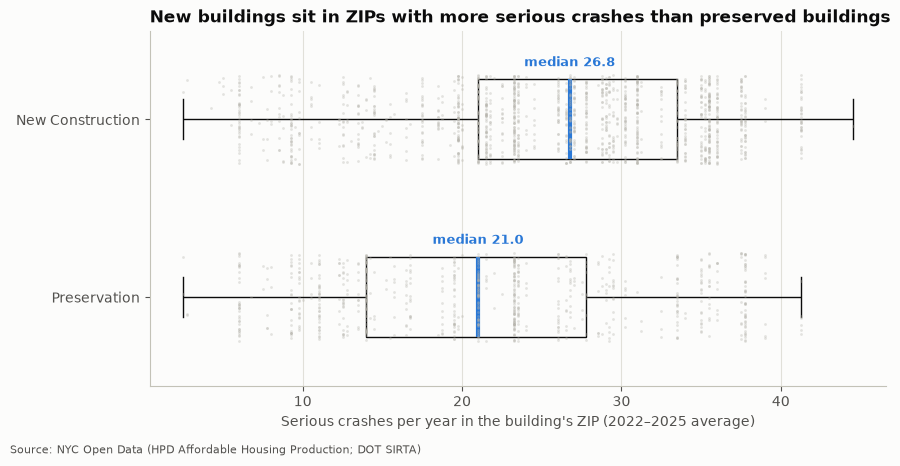

                   buildings  units  median  mean
construction_type                                
New Construction        1460  47905    26.8  25.5
Preservation             781  52152    21.0  21.4
Mann-Whitney U test p-value: 1.7e-24


In [91]:
rq3 = housing_window.dropna(subset=["zip_code"]).copy()
crashes_per_year_by_zip = zip_summary.set_index("zip_code")["serious_crashes"] / len(WINDOW_YEARS)
rq3["zip_crashes_per_year"] = rq3["zip_code"].map(crashes_per_year_by_zip)
type_order = ["New Construction", "Preservation"]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.stripplot(data=rq3, x="zip_crashes_per_year", y="construction_type", order=type_order, color=GRAY,
              size=2, alpha=0.35, jitter=0.25, ax=ax)
sns.boxplot(data=rq3, x="zip_crashes_per_year", y="construction_type", order=type_order, width=0.45,
            showfliers=False, boxprops=dict(facecolor="none", edgecolor=INK), medianprops=dict(color=BLUE, linewidth=3),
            whiskerprops=dict(color=INK), capprops=dict(color=INK), ax=ax)
medians_rq3 = rq3.groupby("construction_type")["zip_crashes_per_year"].median()
for i, building_type in enumerate(type_order):
    ax.text(medians_rq3[building_type], i - 0.3, f"median {medians_rq3[building_type]:.1f}", color=BLUE,
            ha="center", fontsize=9, fontweight="bold")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
finish_chart(ax, "New buildings sit in ZIPs with more serious crashes than preserved buildings",
             "Serious crashes per year in the building's ZIP (2022–2025 average)", "")
plt.show()
mann_whitney = stats.mannwhitneyu(rq3.loc[rq3["construction_type"] == "New Construction", "zip_crashes_per_year"],
                                  rq3.loc[rq3["construction_type"] == "Preservation", "zip_crashes_per_year"])
print(rq3.groupby("construction_type").agg(buildings=("building_id", "size"), units=("affordable_units", "sum"),
                                           median=("zip_crashes_per_year", "median"),
                                           mean=("zip_crashes_per_year", "mean")).round(1))
print(f"Mann-Whitney U test p-value: {mann_whitney.pvalue:.1e}")

**Answer: yes.** The median new-construction building is in a ZIP with **26.8** serious crashes per year, against **21.0** for preservation buildings, which is 28% more. The difference is very unlikely to be chance (Mann-Whitney U test, p < 0.001). We use this test because it compares two groups **without assuming a normal distribution**. The gap also appears **inside every large borough** (Bronx 30.2 vs 23.5, Brooklyn 26.0 vs 23.2, Manhattan 21.8 vs 12.8, Queens 24.0 vs 11.0), so it is not only because new buildings are in a different borough.

**What it means:** the buildings where every household is *new to the area* are the ones in the more dangerous ZIPs, and new residents do not yet know which crossings are dangerous.

**Caution:** new construction needs empty land, which is more common along wide, busy corridors. The type of street may explain part of the link.

---
## RQ4 *(M2)*: Do the lowest-income tenants live in more dangerous ZIPs than higher-income tenants?
**Why it matters:** this is an **equity** question. Low-income households are less likely to own a car and more likely to walk, so dangerous streets hurt them most.
**Method:** for every affordable unit completed in 2022–2025 we look up the serious crashes per year in its ZIP. Then we take the average **per unit**, separately for each income band. A band with many units in dangerous ZIPs gets a high value. The data comes from the long (tidy) income table built in Section 5.13.
**Chart choice:** a bar chart compares **magnitudes** across categories. The income bands have a natural order, so the bars use one blue that gets darker with income (an ordinal ramp), and the order is never sorted by value.

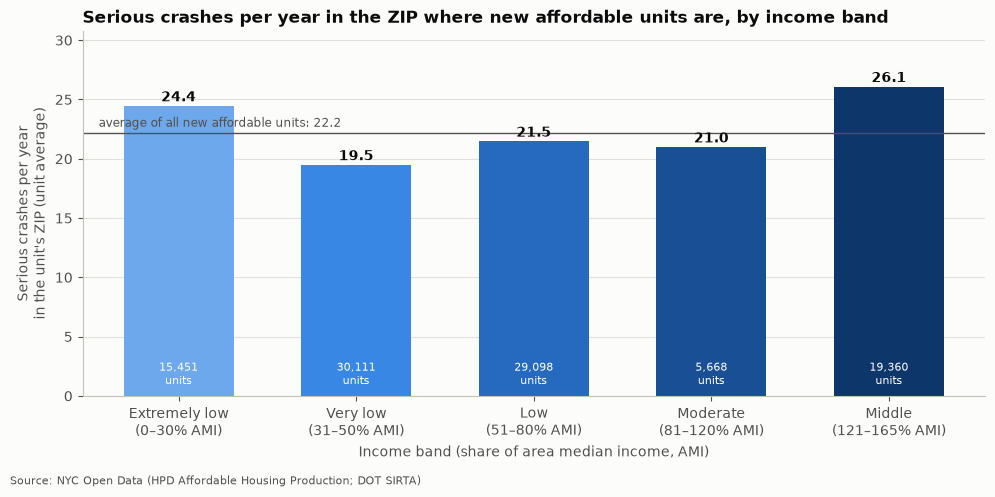

,units,all ZIPs,without Co-op City (10475)
income_band,,,
1. Extremely low (0–30% AMI),15451,24.4,24.4
2. Very low (31–50% AMI),30111,19.5,22.8
3. Low (51–80% AMI),29098,21.5,22.7
4. Moderate (81–120% AMI),5668,21.0,21.1
5. Middle (121–165% AMI),19360,26.1,26.1


In [92]:
rq4 = housing_income_long[housing_income_long["in_analysis_window"]].dropna(subset=["zip_code"]).copy()
rq4 = rq4[~rq4["income_band"].str.startswith("6.")]                      # superintendent units are not tenants
rq4["zip_crashes_per_year"] = rq4["zip_code"].map(crashes_per_year_by_zip)


def unit_weighted_crashes(df):
    return (df["units"] * df["zip_crashes_per_year"]).sum() / df["units"].sum()


band_exposure = rq4.groupby("income_band").apply(unit_weighted_crashes, include_groups=False).rename("all ZIPs")
band_exposure_no_coop = (rq4[rq4["zip_code"] != "10475"].groupby("income_band")
                         .apply(unit_weighted_crashes, include_groups=False).rename("without Co-op City (10475)"))
band_units = rq4.groupby("income_band")["units"].sum().rename("units")
all_units_average = unit_weighted_crashes(rq4)

fig, ax = plt.subplots(figsize=(10, 4.8))
labels = [band.split(". ", 1)[1].replace(" (", "\n(") for band in band_exposure.index]
bars = ax.bar(labels, band_exposure.values, color=BLUE_RAMP[2:7], width=0.62)
for bar, value, units in zip(bars, band_exposure.values, band_units.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.4, f"{value:.1f}", ha="center", fontweight="bold")
    ax.text(bar.get_x() + bar.get_width() / 2, 1, f"{units:,.0f}\nunits", ha="center", fontsize=8,
            color="white" if value > 0 else INK)
ax.axhline(all_units_average, color=INK_SOFT, linewidth=1)
ax.text(-0.45, all_units_average + 0.5, f"average of all new affordable units: {all_units_average:.1f}",
        color=INK_SOFT, fontsize=8.5, ha="left")
ax.set_ylim(0, band_exposure.max() * 1.18)
finish_chart(ax, "Serious crashes per year in the ZIP where new affordable units are, by income band",
             "Income band (share of area median income, AMI)", "Serious crashes per year\nin the unit's ZIP (unit average)")
plt.show()
pd.concat([band_units, band_exposure, band_exposure_no_coop], axis=1).round(1)

**Answer: partly yes, but it is not a straight line.** Extremely-low-income units (for households earning up to 30% of the area median) are in ZIPs with **24.4** serious crashes per year on average, **10% above** the average for all new affordable units (22.2).
- Very-low-income units look the safest (19.5), but that is caused by **one project**: Co-op City (10475) holds 38% of all very-low-income units, in a calmer ZIP. Without it, very low (22.8) and low (22.7) are much closer to extremely low.
- Middle-income units have the highest value (26.1), because many of them were built in busy ZIPs in the Bronx and in Long Island City (11101).

**What it means:** the poorest tenants, who are the most likely to walk, take the bus and not own a car, live in more dangerous ZIPs than the average affordable-housing tenant.

**Caution:** this measures the ZIP, not the block. One very large project can move a band's average, which is why we show the result with and without Co-op City.

---
## RQ5 *(M3)*: Do serious crashes near new affordable housing happen at different times of the day and week than crashes elsewhere?
**Why it matters:** if crashes near new homes peak at specific times, such as the school run or the evening return home, DOT can target enforcement and signal timing at those hours.
**Method:** crashes within 250 m of a building completed in 2022–2025 are "near new housing", all others are "elsewhere". For each group we compute the share of its crashes that fall in each time band × weekday cell, then subtract: **near minus elsewhere**, in percentage points. Crashes with the default time 00:00 are left out (Section 6.4).
**Chart choice:** a heatmap shows a **grid of values**. Because the values are differences that can be positive or negative, we use a **diverging** scale: orange = more common near new housing, blue = less common, gray = no difference.

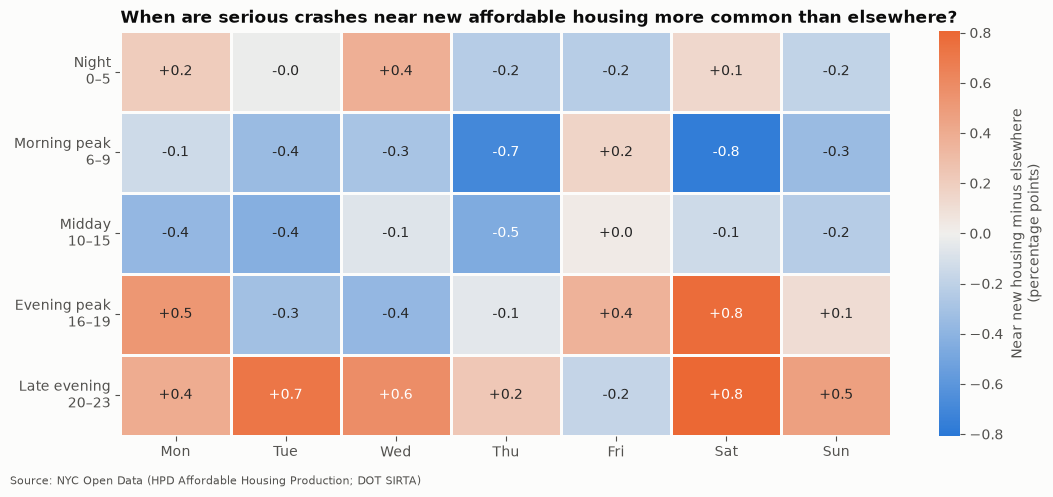

Crashes used: {'elsewhere': 5543, 'near': 3973}


,near new housing (%),elsewhere (%),difference (pp)
time_band,,,
Night\n0–5,14.2,14.1,0.1
Morning peak\n6–9,11.8,14.3,-2.4
Midday\n10–15,27.3,28.9,-1.7
Evening peak\n16–19,25.5,24.5,1.0
Late evening\n20–23,21.2,18.1,3.0


In [93]:
TIME_BANDS = ["Night\n0–5", "Morning peak\n6–9", "Midday\n10–15", "Evening peak\n16–19", "Late evening\n20–23"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
rq5 = located_crashes[~located_crashes["time_unknown"]].copy()
rq5["time_band"] = pd.cut(rq5["hour"], [-1, 5, 9, 15, 19, 23], labels=TIME_BANDS)
rq5["group"] = np.where(rq5["near_new_housing"], "near", "elsewhere")


def time_share(df):
    table = pd.crosstab(df["time_band"], df["weekday"]).reindex(index=TIME_BANDS, columns=WEEKDAYS).fillna(0)
    return 100 * table / table.values.sum()


share_near = time_share(rq5[rq5["group"] == "near"])
share_elsewhere = time_share(rq5[rq5["group"] == "elsewhere"])
difference = share_near - share_elsewhere
limit = np.abs(difference.values).max()

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(difference, annot=True, fmt="+.1f", cmap=sns.blend_palette([BLUE, DIVERGING_MID, ORANGE], as_cmap=True),
            vmin=-limit, vmax=limit, linewidths=2, linecolor=SURFACE, ax=ax,
            cbar_kws={"label": "Near new housing minus elsewhere\n(percentage points)"})
ax.grid(False)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([d[:3] for d in WEEKDAYS], rotation=0)
ax.set_yticklabels(TIME_BANDS, rotation=0)
finish_chart(ax, "When are serious crashes near new affordable housing more common than elsewhere?", None, None)
plt.show()
band_totals = pd.DataFrame({"near new housing (%)": share_near.sum(axis=1), "elsewhere (%)": share_elsewhere.sum(axis=1)})
band_totals["difference (pp)"] = band_totals["near new housing (%)"] - band_totals["elsewhere (%)"]
print("Crashes used:", rq5["group"].value_counts().to_dict())
band_totals.round(1)

**Answer: yes, slightly. The evening is more dangerous near new homes and the morning is less.** Near new affordable housing, **21.2%** of serious crashes happen in the late evening (20:00–23:59), compared with **18.1%** elsewhere (+3.0 percentage points). With the evening peak (16:00–19:59, +1.0) that is 4 points more of the crashes in the evening. The **morning peak** (6:00–9:59) is **2.4 points lower** near new housing. The strongest single cells are Saturday evening and Saturday late evening (+0.8 each).

**What it means:** around residential blocks, danger peaks when people come home or go out and when it is dark, not at the morning commute. The matching tools are evening speed enforcement and better street lighting.

**Caution:** the differences are small (at most 3 points). The 204 crashes with an unknown time (00:00) were left out. Fatal crashes after 2022 have no coordinates (Section 4.7), so this result describes mainly severe-injury crashes.

---
## RQ6 *(M3)*: Are serious crashes near new affordable housing more often on local streets than on highways?
**Why it matters:** local streets can be redesigned quickly (speed humps, daylighting, bike lanes, signal timing). Highways are much harder to change. If the danger near new homes is on local streets, the city has cheap, fast tools to fix it.
**Method:** DOT gives every highway crash a *highway reference marker*. A crash without one happened on a local street.
**Chart choice:** a **100% stacked bar** shows a part-to-whole split for each group. We use horizontal bars because the group names are long.

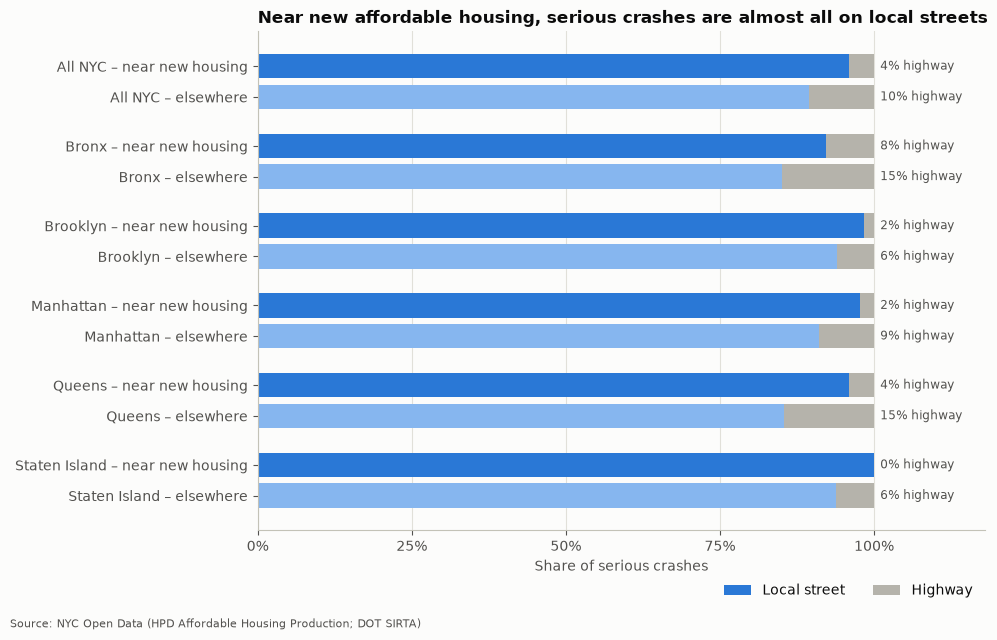

,radius (m),highway share near (%),highway share elsewhere (%)
0,150,3.2,9.3
1,250,4.1,10.5
2,500,5.3,13.0


In [94]:
rq6 = located_crashes.copy()
rq6["group"] = np.where(rq6["near_new_housing"], "near new housing", "elsewhere")
highway_share = rq6.groupby(["borough", "group"])["on_highway"].mean().unstack()
highway_share.loc["All NYC"] = rq6.groupby("group")["on_highway"].mean()
row_order = [(b, g) for b in ["All NYC"] + BOROUGH_ORDER for g in ["near new housing", "elsewhere"]]
values = [highway_share.loc[b, g] * 100 for b, g in row_order]

fig, ax = plt.subplots(figsize=(10, 6.2))
y_positions = []
y = 0
for i, (borough, group) in enumerate(row_order):
    y_positions.append(y)
    y += 1 if group == "near new housing" else 1.6
y_positions = np.array(y_positions)
local = 100 - np.array(values)
ax.barh(y_positions, local, color=[BLUE if g == "near new housing" else "#86b6ef" for _, g in row_order], height=0.8,
        label="Local street")
ax.barh(y_positions, values, left=local, color=GRAY, height=0.8, label="Highway")
for yp, value in zip(y_positions, values):
    ax.text(101, yp, f"{value:.0f}% highway", va="center", fontsize=8.5, color=INK_SOFT)
ax.set_yticks(y_positions, [f"{b} – {g}" for b, g in row_order])
ax.invert_yaxis()
ax.set_xlim(0, 118)
ax.set_xticks(range(0, 101, 25))
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right", ncol=2, bbox_to_anchor=(1, -0.16))
finish_chart(ax, "Near new affordable housing, serious crashes are almost all on local streets", "Share of serious crashes", None)
plt.show()


def share_by_radius(radius, column):
    near = located_crashes["distance_to_new_housing_m"] <= radius
    return located_crashes.loc[near, column].mean() * 100, located_crashes.loc[~near, column].mean() * 100


sensitivity_rq6 = pd.DataFrame([(r, *share_by_radius(r, "on_highway")) for r in [150, 250, 500]],
                               columns=["radius (m)", "highway share near (%)", "highway share elsewhere (%)"]).round(1)
sensitivity_rq6

**Answer: yes, strongly.** Only **4%** of serious crashes near new affordable housing are on highways, against **10%** elsewhere. In other words, **96% of the danger near new homes is on local streets**. The pattern holds in every borough (for example Queens 4% vs 15%, Bronx 8% vs 15%) and at every radius we tested (150 m: 3% vs 9%; 500 m: 5% vs 13%), so it does not depend on our 250 m choice.

**What it means:** this is good news for policy. Local streets can be fixed quickly and cheaply with tools DOT already uses (speed cameras, raised crossings, daylighting corners, protected bike lanes), while highways are much harder to change.

**Caution:** the highway reference marker is our only highway indicator. A highway crash recorded without a marker would be counted as a local street. Fatal crashes after 2022 have no coordinates, so this result describes mainly severe-injury crashes.

---
## RQ7 *(M4)*: Which ZIP codes are "double hotspots", in the top 25% for both new affordable units and serious crashes?
**Why it matters:** these are the places where the city's housing investment and its traffic danger meet. They are natural first candidates for street redesign.
**Method:** a ZIP is in the top 25% (top quartile) for housing if its new affordable units are above the 75th percentile of all ZIPs, and likewise for crashes. That gives four groups.
**Chart choice:** a **map** shows spatial patterns. Each circle is a ZIP at its centre point (Section 9.4), sized by new affordable units. Only the double hotspots get the strong orange; the other groups are softer, so the eye goes to the answer first (Lecture 3: pre-attentive processing).

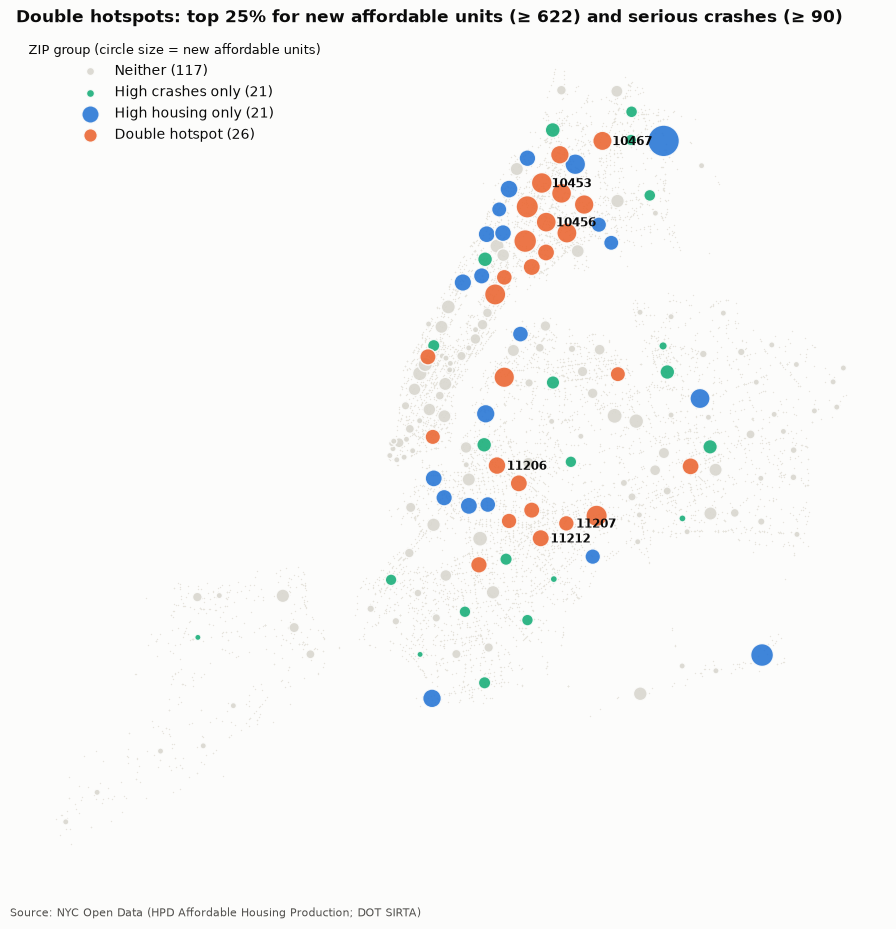

Thresholds (75th percentile): 622 units | 90 serious crashes
Double hotspots per borough: {'Bronx': 11, 'Brooklyn': 8, 'Manhattan': 4, 'Queens': 3}
Share of all new affordable units (ZIP-level) in double hotspots: 43%


,zip_code,borough,community_district,affordable_units,serious_crashes,deaths
100,11207,Brooklyn,BK 05,725,165,9
66,10456,Bronx,BX 03,2163,151,5
105,11212,Brooklyn,BK 16,1131,150,6
77,10467,Bronx,BX 12,1866,144,17
99,11206,Brooklyn,BK 01,1296,142,8
63,10453,Bronx,BX 05,2598,142,5
89,11101,Queens,QN 02,2451,141,15
62,10452,Bronx,BX 04,3561,140,13
67,10457,Bronx,BX 06,2159,134,6
64,10454,Bronx,BX 01,1104,130,10


In [95]:
units_q75 = zip_summary["affordable_units"].quantile(0.75)
crashes_q75 = zip_summary["serious_crashes"].quantile(0.75)
zip_summary["hotspot_group"] = np.select(
    [(zip_summary["affordable_units"] >= units_q75) & (zip_summary["serious_crashes"] >= crashes_q75),
     zip_summary["affordable_units"] >= units_q75,
     zip_summary["serious_crashes"] >= crashes_q75],
    ["Double hotspot", "High housing only", "High crashes only"], default="Neither")
HOTSPOT_COLORS = {"Double hotspot": ORANGE, "High housing only": BLUE, "High crashes only": AQUA, "Neither": "#d9d7cf"}

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(located_crashes["longitude"], located_crashes["latitude"], s=1, color="#e6e4dc", linewidths=0, zorder=1)
for group in ["Neither", "High crashes only", "High housing only", "Double hotspot"]:
    data = zip_summary[zip_summary["hotspot_group"] == group]
    ax.scatter(data["longitude"], data["latitude"], s=20 + np.sqrt(data["affordable_units"]) * 4,
               color=HOTSPOT_COLORS[group], edgecolor=SURFACE, linewidth=1, alpha=0.9, zorder=2,
               label=f"{group} ({len(data)})")
top_double = zip_summary[zip_summary["hotspot_group"] == "Double hotspot"].nlargest(6, "serious_crashes")
for _, row in top_double.iterrows():
    ax.annotate(row["zip_code"], (row["longitude"], row["latitude"]), xytext=(7, -3), textcoords="offset points",
                fontsize=8.5, fontweight="bold", color=INK)
ax.set_aspect(1.3)
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="upper left", title="ZIP group (circle size = new affordable units)", title_fontsize=9, markerscale=0.7)
finish_chart(ax, f"Double hotspots: top 25% for new affordable units (≥ {units_q75:,.0f}) and serious crashes (≥ {crashes_q75:.0f})")
plt.show()
print("Thresholds (75th percentile):", round(units_q75), "units |", round(crashes_q75), "serious crashes")
double_hotspots = (zip_summary[zip_summary["hotspot_group"] == "Double hotspot"]
                   .sort_values("serious_crashes", ascending=False)
                   [["zip_code", "borough", "community_district", "affordable_units", "serious_crashes", "deaths"]])
print("Double hotspots per borough:", double_hotspots["borough"].value_counts().to_dict())
print("Share of all new affordable units (ZIP-level) in double hotspots:",
      f"{double_hotspots['affordable_units'].sum() / zip_summary['affordable_units'].sum():.0%}")
double_hotspots.head(10)

**Answer: 26 ZIP codes are double hotspots**: 11 in the Bronx, 8 in Brooklyn, 4 in Manhattan, 3 in Queens, and none in Staten Island. The map shows two clear clusters: the **South and West Bronx** (10451–10457, 10459–10460, 10467–10468) and **central and eastern Brooklyn** (11206–11208, 11212–11213, 11221, 11226, 11233).

These 26 ZIPs are only **14% of all ZIPs**, but they received **43% of all new affordable units** (with a known ZIP) and **40% of all deeply affordable units**, and they recorded **27% of the city's serious crashes**.

**What it means:** more than 40% of the city's new affordable housing went to a small group of neighbourhoods that also have some of the most dangerous streets. Focusing street-safety work on these 26 ZIPs would protect a large share of new residents.

**Caution:** the 25% cut-off is a choice; a ZIP just below a threshold is not much safer than one just above it. The website lets users explore every ZIP.

---
## RQ8 *(M4)*: Are repeat-danger locations more common near new affordable buildings?
**Why it matters:** SIRTA records, for every crash, how many *similar* serious crashes happened at the **same spot** in the previous 3 years. A crash at such a spot is a sign of a **known, unfixed danger**. Those spots are the cheapest wins for the city: the problem is known and the place is known.
**Method:** share of crashes with `similar_severe_3y > 0`, only for crashes where this value is known (Section 6.11).
**Chart choice:** a grouped bar chart compares two groups inside each borough. "Near new housing" is the strong blue and "elsewhere" is gray, because the near group is the focus.

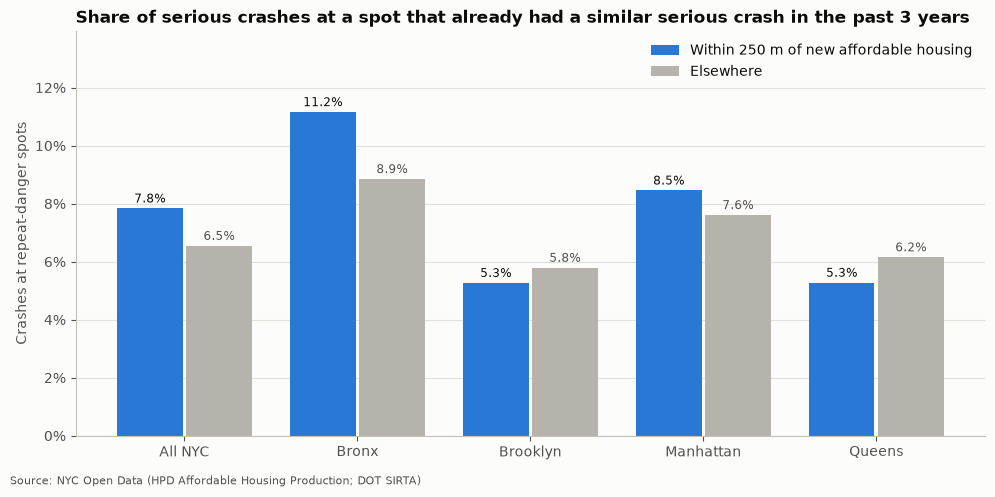

Crashes used: 8550


,radius (m),repeat share near (%),repeat share elsewhere (%)
0,150,8.6,6.6
1,250,7.8,6.5
2,500,7.8,5.6


In [96]:
rq8 = located_crashes[located_crashes["at_repeat_location"].notna()].copy()
rq8["at_repeat_location"] = rq8["at_repeat_location"].astype(bool)
repeat_share = rq8.groupby(["borough", "near_new_housing"])["at_repeat_location"].mean().unstack() * 100
repeat_share.loc["All NYC"] = rq8.groupby("near_new_housing")["at_repeat_location"].mean() * 100
repeat_share = repeat_share.reindex(["All NYC"] + BOROUGH_ORDER[:4])   # Staten Island: only 13 crashes near new housing

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(repeat_share))
ax.bar(x - 0.2, repeat_share[True], width=0.38, color=BLUE, label="Within 250 m of new affordable housing")
ax.bar(x + 0.2, repeat_share[False], width=0.38, color=GRAY, label="Elsewhere")
for xi, (near_value, far_value) in enumerate(zip(repeat_share[True], repeat_share[False])):
    ax.text(xi - 0.2, near_value + 0.2, f"{near_value:.1f}%", ha="center", fontsize=8.5, color=INK)
    ax.text(xi + 0.2, far_value + 0.2, f"{far_value:.1f}%", ha="center", fontsize=8.5, color=INK_SOFT)
ax.set_xticks(x, repeat_share.index)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, repeat_share.max().max() * 1.25)
ax.legend(loc="upper right")
finish_chart(ax, "Share of serious crashes at a spot that already had a similar serious crash in the past 3 years",
             None, "Crashes at repeat-danger spots")
plt.show()
sensitivity_rq8 = pd.DataFrame([(r, *share_by_radius(r, "at_repeat_location")) for r in [150, 250, 500]],
                               columns=["radius (m)", "repeat share near (%)", "repeat share elsewhere (%)"]).round(1)
print("Crashes used:", len(rq8))
sensitivity_rq8

**Answer: across the city, yes, but it depends strongly on the borough.** Citywide, **7.8%** of serious crashes near new affordable housing happened at a spot that already had a similar serious crash in the previous three years, against **6.5%** elsewhere. The result is the same at 150 m (8.6% vs 6.6%) and 500 m (7.8% vs 5.6%).

But the gap comes mainly from the **Bronx (11.2% vs 8.9%)** and Manhattan (8.5% vs 7.6%). In **Brooklyn and Queens it is the other way round** (5.3% vs 5.8%; 5.3% vs 6.2%). Part of the citywide gap exists only because many "near" crashes are in the Bronx, where repeat spots are common in general. A citywide average can hide opposite patterns inside the groups, so we always check by borough.

**What it means:** in the Bronx, new affordable homes are being built next to danger spots that were **already known**. These are the cheapest places to act, because DOT already knows where the problem is.

**Caution:** Staten Island is not shown (only 13 crashes there were near new housing). The "similar crash" field is missing for 1,393 crashes, which we left out instead of counting them as zero. Fatal crashes after 2022 have no coordinates, so this result describes mainly severe-injury crashes.

---
## RQ9 *(M5)*: Do buildings where most affordable apartments are family-sized (2+ bedrooms) have fewer serious crashes around them?
**Why it matters:** family apartments mean children, who walk to school and play outside. If family buildings are on calmer streets, that is good news. If not, they are the first place to add school-zone safety.
**Method:** for every building completed in 2022–2025 we count the serious crashes within 250 m (2022–2025). We compare three groups: under 25%, 25–50%, and over 50% of the building's affordable units with 2+ bedrooms. We compare **inside each borough**, because boroughs differ a lot in density (Manhattan has far more crashes per block than Staten Island).
**Chart choice:** grouped bars by borough. The three groups are ordered, so they use three steps of one blue (light = few family units, dark = mostly family units).

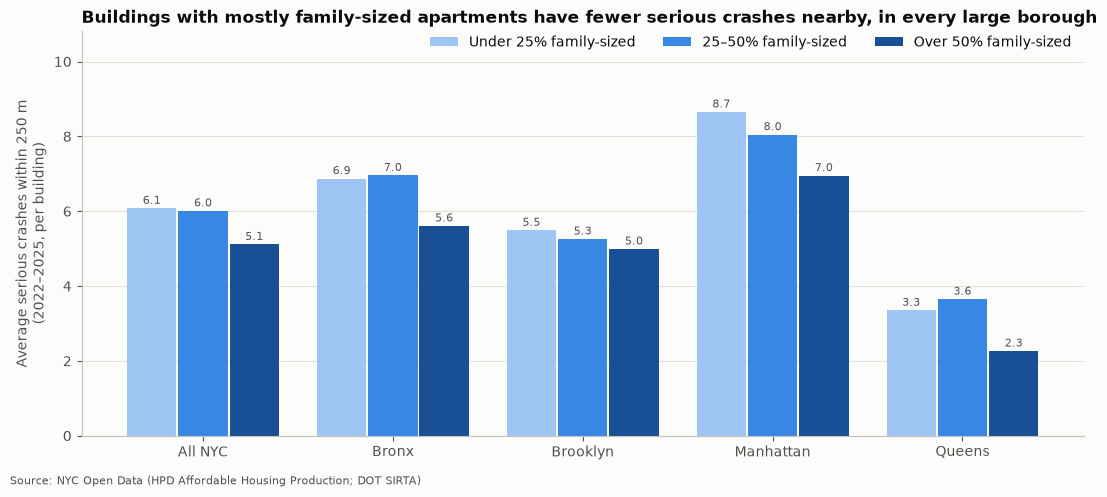

Buildings per group:


family_group,Under 25% family-sized,25–50% family-sized,Over 50% family-sized
borough,,,
Bronx,312,198,288
Brooklyn,279,211,349
Manhattan,89,65,143
Queens,103,68,126
Staten Island,8,0,1


In [97]:
rq9 = new_buildings.dropna(subset=["family_share"]).copy()
FAMILY_GROUPS = ["Under 25% family-sized", "25–50% family-sized", "Over 50% family-sized"]
rq9["family_group"] = pd.cut(rq9["family_share"], [-0.01, 0.25, 0.5, 1.0], labels=FAMILY_GROUPS)
family_means = rq9.groupby(["borough", "family_group"], observed=False)["crashes_within_250m"].mean().unstack()
family_means.loc["All NYC"] = rq9.groupby("family_group", observed=False)["crashes_within_250m"].mean()
family_counts = rq9.groupby(["borough", "family_group"], observed=False).size().unstack()
family_means = family_means.reindex(["All NYC"] + BOROUGH_ORDER[:4])   # Staten Island: only 9 new buildings

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(family_means))
for offset, group, color in zip([-0.27, 0, 0.27], FAMILY_GROUPS, [BLUE_RAMP[1], BLUE_RAMP[3], BLUE_RAMP[5]]):
    ax.bar(x + offset, family_means[group], width=0.26, color=color, label=group)
    for xi, value in zip(x, family_means[group]):
        if pd.notna(value):
            ax.text(xi + offset, value + 0.12, f"{value:.1f}", ha="center", fontsize=8, color=INK_SOFT)
ax.set_xticks(x, family_means.index)
ax.legend(loc="upper right", ncol=3, bbox_to_anchor=(1, 1.02))
ax.set_ylim(0, family_means.max().max() * 1.25)
finish_chart(ax, "Buildings with mostly family-sized apartments have fewer serious crashes nearby, in every large borough",
             None, "Average serious crashes within 250 m\n(2022–2025, per building)")
plt.show()
print("Buildings per group:")
family_counts

**Answer: yes.** Buildings where more than half of the affordable apartments have 2+ bedrooms had on average **5.1** serious crashes within 250 m in 2022–2025, against **6.1** for buildings with mostly studios and 1-bedrooms, 16% fewer. The pattern holds **inside each of the four large boroughs** (Bronx 5.6 vs 6.9, Brooklyn 5.0 vs 5.5, Manhattan 7.0 vs 8.7, Queens 2.3 vs 3.3), so it does not come from family buildings being in a calmer borough.

**What it means:** good news. The buildings with the most children are, on average, on calmer blocks. But "calmer" still means about 5 serious crashes within a 3-minute walk in four years, so school-zone safety still matters.

**Caution:** family buildings are often lower-rise buildings on side streets. The type of street, not the size of the apartments, probably explains most of the difference. Staten Island is not shown (only 9 new buildings). The counts include only crashes with coordinates, which leaves out fatal crashes after 2022.

---
## RQ10 *(M5)*: Is a serious crash more likely to be deadly in ZIPs with more new affordable housing, or with less?
**Why it matters:** the number of crashes shows how *often* people get hurt. The share of crashes that kill someone shows how *severe* crashes are. Deadly crashes are linked to speed, and wide fast roads are common at the edge of the city, where less housing is built.
**Method:** we split ZIPs into three groups: no new affordable units, lower growth (below the median of ZIPs with new units) and higher growth (above it). For each group we compute **deaths per 100 serious crashes**, a rate rather than a count. A chi-square test checks whether the share of fatal crashes really differs between the groups.
**Chart choice:** a dot plot shows a rate per group without implying a "total". Each row is a borough, and each dot is a group.

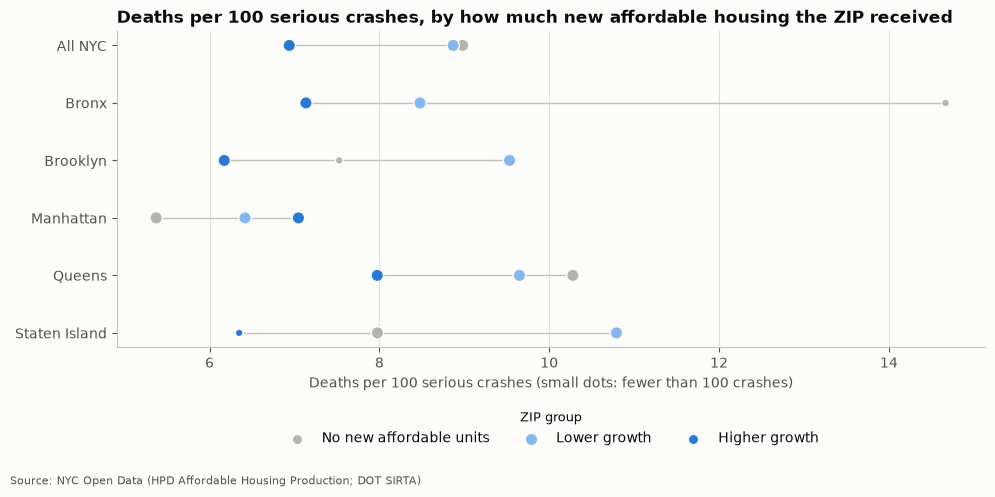

Median new units among ZIPs with new housing: 319
Chi-square test (fatal vs non-fatal crashes across the 3 groups): p = 0.002



Robustness check, deaths per 100 serious crashes:
                         all ZIPs (main result)  without street-imputed ZIPs
growth_group                                                                
No new affordable units                     9.0                          5.2
Lower growth                                8.9                          7.1
Higher growth                               6.9                          5.4


serious_crashes  deaths  fatal_crashes  deaths_per_100
borough       growth_group                                                                   
All NYC       Higher growth                       5923     411            393             6.9
              Lower growth                        4172     370            351             8.9
              No new affordable units             1481     133            122             9.0
Bronx         Higher growth                       1836     131            125             7.1
              Lower growth                         401      34             33             8.5
              No new affordable units               75      11             10            14.7
Brooklyn      Higher growth                       1879     116            114             6.2
              Lower growth                        1521     145            137             9.5
              No new affordable units               93       7              7             7.5
Manhattan     Higher growth                       1192      84             75             7.0
              Lower growth                         857      55             53             6.4
              No new affordable units              242      13             13             5.4
Queens        Higher growth                        953      76             75             8.0
              Lower growth                        1254     121            114             9.6
              No new affordable units              720      74             68            10.3
Staten Island Higher growth                         63       4              4             6.3
              Lower growth                         139      15             14            10.8
              No new affordable units              351      28             24             8.0

In [98]:
median_growth = zip_summary.loc[zip_summary["affordable_units"] > 0, "affordable_units"].median()
zip_summary["growth_group"] = np.select(
    [zip_summary["affordable_units"] == 0, zip_summary["affordable_units"] < median_growth],
    ["No new affordable units", "Lower growth"], default="Higher growth")
GROWTH_ORDER = ["No new affordable units", "Lower growth", "Higher growth"]
GROWTH_COLORS = {"No new affordable units": GRAY, "Lower growth": "#86b6ef", "Higher growth": BLUE}

rq10 = zip_summary.groupby(["borough", "growth_group"])[["serious_crashes", "deaths", "fatal_crashes"]].sum()
rq10_all = zip_summary.groupby("growth_group")[["serious_crashes", "deaths", "fatal_crashes"]].sum()
rq10_all.index = pd.MultiIndex.from_product([["All NYC"], rq10_all.index], names=["borough", "growth_group"])
rq10 = pd.concat([rq10_all, rq10])
rq10["deaths_per_100"] = 100 * rq10["deaths"] / rq10["serious_crashes"]

fig, ax = plt.subplots(figsize=(10, 4.8))
rows = ["All NYC"] + BOROUGH_ORDER
for group in GROWTH_ORDER:
    data = rq10.xs(group, level="growth_group").reindex(rows)
    sizes = np.where(data["serious_crashes"] >= 100, 80, 30)
    ax.scatter(data["deaths_per_100"], np.arange(len(rows)), s=sizes, color=GROWTH_COLORS[group],
               edgecolor=SURFACE, linewidth=1, zorder=3, label=group)
for i, borough in enumerate(rows):
    row_values = rq10.loc[borough, "deaths_per_100"]
    ax.plot([row_values.min(), row_values.max()], [i, i], color="#c3c2b7", linewidth=1, zorder=1)
ax.set_yticks(np.arange(len(rows)), rows)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="upper center", title="ZIP group", title_fontsize=9, ncol=3, bbox_to_anchor=(0.5, -0.16))
finish_chart(ax, "Deaths per 100 serious crashes, by how much new affordable housing the ZIP received",
             "Deaths per 100 serious crashes (small dots: fewer than 100 crashes)", None)
plt.show()
contingency = rq10_all.assign(non_fatal=lambda d: d["serious_crashes"] - d["fatal_crashes"])[["fatal_crashes", "non_fatal"]]
chi2 = stats.chi2_contingency(contingency.to_numpy())
print(f"Median new units among ZIPs with new housing: {median_growth:,.0f}")
print(f"Chi-square test (fatal vs non-fatal crashes across the 3 groups): p = {chi2.pvalue:.3f}")

# Robustness check: the same rates without the ZIPs filled from street names (Section 6.9)
crash_growth = crashes_window.dropna(subset=["zip_code"]).assign(
    growth_group=lambda d: d["zip_code"].map(zip_summary.set_index("zip_code")["growth_group"]))


def deaths_per_100(rows):
    return 100 * rows["fatalities"].sum() / len(rows)


robustness_rq10 = pd.DataFrame({
    "all ZIPs (main result)": crash_growth.groupby("growth_group").apply(deaths_per_100, include_groups=False),
    "without street-imputed ZIPs": crash_growth[crash_growth["zip_source"] != "imputed (street)"]
                                   .groupby("growth_group").apply(deaths_per_100, include_groups=False),
}).reindex(GROWTH_ORDER).round(1)
print("\nRobustness check, deaths per 100 serious crashes:")
print(robustness_rq10)
rq10.round(1)

**Answer: crashes in the ZIPs with the most new affordable housing are the least deadly.** Citywide, there were **6.9 deaths per 100 serious crashes** in higher-growth ZIPs, against **8.9** in lower-growth ZIPs and **9.0** in ZIPs with no new affordable units. The chi-square test (p = 0.002) shows the difference is very unlikely to be chance. Higher-growth ZIPs have the lowest rate in four of the five boroughs; **Manhattan is the exception**.

**Robustness check:** without the ZIPs filled from street names (Section 6.9), higher-growth ZIPs still have the lowest rate (5.4 vs 7.1 and 5.2). But the rate for ZIPs with **no** new housing falls from 9.0 to 5.2, because most of their missing deaths come back only through that step. Leaving the fatal crashes without a ZIP out would have hidden almost half of the deaths in these areas. This is a clear example of why our cleaning decisions matter.

**What it means:** together with RQ1 the picture is: high-growth ZIPs have **more** serious crashes, but each crash is **less often deadly**. One possible explanation, which we did not test, is **speed**: crowded streets are slower, while the outer neighbourhoods have wider, faster roads. It is not explained by highways: only 7% of crashes in lower-growth ZIPs were on highways.

**Caution:** Staten Island and the "no new housing" groups have few crashes (small dots), so their values are less stable.

---
## RQ11 *(M6)*: Near buildings completed in 2023–2025, were there fewer or more serious crashes in the 12 months after completion than in the 12 months before?
**Why it matters:** new buildings bring new residents, deliveries and construction traffic, and sometimes street improvements. Before/after comparisons are how the city evaluates street projects too.
**Method:**
1. We take buildings completed between January 2023 and March 2025, so both 12-month windows lie inside the crash data (January 2022 – March 2026).
2. For each building we count serious crashes within 250 m in the 12 months **before** and **after** its completion date.
3. **A trap we had to avoid:** the share of crashes that have coordinates changes from year to year (66% in 2024 vs 88% in 2025, Section 4.7). A raw before/after count would partly measure *data quality*, not safety. So we **adjust the "after" count by the citywide change**: if the city as a whole had 4% fewer located crashes in the after-period, we scale the after-count up by the same 4%. What remains is the *local* change around the building, not affected by citywide ups and downs or by how many crashes have coordinates.

**Chart choice:** a **dumbbell chart** is the standard form for **before → after per group**: gray dot = before, blue dot = after, connected by a line.

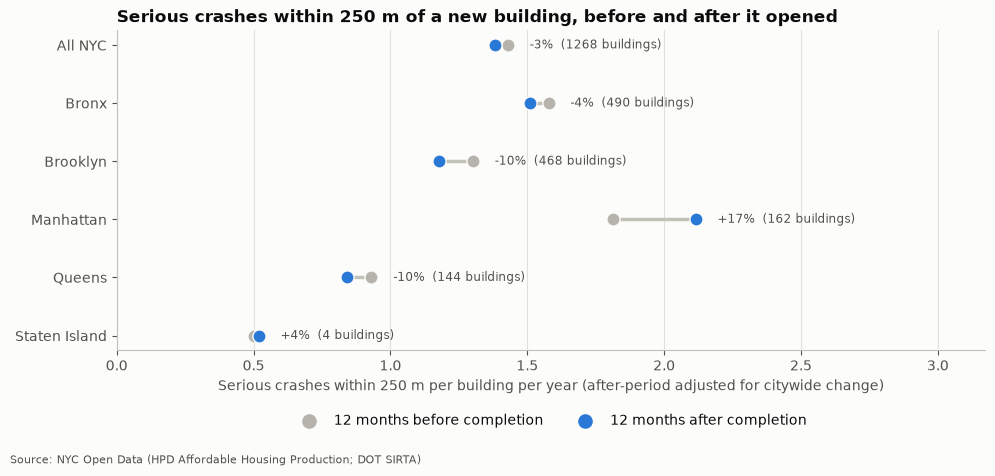

,near_before,near_after,city_before,city_after,buildings,before_per_building,after_per_building_adjusted,change_%
borough,,,,,,,,
All NYC,1812,1688,3061054,2947293,1268.0,1.43,1.38,-3.25
Bronx,773,706,1190142,1134801,490.0,1.58,1.51,-4.21
Brooklyn,609,535,1125066,1093737,468.0,1.30,1.18,-9.63
Manhattan,294,327,390627,372836,162.0,1.81,2.11,16.53
Queens,134,118,345659,336696,144.0,0.93,0.84,-9.60
Staten Island,2,2,9560,9223,4.0,0.50,0.52,3.65


In [99]:
all_located = crashes.dropna(subset=["latitude", "longitude"]).reset_index(drop=True)   # includes Jan–Mar 2026
all_located_tree = BallTree(to_radians(all_located), metric="haversine")
crash_dates = all_located["crash_date"].to_numpy()
sorted_dates = np.sort(crash_dates)
ONE_YEAR = pd.Timedelta(days=365)

rq11 = new_buildings[new_buildings["building_completion_date"].between("2023-01-01", "2025-03-31")].copy()
nearby = all_located_tree.query_radius(to_radians(rq11), r=NEAR_RADIUS_M / EARTH_RADIUS_M)


def count_in_window(dates, start, end):
    """Number of dates with start <= date < end."""
    return int(((dates >= np.datetime64(start)) & (dates < np.datetime64(end))).sum())


def city_count(start, end):
    return int(np.searchsorted(sorted_dates, np.datetime64(end)) - np.searchsorted(sorted_dates, np.datetime64(start)))


records = []
for completion, crash_index in zip(rq11["building_completion_date"], nearby):
    dates_near = crash_dates[crash_index]
    records.append({
        "near_before": count_in_window(dates_near, completion - ONE_YEAR, completion),
        "near_after": count_in_window(dates_near, completion, completion + ONE_YEAR),
        "city_before": city_count(completion - ONE_YEAR, completion),
        "city_after": city_count(completion, completion + ONE_YEAR),
    })
rq11 = pd.concat([rq11.reset_index(drop=True), pd.DataFrame(records)], axis=1)

rq11_borough = rq11.groupby("borough")[["near_before", "near_after", "city_before", "city_after"]].sum()
rq11_borough.loc["All NYC"] = rq11[["near_before", "near_after", "city_before", "city_after"]].sum()
rq11_borough["buildings"] = rq11.groupby("borough").size()
rq11_borough.loc["All NYC", "buildings"] = len(rq11)
# crashes per building per year; the "after" count is scaled by city_before / city_after,
# so a citywide change (or a change in how many crashes have coordinates) cannot look like a local change
rq11_borough["before_per_building"] = rq11_borough["near_before"] / rq11_borough["buildings"]
rq11_borough["after_per_building_adjusted"] = (rq11_borough["near_after"] * rq11_borough["city_before"]
                                               / rq11_borough["city_after"] / rq11_borough["buildings"])
rq11_borough["change_%"] = 100 * (rq11_borough["after_per_building_adjusted"] / rq11_borough["before_per_building"] - 1)
rq11_borough = rq11_borough.reindex(["All NYC"] + BOROUGH_ORDER)

fig, ax = plt.subplots(figsize=(10, 4.6))
for i, (borough, row) in enumerate(rq11_borough.iterrows()):
    before, after = row["before_per_building"], row["after_per_building_adjusted"]
    ax.plot([before, after], [i, i], color="#c3c2b7", linewidth=2.5, zorder=1)
    ax.scatter(before, i, s=90, color=GRAY, zorder=2, edgecolor=SURFACE, linewidth=1)
    ax.scatter(after, i, s=90, color=BLUE, zorder=3, edgecolor=SURFACE, linewidth=1)
    ax.text(max(before, after) + 0.08, i,
            f"{row['change_%']:+.0f}%  ({int(row['buildings'])} buildings)", va="center", fontsize=8.5, color=INK_SOFT)
ax.scatter([], [], s=90, color=GRAY, label="12 months before completion")
ax.scatter([], [], s=90, color=BLUE, label="12 months after completion")
ax.set_yticks(range(len(rq11_borough)), rq11_borough.index)
ax.invert_yaxis()
ax.set_xlim(0, rq11_borough[["before_per_building", "after_per_building_adjusted"]].max().max() * 1.5)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.16))
finish_chart(ax, "Serious crashes within 250 m of a new building, before and after it opened",
             "Serious crashes within 250 m per building per year (after-period adjusted for citywide change)", None)
plt.show()
rq11_borough.round(2)

**Answer: overall, slightly fewer.** Around the 1,268 buildings completed between January 2023 and March 2025, there were **1.43** serious crashes per building per year within 250 m before completion, and **1.38** after, a **3% decrease** after adjusting for citywide changes. Brooklyn and Queens fell by about 10% and the Bronx by 4%. **Manhattan is the exception, with a 17% increase** around its 162 new buildings.

**What it means:** we see no sign that completing a building brought more serious crashes to its block, except in Manhattan, where new buildings are often large and the streets around them were already busy. That is worth a closer look by DOT.

**Caution:** this is a simple before/after comparison, not proof of an effect. Serious crashes are rare (about 1–2 per building per year), so changes of a few percent can be random. Staten Island had only 4 buildings. Fatal crashes after 2022 have no coordinates, so the counts are mainly severe-injury crashes.

---
## RQ12 *(M6)*: Which ZIP codes should be first in line for street-safety upgrades, based on both housing growth and crash risk?
**Why it matters:** this turns our analysis into a **decision**: a ranked list that DOT and HPD could use together.
**Method:** a simple, transparent **priority score**, the average of two percentile ranks (Lab 4's "ranking" measure):
- rank of new affordable units 2022–2025 (how many new residents are affected), and
- rank of serious crashes 2022–2025 (how dangerous the streets are).

Both ranks run from 0 to 1, so the score runs from 0 to 1. Using **ranks** instead of raw numbers stops one huge project (Co-op City) or one extreme ZIP from dominating the list.
**Chart choice:** a ranked horizontal bar chart. Bars are sorted by score and each bar is labelled with the two numbers behind it, so the ranking can be checked.

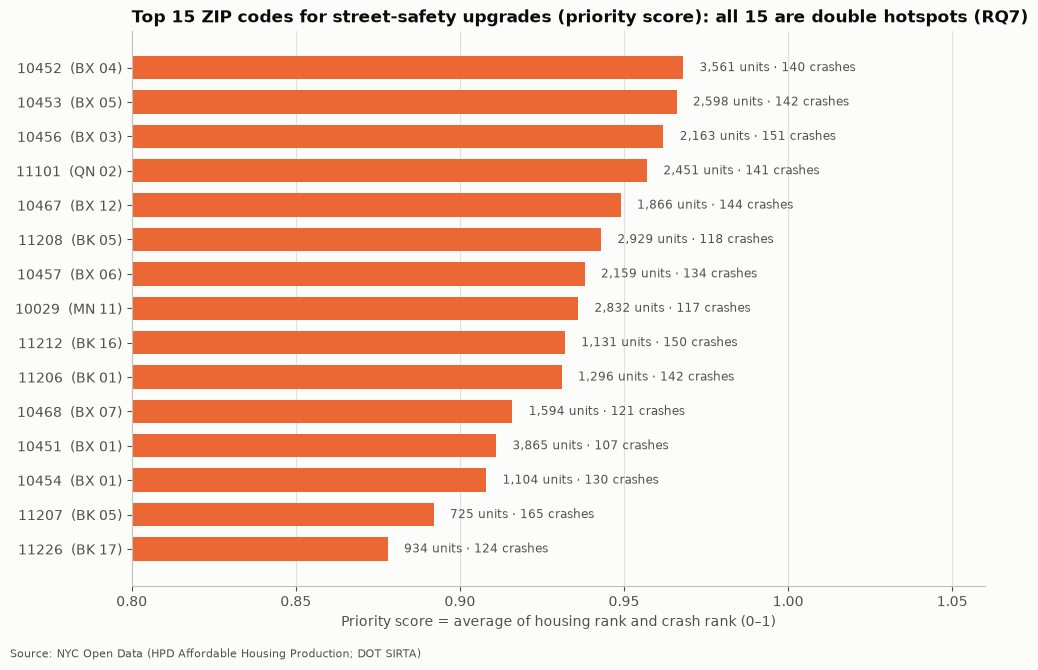

Top 15 by borough: {'Bronx': 8, 'Brooklyn': 5, 'Queens': 1, 'Manhattan': 1}


,zip_code,borough,community_district,affordable_units,serious_crashes,deaths,priority_score
62,10452,Bronx,BX 04,3561,140,13,0.968
63,10453,Bronx,BX 05,2598,142,5,0.966
66,10456,Bronx,BX 03,2163,151,5,0.962
89,11101,Queens,QN 02,2451,141,15,0.957
77,10467,Bronx,BX 12,1866,144,17,0.949
101,11208,Brooklyn,BK 05,2929,118,5,0.943
67,10457,Bronx,BX 06,2159,134,6,0.938
26,10029,Manhattan,MN 11,2832,117,8,0.936
105,11212,Brooklyn,BK 16,1131,150,6,0.932
99,11206,Brooklyn,BK 01,1296,142,8,0.931


In [100]:
zip_summary["housing_rank"] = zip_summary["affordable_units"].rank(pct=True)
zip_summary["crash_rank"] = zip_summary["serious_crashes"].rank(pct=True)
zip_summary["priority_score"] = ((zip_summary["housing_rank"] + zip_summary["crash_rank"]) / 2).round(3)
top15 = zip_summary.nlargest(15, "priority_score").iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh([f"{z}  ({cd})" for z, cd in zip(top15["zip_code"], top15["community_district"])],
        top15["priority_score"], color=ORANGE, height=0.68)
for i, (_, row) in enumerate(top15.iterrows()):
    ax.text(row["priority_score"] + 0.005, i, f"{row['affordable_units']:,} units · {row['serious_crashes']} crashes",
            va="center", fontsize=8.5, color=INK_SOFT)
ax.set_xlim(0.8, 1.06)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
all_double = (top15["hotspot_group"] == "Double hotspot").all()
finish_chart(ax, "Top 15 ZIP codes for street-safety upgrades (priority score)"
             + (": all 15 are double hotspots (RQ7)" if all_double else ""),
             "Priority score = average of housing rank and crash rank (0–1)", None)
plt.show()
top15_table = top15.iloc[::-1][["zip_code", "borough", "community_district", "affordable_units", "serious_crashes",
                                "deaths", "priority_score"]]
print("Top 15 by borough:", top15_table["borough"].value_counts().to_dict())
top15_table

**Answer:** the 15 ZIPs with the highest priority scores are **all double hotspots** from RQ7: 8 in the Bronx, 5 in Brooklyn, 1 in Queens (11101, Long Island City) and 1 in Manhattan (10029, East Harlem). The top three, **10452** (Highbridge/Concourse), **10453** (University Heights/Fordham) and **10456** (Morrisania), are neighbours in the West and South Bronx. Together, the 15 ZIPs received **31% of all new affordable units** (31,208) and recorded **18% of all serious crashes** (2,026 crashes, 129 deaths) in 2022–2025.

**What it means:** this is our recommendation to the city, a short ranked list where one street-safety programme would protect about a third of the residents of new affordable housing.

**Caution:** the score gives housing and crashes equal weight, and that is a choice. Weighting deaths instead of crashes would move 10467 (17 deaths, the most in the top 15) higher. The website lets users compare the ZIPs themselves.

### Summary of the 12 answers

| # | Short answer |
|---|---|
| RQ1 | **Yes.** ZIPs with more new affordable units have more serious crashes (ρ = 0.61). |
| RQ2 | **No year-to-year link.** Crashes are flat while completions swing; the link is about places, not years. |
| RQ3 | **Yes.** New-construction buildings are in ZIPs with 28% more serious crashes than preserved buildings, in every large borough. |
| RQ4 | **Partly.** Extremely-low-income units are in ZIPs 10% more dangerous than average; the pattern is not a straight line. |
| RQ5 | **Slightly.** Near new homes, crashes lean towards the evening (+4 points) and away from the morning peak. |
| RQ6 | **Yes, strongly.** 96% of serious crashes near new homes are on local streets (vs 90% elsewhere). |
| RQ7 | **26 double hotspots** (14% of ZIPs) received 43% of new affordable units, mostly in the Bronx and Brooklyn. |
| RQ8 | **Citywide yes, but mixed:** more repeat-danger spots near new homes in the Bronx and Manhattan, fewer in Brooklyn and Queens. |
| RQ9 | **Yes.** Mostly-family buildings have 16% fewer serious crashes within 250 m, in every large borough. |
| RQ10 | **High-growth ZIPs have the least deadly crashes** (6.9 vs about 9 deaths per 100), robust to our imputation choices. |
| RQ11 | **Slightly fewer (−3%)** after completion, except Manhattan (+17%). |
| RQ12 | **15 priority ZIPs**, 8 in the Bronx, hold 31% of new affordable units. |

---
# 11. Load: saving clean tables for the website *(M4)*
The **Load** step of ETL. The website does not repeat the cleaning: it reads these clean tables, so it starts quickly and stays inside the memory limit of a free hosting plan.

| File | One row is | Used for |
|---|---|---|
| `buildings_clean.csv` | an affordable building (all years) | housing filters, map, income bands |
| `crashes_clean.csv` | a serious crash, with its distance to new housing | crash filters, map, heatmap |
| `zip_year.csv` | a ZIP code in one year (Level A) | ZIP-level charts |
| `zip_summary.csv` | a ZIP code, 2022–2025 totals | map, scatter, ranking |
| `borough_year.csv` | a borough in one year (Level C) | trend charts |
| `housing_income_long.csv` | a building × income band (tidy table) | income-band chart |

In [101]:
BUILDING_EXPORT_COLUMNS = [
    "project_id", "building_id", "project_name", "is_confidential", "house_number", "street_name", "borough",
    "zip_code", "community_board", "community_district", "latitude", "longitude", "construction_type",
    "extended_affordability_only", "project_start_date", "building_completion_date", "completion_year", "start_year",
    "is_completed", "in_analysis_window", "total_units", "affordable_units", "rental_units", "homeownership_units",
    "deep_affordable_units", "family_units", "deep_affordable_share", "family_share", "is_large_building",
] + INCOME_BAND_COLUMNS
buildings_export = housing[BUILDING_EXPORT_COLUMNS].merge(
    new_buildings[["project_id", "building_id", "crashes_within_250m"]], on=["project_id", "building_id"], how="left")

crashes_export = crashes.merge(
    located_crashes[["crash_id", "distance_to_new_housing_m", "near_new_housing"]], on="crash_id", how="left")
crashes_export = crashes_export[[
    "crash_id", "crash_date", "crash_time", "year", "month", "weekday", "hour", "time_unknown", "borough", "precinct",
    "zip_code", "zip_source", "latitude", "longitude", "on_street", "cross_street", "severe_injuries", "fatalities",
    "non_severe_injuries", "people_seriously_hurt", "is_fatal", "on_highway", "similar_severe_3y", "at_repeat_location",
    "in_analysis_window", "distance_to_new_housing_m", "near_new_housing"]]

exports = {
    "buildings_clean.csv": buildings_export,
    "crashes_clean.csv": crashes_export,
    "zip_year.csv": zip_year,
    "zip_summary.csv": zip_summary,
    "borough_year.csv": borough_year,
    "housing_income_long.csv": housing_income_long,
}
for file_name, table in exports.items():
    table.to_csv(os.path.join(CLEAN_DIR, file_name), index=False)
    size_kb = os.path.getsize(os.path.join(CLEAN_DIR, file_name)) / 1024
    print(f"Saved {file_name:26s} {len(table):>6,} rows  {size_kb:>7,.0f} KB")

Saved buildings_clean.csv         9,551 rows    1,843 KB


Saved crashes_clean.csv          12,502 rows    2,056 KB
Saved zip_year.csv                  740 rows       39 KB
Saved zip_summary.csv               185 rows       27 KB
Saved borough_year.csv               20 rows        1 KB
Saved housing_income_long.csv    16,731 rows    1,053 KB


---
# 12. Story: Homes on Dangerous Streets? *(M6)*

### The question
New York City delivers about 25,000 affordable homes every year, built new or preserved. These homes go to the households who most depend on walking, buses and safe streets. **Are they being placed next to the city's most dangerous streets?**

### What the data shows
1. **Yes, affordable housing and serious crashes are concentrated in the same places.** ZIPs with more new affordable units have more serious crashes (RQ1). 26 "double hotspot" ZIPs, mostly in the South and West Bronx and central Brooklyn, received **43% of all new affordable units** (RQ7).
2. **Those most exposed are the newest and poorest residents.** New-construction buildings, where every household is new to the area, are in ZIPs with 28% more serious crashes than preserved buildings (RQ3). Extremely-low-income units are in ZIPs 10% more dangerous than average (RQ4).
3. **The danger is on local streets, in the evening.** 96% of serious crashes near new homes are on local streets, not highways (RQ6), and they lean towards the evening hours (RQ5). In the Bronx, more of them happen at spots that already had serious crashes before (RQ8).
4. **It is not getting worse because of the buildings.** Crashes did not rise with housing completions over the years (RQ2), and the year after a building opened was slightly safer than the year before (RQ11). Family buildings are on calmer blocks (RQ9). Crashes in high-growth areas are frequent but less often deadly (RQ10).

### So what? Three recommendations for NYC
1. **Link the housing pipeline to the street-safety pipeline.** When HPD finances a building in one of our 15 priority ZIPs (RQ12), DOT should review the surrounding streets *before* residents move in. These 15 ZIPs hold a third of all new affordable units.
2. **Fix known spots first.** In the Bronx, repeat-danger locations near new homes are a list DOT already has (RQ8). Local-street tools are cheap and fast (RQ6).
3. **Target the evening.** Speed enforcement, signal timing and lighting around residential blocks in the evening hours match when crashes near homes happen (RQ5).

### Honest limitations
- **Association, not cause.** Dense, busy neighbourhoods get both more housing and more crashes. We did not measure density, traffic volume or population, so we cannot say housing causes crashes or the reverse.
- **Only serious crashes.** SIRTA covers crashes with a severe injury or death, so we describe dangerous streets, not all traffic. Without traffic or population data we cannot compute rates *per person* or *per car*.
- **Missing locations.** Missing crash ZIPs were filled in two steps: from coordinates (92% accurate in our test) and, for crashes without coordinates, from the street and precinct (73% accurate). About 3% of crashes still have no ZIP and appear only in borough results. Coordinate coverage changes by year, which we corrected for in RQ11.
- **Fatal crashes have no published location after 2022.** Distance-based results (RQ5, RQ6, RQ8, RQ9, RQ11) therefore describe mainly severe-injury crashes. ZIP-level and borough-level results include all fatal crashes.
- **Confidential homes.** 1,949 small confidential buildings have no address. They are in borough totals but not in ZIP or distance results.
- **Our choices.** The 250 m radius, the 25% hotspot cut-off and the equal weights of the priority score are choices. We tested the radius (150 m and 500 m give the same conclusions), and the website lets users change the filters.
- **Preservation is not new residents.** Preserved units (52% of the total) keep existing tenants in place. One project (Co-op City, 15,507 units) is large enough to move some totals, which we point out wherever it matters.
- **Snapshot.** We used the data as published on 9 October 2026. Both datasets are updated regularly, so later downloads may differ slightly.

---
# 13. Team contributions *(M6)*

| Member | Research questions | Cleaning & integration | Website | Documentation |
|---|---|---|---|---|
| M1: Lead & Integration | RQ1, RQ2 | Extract (2), integration (8), post-integration cleaning (9) | Data loading for the app | GitHub repository |
| M2: Housing data | RQ3, RQ4 | Housing EDA (3), housing cleaning (5) | Housing filters | Housing markdown cells |
| M3: Transport data | RQ5, RQ6 | Crash EDA (4), crash cleaning and ZIP imputation (6) | Crash filters | Crash markdown cells |
| M4: Website logic | RQ7, RQ8 | Load step (11) | Callbacks, search parser, Generate Report button | Website section of README |
| M5: Website visuals & deployment | RQ9, RQ10 | Chart style and colours | Layout, charts, map, deployment on Render | Deployment guide |
| M6: Story & documentation | RQ11, RQ12 | Cleaning verification (7) | Story tab | Story (12), README, prompts log (14), final check |

*Every member reviewed the full notebook and can explain each step.*

---
# 14. Prompts log *(M6)*

The project rules ask us to include all prompts used. We used **Claude (Anthropic)** as an assistant for planning, dataset selection, code drafts and explanations. Every result in this notebook comes from the code above, which we ran and checked ourselves.

The full log, with every prompt word for word and what we used the answer for, is in [`docs/prompts_log.md`](docs/prompts_log.md). The prompts were:

| # | Date | Prompt (summary; full text in the log) | Used for |
|---|---|---|---|
| 1 | 9 Oct 2026 | Shared the project description and data catalog; asked for a careful analysis, a list of what was needed, and a work split for 6 members | Requirements checklist, team roles |
| 2 | 9 Oct 2026 | Asked the assistant to choose the easiest dataset pair and divide the roles | Dataset choice (H2 + T4) |
| 3 | 9 Oct 2026 | Shared Lectures 1–4 | Course methods and terms |
| 4–8 | 9 Oct 2026 | Shared Labs 1–4 one by one | Methods reused (EDA, cleaning, Dash, dashboard design) |
| 9 | 9 Oct 2026 | Asked the assistant to make all decisions for full marks | Final research questions and plan |
| 10 | 9 Oct 2026 | Uploaded the two raw CSV files from the API | Notebook and website |

*Members: add any prompt you send to an AI tool to `docs/prompts_log.md` before submission.*